# Projet IRM : classification et détection de tumeurs cérébrales

> **Projet pédagogique : ne constitue pas un outil de diagnostic médical.**

Ce notebook suit le pipeline du projet. Le code est dans `src/` (fonctions réutilisées par Airflow et Streamlit) ; le notebook sert à l'exécuter, le visualiser et documenter les décisions.

**Sommaire**
1. Exploration et préparation des données
2. Prétraitement et Data Augmentation
3. Classification par Transfer Learning
4. Prévention du surapprentissage
5. Détection avec YOLOv8
6. Évaluation des modèles
7. Automatisation (Airflow) · 8. Interface (Streamlit) · 9. Docker et tests

# 1. Exploration et préparation des données

**Objectif :** savoir exactement ce que contient le dataset, quelles images sont fiables, et produire un manifeste unique (une ligne par image) qui servira à tout le reste.

**Règle :** `data/raw/` n'est jamais modifié, sauf le nettoyage des fichiers parasites. Les décisions passent par des colonnes du manifeste, jamais par des suppressions.

## 1.0 Configuration
Active le rechargement automatique des modules `src/` (`%autoreload 2`), charge `configs/config.yaml` et définit le dossier des données brutes.

In [1]:
%load_ext autoreload
%autoreload 2

from src.utils import load_config, ROOT
from src.data import find_unexpected_files, build_inventory, summarize_inventory

cfg = load_config()
RAW = ROOT / cfg["paths"]["raw"]
print("Dossier brut :", RAW)

Dossier brut : /home/hammo/projects/IRM_detection/data/raw


## 1.1 Nettoyage des fichiers `:Zone.Identifier`
Résidus laissés par Windows lors de la copie : ils doublaient tous les comptages. Ils ont été supprimés en ligne de commande (opération ponctuelle, hors pipeline). Cette cellule vérifie qu'il ne reste aucun fichier autre qu'une image ou une annotation `.txt`.

**Attendu : 0 fichier inattendu.**

In [2]:
unexpected = find_unexpected_files(RAW)
print(f"Fichiers inattendus : {len(unexpected)}")
unexpected[:5]

Fichiers inattendus : 0


[]

## 1.2 Inventaire et correspondance image ↔ annotation
Une ligne par (split, classe, nom de fichier). L'association se fait par le **nom sans extension** (convention YOLO). Les chemins sont relatifs à la racine du projet pour fonctionner aussi dans Docker.

**Résultat :** 5 251 lignes, dont 5 247 couples image + annotation et 4 orphelins, tous dans `Val/No Tumor`.

In [3]:
inv = build_inventory(RAW)
table, orphans = summarize_inventory(inv)

print(f"Lignes dans l'inventaire : {len(inv)}")
display(table)
print(f"Orphelins (image sans label ou label sans image) : {len(orphans)}")
orphans.head()

Lignes dans l'inventaire : 5251


split_origin,Train,Val,Total
class,,,
Glioma,1153,136,1289
Meningioma,1449,140,1589
No Tumor,711,102,813
Pituitary,1424,136,1560
Total,4737,514,5251


Orphelins (image sans label ou label sans image) : 4


,split_origin,class,stem,image_path,label_path,has_image,has_label
5106,Val,No Tumor,image(53),NaN,data/raw/Val/No Tumor/labels/image(53).txt,False,True
5107,Val,No Tumor,image(55),data/raw/Val/No Tumor/images/image(55).jpg,NaN,True,False
5108,Val,No Tumor,image(60),NaN,data/raw/Val/No Tumor/labels/image(60).txt,False,True
5109,Val,No Tumor,image(61),data/raw/Val/No Tumor/images/image(61).jpg,NaN,True,False


### Les 4 orphelins

| Nom | Existe | Manque |
|---|---|---|
| `image(53)`, `image(60)` | annotation | image |
| `image(55)`, `image(61)` | image | annotation |

Les numéros ne se correspondent pas (pas de décalage régulier) : aucune réassociation n'est possible sans preuve, et une mauvaise association empoisonnerait la détection.

**Décision :**
- images orphelines : **gardées pour la classification**, exclues de la détection ;
- annotations orphelines : **exclues** ;
- rien n'est supprimé du disque ; la décision est portée par la colonne `status` du manifeste.

**Observation :** ces deux annotations de `No Tumor` portent la classe `2` avec de grandes boîtes. `No Tumor` n'est peut-être pas « sans annotation » : à vérifier à l'étape 1.5.

image(53) -> '2 0.506818 0.494545 0.913636 0.930909\n'
image(60) -> '2 0.502119 0.514831 0.572034 0.682203\n'
['image(55).jpg', 'image(61).jpg']


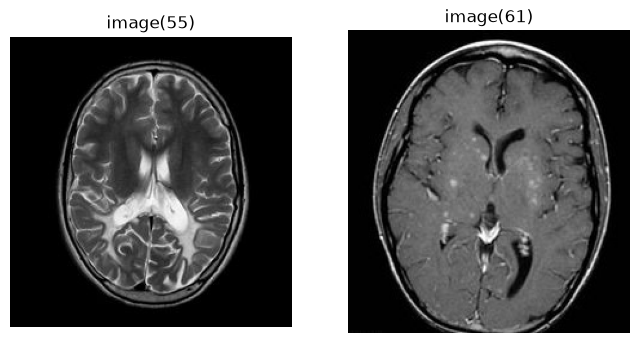

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# 1) Contenu des deux annotations sans image
for stem in ["image(53)", "image(60)"]:
    p = ROOT / f"data/raw/Val/No Tumor/labels/{stem}.txt"
    print(stem, "->", repr(p.read_text()))

# 2) Fichiers voisins (pour repérer une faute de numérotation)
img_dir = ROOT / "data/raw/Val/No Tumor/images"
print(sorted(p.name for p in img_dir.iterdir() if any(f"({n})" in p.name for n in (52, 53, 54, 55, 59, 60, 61, 62))))

# 3) Les deux images sans annotation
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, stem in zip(axes, ["image(55)", "image(61)"]):
    ax.imshow(Image.open(img_dir / f"{stem}.jpg"), cmap="gray")
    ax.set_title(stem)
    ax.axis("off")
plt.show()

Code (find_unexpected_files)

## 1.3 Distribution des classes
**Pourquoi :** un déséquilibre rend l'accuracy trompeuse, impose un découpage stratifié et influence le choix des métriques. Seules les images sont comptées (les 2 annotations orphelines sont exclues).

status
ok              5247
orphan_label       2
orphan_image       2
Name: count, dtype: int64


split_origin,Train,Val
class,,
Glioma,1153,136
Meningioma,1449,140
No Tumor,711,100
Pituitary,1424,136


split_origin,Train,Val
class,,
Glioma,24.3,26.6
Meningioma,30.6,27.3
No Tumor,15.0,19.5
Pituitary,30.1,26.6


Rapport classe max / classe min (Train) : 2.04


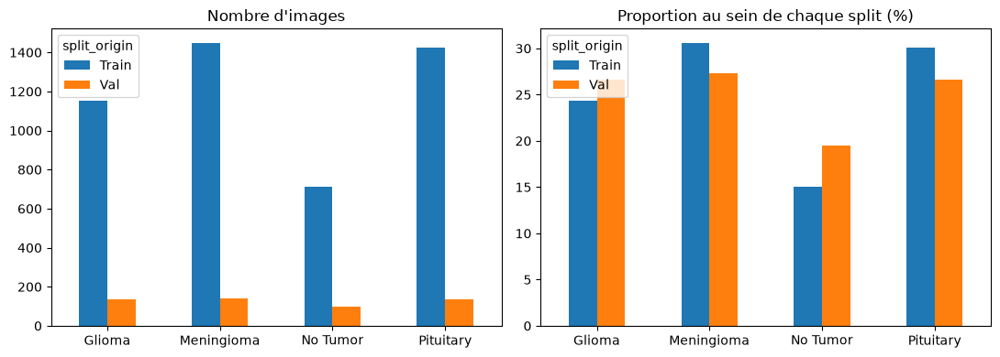

In [5]:
from src.data import add_status, class_distribution, plot_class_distribution

inv = add_status(inv)
print(inv["status"].value_counts())

counts, pct = class_distribution(inv)
display(counts)
display(pct)
print("Rapport classe max / classe min (Train) :",
      round(counts["Train"].max() / counts["Train"].min(), 2))

plot_class_distribution(counts, pct, ROOT / cfg["paths"]["figures"] / "class_distribution.png")


**Résultats**

| Classe | Train | Val |
|---|---|---|
| Glioma | 1153 (24,3 %) | 136 (26,6 %) |
| Meningioma | 1449 (30,6 %) | 140 (27,3 %) |
| No Tumor | 711 (15,0 %) | 100 (19,5 %) |
| Pituitary | 1424 (30,1 %) | 136 (26,6 %) |

Rapport classe max / classe min dans Train : **2,04** → déséquilibre modéré.

**Conclusions**
- Découpage stratifié obligatoire.
- Métrique principale : F1 macro + rappel par classe (l'accuracy seule serait insuffisante).
- `No Tumor` pèse 15 % de Train contre 19,5 % de Val : les scores de Val ne sont pas strictement comparables à ceux de Train.
- Méthode de compensation (poids de classes ou autre) : décision au Jour 3.

## 1.4 Intégrité et propriétés des images
Chaque image est ouverte et **entièrement décodée** (cela détecte les fichiers tronqués). On relève le format réel, le mode (L, RGB, RGBA, P), les dimensions et le poids.

**Pourquoi :** un fichier corrompu ferait échouer l'entraînement en cours de route ; le mode décide de la conversion en 3 canaux (MobileNetV2) ; les dimensions décident du redimensionnement ; et on cherche si une classe se distingue par ses propriétés techniques (raccourci).

In [6]:
import pandas as pd
from src.data import check_images

props = check_images(inv)
print("Images analysées        :", len(props))
print("Illisibles              :", (~props.readable).sum())
print("Extension ≠ format réel :", (props.readable & ~props.ext_ok).sum())
props[~props.readable].head()

Images analysées        : 5249
Illisibles              : 0
Extension ≠ format réel : 4


,image_path,readable,error,format,mode,width,height,ext_ok,size_kb


In [7]:
ok = props[props.readable].astype({"width": int, "height": int})
m = ok.merge(inv[["image_path", "class", "split_origin"]], on="image_path")
m["size"] = m["width"].astype(str) + "x" + m["height"].astype(str)

print("Formats :"); display(ok["format"].value_counts())
print("Mode par classe :"); display(pd.crosstab(m["mode"], m["class"]))
print("Dimensions les plus fréquentes, par classe :")
display(pd.crosstab(m["size"], m["class"])
        .assign(total=lambda d: d.sum(axis=1))
        .sort_values("total", ascending=False).head(10))
display(ok[["width", "height", "size_kb"]].describe().round(1))

Formats :


format
JPEG    5245
PNG        4
Name: count, dtype: int64

Mode par classe :


class,Glioma,Meningioma,No Tumor,Pituitary
mode,,,,
L,470,292,15,221
P,0,0,1,0
RGB,819,1297,792,1339
RGBA,0,0,3,0


Dimensions les plus fréquentes, par classe :


class,Glioma,Meningioma,No Tumor,Pituitary,total
size,,,,,
512x512,1289,1386,16,1515,4206
225x225,0,10,109,0,119
630x630,0,0,66,0,66
442x442,0,7,34,1,42
236x236,0,0,33,0,33
256x256,0,2,1,22,25
201x251,0,3,20,0,23
201x250,0,0,22,0,22
214x236,0,0,18,0,18


,width,height,size_kb
count,5249.0,5249.0,5249.0
mean,481.9,484.5,26.1
std,106.1,100.1,15.0
min,150.0,168.0,3.6
25%,512.0,512.0,19.5
50%,512.0,512.0,25.0
75%,512.0,512.0,30.4
max,1375.0,1446.0,299.3


**Résultats**
- 5 249 images analysées, **0 illisible**.
- 4 fichiers `.jpg` sont en réalité des PNG (probablement les 4 images en mode `P` / `RGBA` de `No Tumor`).
- Modes : majorité en RGB, 998 images en niveaux de gris (`L`) → conversion systématique en RGB 3 canaux.
- **Dimensions fortement liées à la classe :**

| Classe | Part des images en 512×512 |
|---|---|
| Glioma | 100 % |
| Pituitary | 97 % |
| Meningioma | 87 % |
| No Tumor | 2 % |

76 % des images qui ne sont pas en 512×512 sont des `No Tumor` (795 sur 1 043).

**Interprétation :** les classes tumorales viennent d'une source quasi uniforme, `No Tumor` de sources hétérogènes. **Risque de raccourci** : le modèle pourrait reconnaître la source au lieu de la tumeur. Mesuré à l'étape 1.4b.

## 1.4b Contrôles complémentaires sur les propriétés
- Identifier les 4 « faux JPG » (PNG) et vérifier qu'ils correspondent aux modes rares.
- Compter les images non carrées par classe (le redimensionnement les déformera si on force un carré).

In [8]:
# 1) Les PNG déguisés en .jpg
display(m.loc[m["format"] == "PNG", ["image_path", "class", "mode", "size"]])

# 2) Images non carrées, par classe
print("Images non carrées par classe :")
display((m["width"] != m["height"]).groupby(m["class"]).sum())

,image_path,class,mode,size
2892,data/raw/Train/No Tumor/images/Tr-no_1011.jpg,No Tumor,RGBA,550x664
2893,data/raw/Train/No Tumor/images/Tr-no_1012.jpg,No Tumor,P,728x725
2898,data/raw/Train/No Tumor/images/Tr-no_1019.jpg,No Tumor,RGBA,393x400
2899,data/raw/Train/No Tumor/images/Tr-no_1020.jpg,No Tumor,RGBA,442x454


Images non carrées par classe :


class
Glioma          0
Meningioma    174
No Tumor      513
Pituitary      10
dtype: int64

## 1.4c Test du raccourci : peut-on deviner la classe sans voir l'image ?
On entraîne un arbre de décision minuscule (profondeur 4) sur les **seules métadonnées du fichier** (largeur, hauteur, ratio, poids, mode), sans aucun pixel. Ce n'est pas un modèle du projet, c'est un **thermomètre**.

- Si `No Tumor` est retrouvé avec un fort rappel et une bonne précision, la classe est trahie par la source.
- Si les résultats restent proches du hasard, le risque est faible.

On regarde aussi les **familles de noms de fichiers** (`Tr-gl_#`, `gg (#)`, `image(#)`, ...), qui renseignent sur l'origine des images.

**Limite :** la validation croisée peut être légèrement optimiste si des doublons existent (étape 1.7).

In [9]:
from src.data import metadata_baseline, name_pattern

res = metadata_baseline(m)
print(f"Accuracy métadonnées seules : {res['accuracy']}")
print(f"Référence (toujours la classe majoritaire) : {res['majority_baseline']}\n")
print(res["report"])

inv["name_pattern"] = inv["stem"].map(name_pattern)
display(pd.crosstab(inv["name_pattern"], inv["class"])
        .assign(total=lambda d: d.sum(axis=1))
        .sort_values("total", ascending=False).head(15))

Accuracy métadonnées seules : 0.644
Référence (toujours la classe majoritaire) : 0.303

              precision    recall  f1-score   support

      Glioma       0.56      0.50      0.53      1289
  Meningioma       0.52      0.42      0.46      1589
    No Tumor       0.84      0.92      0.88       811
   Pituitary       0.69      0.85      0.76      1560

    accuracy                           0.64      5249
   macro avg       0.65      0.67      0.66      5249
weighted avg       0.63      0.64      0.63      5249



class,Glioma,Meningioma,No Tumor,Pituitary,total
name_pattern,,,,,
p (#),0,0,0,822,822
Tr-me_#,0,774,0,0,774
gg (#),727,0,0,0,727
Tr-pi_#,0,0,0,695,695
Tr-no_#,0,0,478,0,478
Tr-gl_#,457,0,0,0,457
m# (#),0,418,0,0,418
image(#),0,0,269,0,269
m (#),0,200,0,0,200


**Résultats 1.4b**
- Les 4 faux JPG sont des PNG, tous dans `Train/No Tumor` (`Tr-no_1011`, `1012`, `1019`, `1020`) : ce sont les images en mode `P` / `RGBA`. Elles seront lues par leur contenu et converties en RGB.
- Images non carrées : Glioma 0, Meningioma 174, No Tumor 513, Pituitary 10. 63 % des `No Tumor` ne sont pas carrées, contre environ 4 % des autres classes.

**Résultats 1.4c**
- Avec les seules métadonnées de fichier : accuracy **0,644** (référence : 0,303). `No Tumor` : précision 0,84, rappel 0,92. Pituitary : rappel 0,85. Glioma et Meningioma restent proches du hasard entre eux.
- **Le risque de raccourci est réel.** Le signal ne vient pas que de `No Tumor` : le poids du fichier et le mode contribuent probablement (contrôle en 1.4d).
- Les familles de noms sont **pures** : chaque famille n'appartient qu'à une seule classe. Classe et source sont presque totalement confondues, donc un test sur une source jamais vue est impossible sans retirer une classe. **Limite à documenter.**


## 1.4d Quelle propriété trahit la classe ?
On refait le test du thermomètre en retirant des colonnes pour isoler la source du signal :
- **dimensions seules** : indice purement lié à la source ;
- **poids du fichier seul** : ambigu (source *ou* contenu) ;
- **sans le poids** : que reste-t-il quand on enlève la variable ambiguë ?

On regarde aussi comment les familles de noms se répartissent entre `Train` et `Val`, pour savoir si `Val` est une tranche des mêmes sources ou une source indépendante.

In [10]:
# CE QUE FAIT CETTE CELLULE (étape 1.4d)
# 1) Relance le "thermomètre" (arbre de décision sur métadonnées, sans pixels)
#    avec 4 jeux de colonnes différents, pour isoler la propriété qui trahit la classe.
#    On compare l'accuracy et le rappel de chaque classe.
# 2) Croise les familles de noms de fichiers avec le split d'origine (Train / Val)
#    pour savoir si Val reprend les mêmes sources que Train.
# Aucune donnée n'est modifiée : c'est une cellule d'analyse.

variants = {
    "toutes les métadonnées":   ("width", "height", "aspect", "size_kb", "mode"),
    "sans le poids du fichier": ("width", "height", "aspect", "mode"),
    "dimensions seules":        ("width", "height", "aspect"),
    "poids du fichier seul":    ("size_kb",),
}

rows = []
for name, feats in variants.items():
    r = metadata_baseline(m, features=feats)
    rows.append({"variante": name, "accuracy": r["accuracy"],
                 **{f"rappel {c}": v for c, v in r["recall"].items()}})
display(pd.DataFrame(rows))

imgs = inv[inv.has_image]
display(pd.crosstab(imgs["name_pattern"], imgs["split_origin"])
        .assign(total=lambda d: d.sum(axis=1))
        .sort_values("total", ascending=False).head(15))

,variante,accuracy,rappel Glioma,rappel Meningioma,rappel No Tumor,rappel Pituitary
0,toutes les métadonnées,0.644,0.50,0.42,0.92,0.85
1,sans le poids du fichier,0.496,0.36,0.05,0.91,0.84
2,dimensions seules,0.448,0.00,0.05,0.91,0.98
3,poids du fichier seul,0.553,0.51,0.41,0.54,0.74


split_origin,Train,Val,total
name_pattern,,,
p (#),813,9,822
Tr-me_#,735,39,774
gg (#),642,85,727
Tr-pi_#,576,119,695
Tr-no_#,445,33,478
Tr-gl_#,406,51,457
m# (#),384,34,418
image(#),208,59,267
m (#),156,44,200


**Résultats 1.4d**

| Variante | Accuracy | Rappel Glioma | Meningioma | No Tumor | Pituitary |
|---|---|---|---|---|---|
| toutes les métadonnées | 0,644 | 0,50 | 0,42 | 0,92 | 0,85 |
| sans le poids du fichier | 0,496 | 0,36 | 0,05 | 0,91 | 0,84 |
| dimensions seules | 0,448 | 0,00 | 0,05 | 0,91 | 0,98 |
| poids du fichier seul | 0,553 | 0,51 | 0,41 | 0,54 | 0,74 |

**Lecture**
- Les **dimensions seules** repèrent `No Tumor` (rappel 0,91) : signal pur de source. Le 0,98 de Pituitary et le 0,00 de Glioma sont un artefact : ces trois classes sont presque toutes en 512×512, et l'arbre les range dans la plus fréquente.
- Le **mode** (niveaux de gris ou RGB) apporte un signal faible entre classes tumorales : 36 % de niveaux de gris pour Glioma, 18 % Meningioma, 14 % Pituitary, 2 % No Tumor.
- Le **poids du fichier** distingue même Glioma et Meningioma (mêmes dimensions) : source ou contenu, on ne peut pas trancher.

**Familles de noms entre Train et Val** : `Val` n'est pas un échantillon aléatoire des mêmes sources que `Train`. Exemples : `p (#)` = 57 % des Pituitary de Train mais 7 % de Val ; `image(#)` = 29 % des No Tumor de Train mais 59 % de Val. Glioma est le seul cas équilibré. L'hypothèse « `Tr-` / `Te-` = ancien découpage train/test » n'est pas confirmée.

**Conséquences**
1. Un écart Train/Val peut venir du changement de sources et pas seulement du surapprentissage (à garder en tête pour lire les courbes).
2. Un test prélevé dans Train aura le mélange de sources de Train : on le stratifiera par classe **et** par famille (décision à l'étape 1.9).
3. `Val` ne protège pas contre le raccourci : à surveiller par sous-groupes et par Grad-CAM.
4. Atténuations à décider au Jour 2 : mode uniforme (3 canaux), choix du redimensionnement, augmentations qui brouillent la source. **Limite à documenter dans le README.**

## 1.5 Vérification des annotations
Lecture de chaque fichier `.txt` pour vérifier : le format (5 valeurs = boîte, plus = polygone), les valeurs (dans [0, 1], largeur et hauteur > 0), les boîtes qui sortent de l'image, les fichiers vides et les boîtes en double.

Seuls les 5 247 couples image + annotation valides sont analysés (`status == "ok"`).

**Cette étape ne modifie rien** : les problèmes détectés deviendront des colonnes du manifeste.

In [11]:
# CE QUE FAIT CETTE CELLULE (étape 1.5, contrôle du format et de la géométrie)
# Lit chaque annotation .txt des couples valides et construit deux tableaux :
#   - boxes : une ligne par boîte (classe, cx, cy, w, h, aire, problèmes éventuels)
#   - files : une ligne par fichier (nombre de boîtes, problèmes de format, doublons)
# Puis affiche les problèmes détectés. Rien n'est modifié sur le disque.
from src.data import build_annotation_tables

ok = inv[inv.status == "ok"]
boxes, files = build_annotation_tables(ok)

print(f"Fichiers d'annotation lus : {len(files)}   |   boîtes lues : {len(boxes)}")
print(f"Fichiers vides : {(files.n_boxes == 0).sum()}")
print(f"Fichiers avec problème de format : {(files.format_issues != '').sum()}")
print(f"Fichiers avec boîtes en double : {files.duplicate_boxes.sum()}")
print("\nBoîtes selon leur problème géométrique :")
display(boxes["flags"].replace("", "OK").value_counts())

Fichiers d'annotation lus : 5247   |   boîtes lues : 5871
Fichiers vides : 1
Fichiers avec problème de format : 0
Fichiers avec boîtes en double : 0

Boîtes selon leur problème géométrique :


flags
OK    5871
Name: count, dtype: int64

## 1.5b Identifiant de classe et nombre de boîtes
- **Identifiant de classe contre dossier**, par split : on suppose Glioma=0, Meningioma=1, No Tumor=2, Pituitary=3 (ordre alphabétique) mais on le mesure.
- **Nombre de boîtes par fichier** : combien de fichiers vides, combien avec une seule boîte, plusieurs ? Cela décidera du sort de `No Tumor` dans YOLO.

In [12]:
# CE QUE FAIT CETTE CELLULE (étape 1.5b, correspondance classe/dossier et nombre de boîtes)
# 1) Croise le dossier d'origine (Glioma, ...) avec l'identifiant de classe écrit dans
#    l'annotation, séparément pour Train et Val : on voit si la numérotation est la même.
# 2) Compte le nombre de fichiers par nombre de boîtes (0, 1, 2, 3, 4 ou plus), par classe.
print("Identifiant de classe trouvé dans les annotations, par dossier et par split :")
display(pd.crosstab([boxes["split_origin"], boxes["class"]], boxes["class_id"]))

nb = files["n_boxes"].clip(upper=4).astype(str).replace("4", "4+")
print("Nombre de fichiers selon leur nombre de boîtes :")
display(pd.crosstab(files["class"], nb))

Identifiant de classe trouvé dans les annotations, par dossier et par split :


class_id                    0     1    2     3
split_origin class                            
Train        Glioma      1347     3    0   152
             Meningioma     2  1478    0   103
             No Tumor       0     0  711     0
             Pituitary      0     1    0  1520
Val          Glioma       153     0    0    12
             Meningioma     0   142    0     6
             No Tumor       0     0   98     0
             Pituitary      0     0    0   143

Nombre de fichiers selon leur nombre de boîtes :


n_boxes,0,1,2,3,4+
class,,,,,
Glioma,1,971,265,42,10
Meningioma,0,1459,122,6,2
No Tumor,0,809,0,0,0
Pituitary,0,1458,100,2,0


## 1.5c Taille des boîtes
Part de l'image couverte par chaque boîte (`w × h`, entre 0 et 1), par classe. On cherche surtout si les boîtes de `No Tumor` couvrent presque toute l'image : ce serait alors « le cerveau entier » et non une localisation.

In [13]:
# CE QUE FAIT CETTE CELLULE (étape 1.5c, taille des boîtes)
# Résume la part de l'image couverte par les boîtes, par classe (min, médiane, 5e et 95e
# percentiles, max), et la proportion de boîtes qui couvrent plus de 80 % de l'image.
print("Part de l'image couverte par les boîtes (1.0 = toute l'image) :")
display(boxes.groupby("class")["area"].describe(percentiles=[.05, .5, .95]).round(3))

print("Proportion de boîtes couvrant plus de 80 % de l'image, par classe :")
display((boxes["area"] > 0.8).groupby(boxes["class"]).mean().round(3))

Part de l'image couverte par les boîtes (1.0 = toute l'image) :


,count,mean,std,min,5%,50%,95%,max
class,,,,,,,,
Glioma,1667.0,0.020,0.016,0.000,0.003,0.016,0.052,0.107
Meningioma,1731.0,0.032,0.026,0.001,0.004,0.025,0.079,0.184
No Tumor,809.0,0.641,0.157,0.135,0.404,0.620,0.908,0.991
Pituitary,1664.0,0.012,0.009,0.000,0.004,0.010,0.028,0.067


Proportion de boîtes couvrant plus de 80 % de l'image, par classe :


class
Glioma        0.00
Meningioma    0.00
No Tumor      0.19
Pituitary     0.00
Name: area, dtype: float64

## 1.5 Vérification des annotations
Lecture de chaque fichier `.txt` pour vérifier : le format (5 valeurs = boîte, plus = polygone), les valeurs (dans [0, 1], largeur et hauteur > 0), les boîtes qui sortent de l'image, les fichiers vides et les boîtes en double.

Seuls les 5 247 couples image + annotation valides sont analysés (`status == "ok"`).

**Cette étape ne modifie rien** : les problèmes détectés deviendront des colonnes du manifeste.

In [14]:
# CE QUE FAIT CETTE CELLULE (étape 1.5, contrôle du format et de la géométrie)
# Lit chaque annotation .txt des couples valides et construit deux tableaux :
#   - boxes : une ligne par boîte (classe, cx, cy, w, h, aire, problèmes éventuels)
#   - files : une ligne par fichier (nombre de boîtes, problèmes de format, doublons)
# Puis affiche les problèmes détectés. Rien n'est modifié sur le disque.
from src.data import build_annotation_tables

ok = inv[inv.status == "ok"]
boxes, files = build_annotation_tables(ok)

print(f"Fichiers d'annotation lus : {len(files)}   |   boîtes lues : {len(boxes)}")
print(f"Fichiers vides : {(files.n_boxes == 0).sum()}")
print(f"Fichiers avec problème de format : {(files.format_issues != '').sum()}")
print(f"Fichiers avec boîtes en double : {files.duplicate_boxes.sum()}")
print("\nBoîtes selon leur problème géométrique :")
display(boxes["flags"].replace("", "OK").value_counts())

Fichiers d'annotation lus : 5247   |   boîtes lues : 5871
Fichiers vides : 1
Fichiers avec problème de format : 0
Fichiers avec boîtes en double : 0

Boîtes selon leur problème géométrique :


flags
OK    5871
Name: count, dtype: int64

## 1.5b Identifiant de classe et nombre de boîtes
- **Identifiant de classe contre dossier**, par split : on suppose Glioma=0, Meningioma=1, No Tumor=2, Pituitary=3 (ordre alphabétique) mais on le mesure.
- **Nombre de boîtes par fichier** : combien de fichiers vides, combien avec une seule boîte, plusieurs ? Cela décidera du sort de `No Tumor` dans YOLO.

In [15]:
# CE QUE FAIT CETTE CELLULE (étape 1.5b, correspondance classe/dossier et nombre de boîtes)
# 1) Croise le dossier d'origine (Glioma, ...) avec l'identifiant de classe écrit dans
#    l'annotation, séparément pour Train et Val : on voit si la numérotation est la même.
# 2) Compte le nombre de fichiers par nombre de boîtes (0, 1, 2, 3, 4 ou plus), par classe.
print("Identifiant de classe trouvé dans les annotations, par dossier et par split :")
display(pd.crosstab([boxes["split_origin"], boxes["class"]], boxes["class_id"]))

nb = files["n_boxes"].clip(upper=4).astype(str).replace("4", "4+")
print("Nombre de fichiers selon leur nombre de boîtes :")
display(pd.crosstab(files["class"], nb))

Identifiant de classe trouvé dans les annotations, par dossier et par split :


class_id                    0     1    2     3
split_origin class                            
Train        Glioma      1347     3    0   152
             Meningioma     2  1478    0   103
             No Tumor       0     0  711     0
             Pituitary      0     1    0  1520
Val          Glioma       153     0    0    12
             Meningioma     0   142    0     6
             No Tumor       0     0   98     0
             Pituitary      0     0    0   143

Nombre de fichiers selon leur nombre de boîtes :


n_boxes,0,1,2,3,4+
class,,,,,
Glioma,1,971,265,42,10
Meningioma,0,1459,122,6,2
No Tumor,0,809,0,0,0
Pituitary,0,1458,100,2,0


## 1.5c Taille des boîtes
Part de l'image couverte par chaque boîte (`w × h`, entre 0 et 1), par classe. On cherche surtout si les boîtes de `No Tumor` couvrent presque toute l'image : ce serait alors « le cerveau entier » et non une localisation.

In [16]:
# CE QUE FAIT CETTE CELLULE (étape 1.5c, taille des boîtes)
# Résume la part de l'image couverte par les boîtes, par classe (min, médiane, 5e et 95e
# percentiles, max), et la proportion de boîtes qui couvrent plus de 80 % de l'image.
print("Part de l'image couverte par les boîtes (1.0 = toute l'image) :")
display(boxes.groupby("class")["area"].describe(percentiles=[.05, .5, .95]).round(3))

print("Proportion de boîtes couvrant plus de 80 % de l'image, par classe :")
display((boxes["area"] > 0.8).groupby(boxes["class"]).mean().round(3))

Part de l'image couverte par les boîtes (1.0 = toute l'image) :


,count,mean,std,min,5%,50%,95%,max
class,,,,,,,,
Glioma,1667.0,0.020,0.016,0.000,0.003,0.016,0.052,0.107
Meningioma,1731.0,0.032,0.026,0.001,0.004,0.025,0.079,0.184
No Tumor,809.0,0.641,0.157,0.135,0.404,0.620,0.908,0.991
Pituitary,1664.0,0.012,0.009,0.000,0.004,0.010,0.028,0.067


Proportion de boîtes couvrant plus de 80 % de l'image, par classe :


class
Glioma        0.00
Meningioma    0.00
No Tumor      0.19
Pituitary     0.00
Name: area, dtype: float64

**Résultats 1.5, 1.5b et 1.5c**

**Format et géométrie**
- 5 247 fichiers d'annotation lus, 5 871 boîtes. Aucun polygone, aucun problème de format, aucune valeur hors de [0, 1], aucune boîte hors image, aucun doublon. **Aucune conversion n'est nécessaire** pour YOLO.
- 1 seul fichier vide (une annotation de Glioma).

**Numérotation des classes** (identique dans Train et Val) : Glioma=0, Meningioma=1, No Tumor=2, Pituitary=3.

**Boîtes dont la classe ne correspond pas au dossier : 279 sur 5 871 (4,8 %)**
- Glioma : 167 sur 1 667 (164 en classe 3, 3 en classe 1)
- Meningioma : 111 sur 1 731 (109 en classe 3, 2 en classe 0)
- Pituitary : 1 sur 1 664 ; No Tumor : 0
- Cause inconnue (plusieurs lésions ou erreurs d'annotation). À examiner par fichier en 1.5d, puis visuellement.

**No Tumor n'est pas « sans annotation »** : les 809 fichiers valides ont exactement une boîte de classe 2, de taille médiane 62 % de l'image (19 % > 80 %).

| Classe | Part médiane de l'image | Maximum |
|---|---|---|
| Pituitary | 1,0 % | 6,7 % |
| Glioma | 1,6 % | 10,7 % |
| Meningioma | 2,5 % | 18,4 % |
| No Tumor | 62 % | 99 % |

La boîte `No Tumor` n'est pas une localisation de lésion (probablement « tout le cerveau »). **Décision provisoire pour YOLO : exclure `No Tumor` des classes détectées (3 classes)**, à confirmer après visualisation.

Les tumeurs sont de petits objets (Pituitary médiane ≈ 51×51 px sur 512×512) : à prendre en compte pour la taille d'image et les augmentations au Jour 5.

## 1.5d Cohérence entre le dossier et les boîtes, par fichier
Les chiffres précédents comptent des **boîtes**. Ici on classe chaque **fichier** :
- `all_match` : toutes les boîtes ont la classe du dossier ;
- `mixed` : au moins une boîte de la classe du dossier et au moins une d'une autre classe ;
- `none_match` : aucune boîte n'a la classe du dossier ;
- `no_box` : fichier vide.

On identifie aussi le fichier vide. Cela mesure l'ampleur du problème avant de décider du traitement.

In [17]:
# CE QUE FAIT CETTE CELLULE (étape 1.5d, cohérence dossier / boîtes par fichier)
# Pour chaque fichier d'annotation, compare la classe de chaque boîte à celle du dossier
# et range le fichier dans une catégorie (all_match, mixed, none_match, no_box).
# Affiche le résultat par split et par classe, puis le(s) fichier(s) vide(s).
# Aucune donnée n'est modifiée.
from src.data import label_consistency

cons = label_consistency(boxes, files)
display(pd.crosstab([cons["split_origin"], cons["class"]], cons["consistency"], margins=True))

print("Fichier(s) sans aucune boîte :")
display(cons.loc[cons.consistency == "no_box", ["label_path", "class", "split_origin"]])

consistency              all_match  mixed  no_box  none_match   All
split_origin class                                                 
Train        Glioma           1000    150       0           3  1153
             Meningioma       1349     89       0          11  1449
             No Tumor          711      0       0           0   711
             Pituitary        1423      0       0           1  1424
Val          Glioma            123     12       1           0   136
             Meningioma        134      6       0           0   140
             No Tumor           98      0       0           0    98
             Pituitary         136      0       0           0   136
All                           4974    257       1          15  5247

Fichier(s) sans aucune boîte :


,label_path,class,split_origin
4824,data/raw/Val/Glioma/labels/gg (342).txt,Glioma,Val


**Résultats 1.5d : cohérence dossier / boîtes, par fichier**

| Catégorie | Nombre | Part |
|---|---|---|
| `all_match` (toutes les boîtes correspondent au dossier) | 4 974 | 94,8 % |
| `mixed` (boîte du bon type + au moins une d'un autre type) | 257 | 4,9 % |
| `none_match` (aucune boîte ne correspond au dossier) | 15 | 0,3 % |
| `no_box` (fichier vide) | 1 | 0,02 % |

- `mixed` : surtout dans Glioma (150 en Train, 12 en Val) et Meningioma (89 en Train, 6 en Val), jamais dans No Tumor.
- `none_match` : 3 Glioma, 11 Meningioma, 1 Pituitary (tous en Train).
- Fichier vide : `Val/Glioma/gg (342).txt`.

**Règles provisoires** (aucune suppression sur disque, décisions portées par des colonnes du manifeste)
- `all_match` : utilisé en classification et en détection.
- `mixed` : gardé en classification (étiquette = dossier) et en détection (boîtes inchangées) ; on examinera leur effet sur les résultats.
- `none_match` (15) : mis de côté en attendant une inspection visuelle image par image.
- Fichier vide : classification oui, détection non.

**Limite :** nous ne pouvons pas établir la vérité médicale ; nous appliquons une règle documentée.

## 1.6 Visualisation des boîtes
On dessine les rectangles sur des images pour vérifier **à l'œil** ce que les chiffres ne montrent pas : les rectangles sont-ils bien placés sur la zone ? (un décalage centre/coin serait invisible dans les statistiques.)

**Couleurs :** rouge = Glioma, jaune = Meningioma, cyan = No Tumor, vert = Pituitary.

**1.6a** : 4 images au hasard par classe (une ligne par classe).

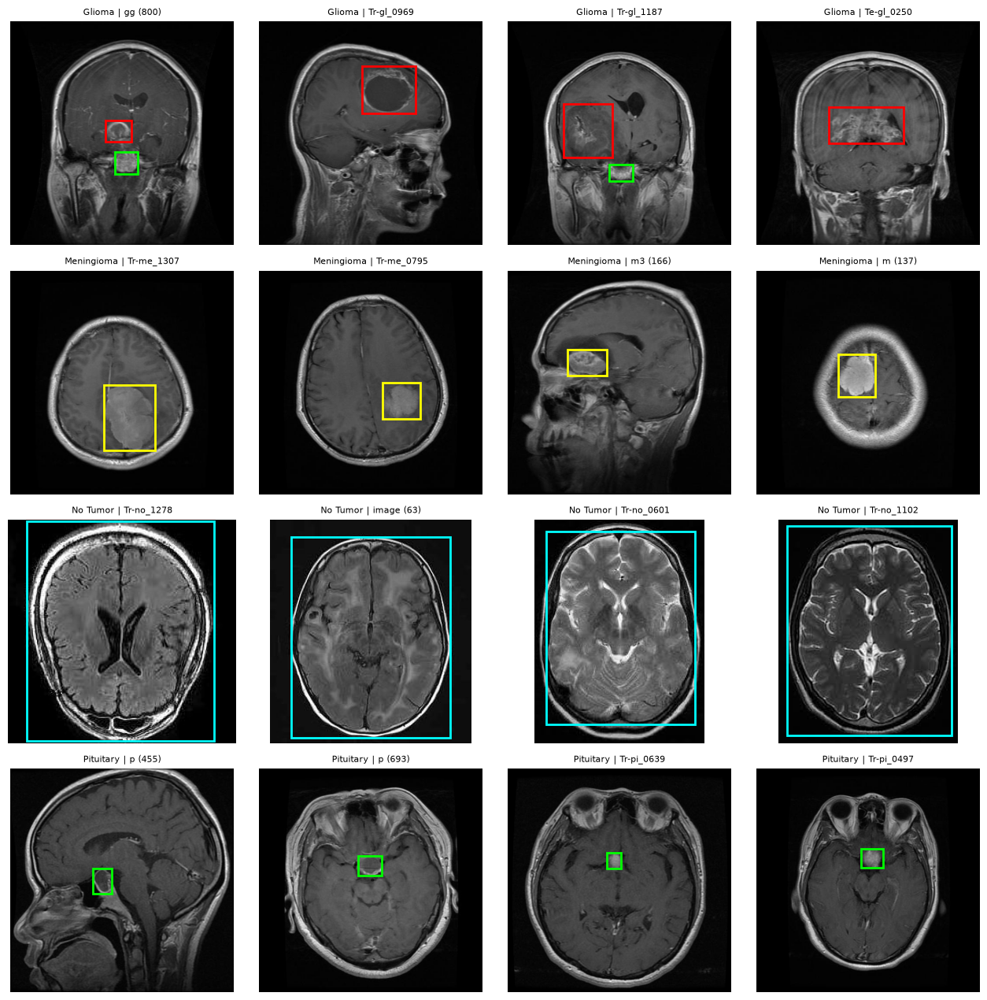

In [18]:
# CE QUE FAIT CETTE CELLULE (étape 1.6a, contrôle visuel général)
# Relie le tableau de cohérence (cons) aux chemins d'images, tire 4 images au hasard par
# classe (graine fixe pour retrouver les mêmes) et les affiche avec leurs rectangles.
# On vérifie que les rectangles entourent bien une zone, sans décalage.
from src.data import plot_gallery

vis = cons.merge(inv[["label_path", "image_path"]], on="label_path")
sample = vis.groupby("class").sample(4, random_state=42).sort_values("class")
plot_gallery(sample, ncols=4, out_path=ROOT / cfg["paths"]["figures"] / "boxes_random.png")

## 1.6b Les 15 images `none_match`
Pour ces 15 images, le dossier et **toutes** les boîtes se contredisent. On les regarde une par une, avec la liste des types trouvés dans leurs boîtes, pour décider de leur sort (garder avec le type du dossier, avec celui de l'annotation, ou mettre de côté).

,image_path,class,split_origin,box_classes
23,data/raw/Train/Glioma/images/Te-gl_0043.jpg,Glioma,Train,[1]
451,data/raw/Train/Glioma/images/Tr-gl_1167.jpg,Glioma,Train,[1]
662,data/raw/Train/Glioma/images/gg (278).jpg,Glioma,Train,[3]
1161,data/raw/Train/Meningioma/images/Tr-me_0023.jpg,Meningioma,Train,[0]
1217,data/raw/Train/Meningioma/images/Tr-me_0119.jpg,Meningioma,Train,[3]
1323,data/raw/Train/Meningioma/images/Tr-me_0385.jpg,Meningioma,Train,[0]
2001,data/raw/Train/Meningioma/images/m (49).jpg,Meningioma,Train,[3]
2003,data/raw/Train/Meningioma/images/m (50).jpg,Meningioma,Train,[3]
2004,data/raw/Train/Meningioma/images/m (51).jpg,Meningioma,Train,[3]
2005,data/raw/Train/Meningioma/images/m (52).jpg,Meningioma,Train,[3]


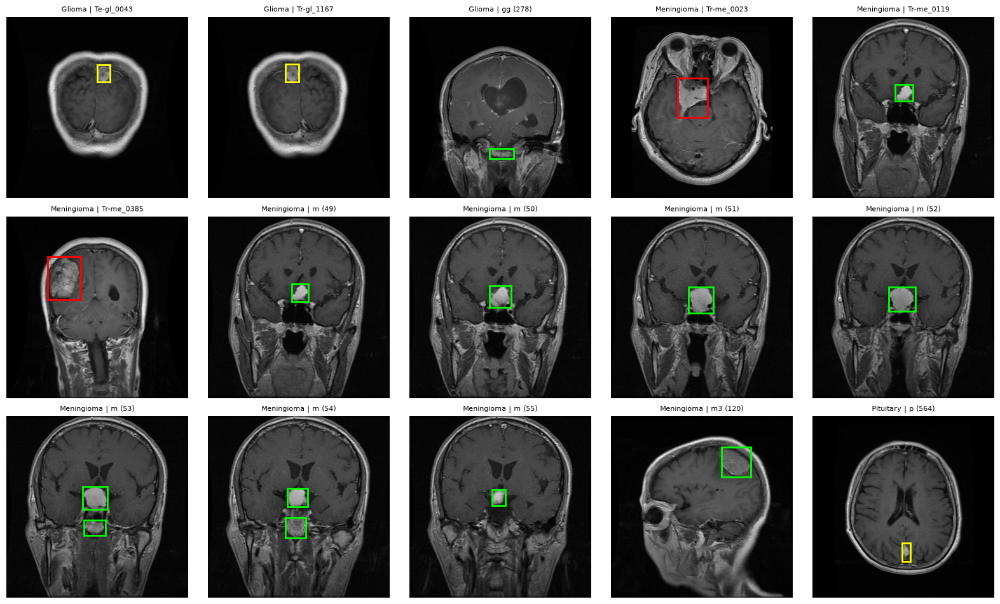

In [19]:
# CE QUE FAIT CETTE CELLULE (étape 1.6b, les 15 cas de conflit)
# 1) Liste les 15 images où le dossier contredit toutes les boîtes, avec les classes
#    trouvées dans leurs boîtes (0=Glioma, 1=Meningioma, 2=No Tumor, 3=Pituitary).
# 2) Les affiche avec leurs rectangles pour comparer visuellement.
ids = boxes.groupby("label_path")["class_id"].agg(lambda s: sorted(set(s)))
nm = vis[vis.consistency == "none_match"].assign(box_classes=lambda d: d.label_path.map(ids))
display(nm[["image_path", "class", "split_origin", "box_classes"]])
plot_gallery(nm, ncols=5, out_path=ROOT / cfg["paths"]["figures"] / "boxes_none_match.png")

## 1.6c Quelques images `mixed`
8 images de la catégorie `mixed` : une boîte du bon type **et** au moins une boîte d'un autre type. On regarde si cela ressemble à une deuxième lésion visible ou à une erreur.

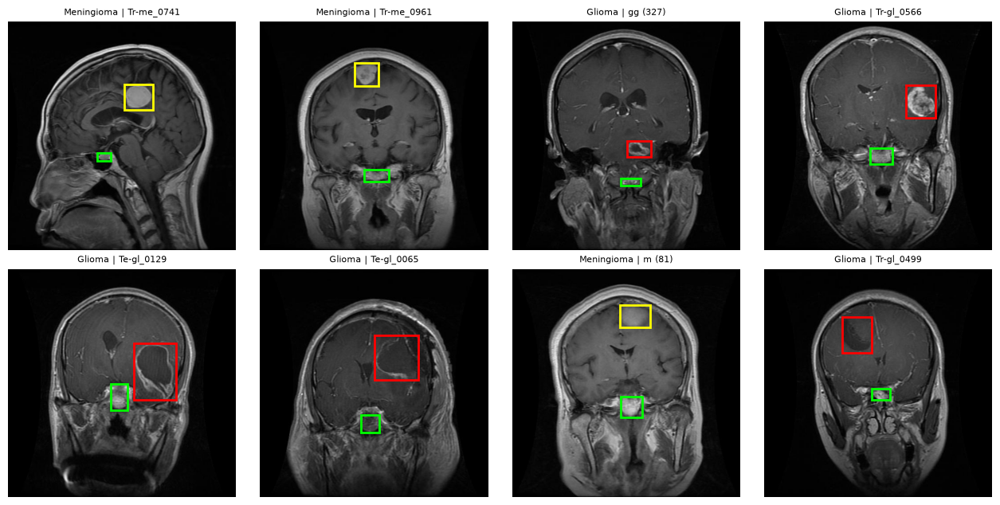

In [20]:
# CE QUE FAIT CETTE CELLULE (étape 1.6c, exemples d'images "mixed")
# Tire 8 images au hasard parmi celles qui ont à la fois une boîte du type du dossier
# et une boîte d'un autre type, puis les affiche avec leurs rectangles.
mx = vis[vis.consistency == "mixed"].sample(8, random_state=42)
plot_gallery(mx, ncols=4, out_path=ROOT / cfg["paths"]["figures"] / "boxes_mixed.png")

**Résultats 1.6 : visualisation des boîtes**

**1.6a (images au hasard)** : les rectangles sont bien placés sur les zones visibles, sans décalage. Le format YOLO (centre, largeur, hauteur normalisés) est correctement lu. Pour `No Tumor`, le rectangle entoure toute la tête : ce n'est pas une lésion, donc **`No Tumor` est exclu de la détection YOLO** (3 classes : Glioma, Meningioma, Pituitary).

**1.6c (images `mixed`)** : la boîte supplémentaire est presque toujours de type Pituitary, au centre-bas du cerveau (zone de l'hypophyse). Sur les 279 boîtes qui ne correspondent pas à leur dossier, 273 (98 %) sont de type Pituitary. **Limite à documenter :** la classe Pituitary de YOLO mélangera les tumeurs du dossier Pituitary et ces boîtes sur la zone de l'hypophyse dans les autres dossiers.

**1.6b (15 images `none_match`)** : 3 Glioma, 11 Meningioma, 1 Pituitary, tous dans Train.
- 7 sont des coupes successives (`m (49)` à `m (55)`), probablement du même patient.
- 2 semblent être la même image (`Te-gl_0043` et `Tr-gl_1167`).
- Aucun motif ne permet de dire si le dossier ou l'annotation a raison.

**Décision :** les 15 images sont mises de côté (statut `label_conflict`) pour la classification et la détection. Elles ne sont ni dans l'entraînement, ni dans la validation, ni dans le test. Rien n'est supprimé du disque. Elles serviront à une petite analyse des cas ambigus aux Jours 4 et 5.

**Point à traiter en 1.7 :** des coupes voisines du même patient, réparties entre entraînement et test, gonfleraient les scores. Les empreintes de fichier ne détectent que les copies exactes, donc on testera aussi la ressemblance entre images aux numéros voisins.

## 1.7 Doublons : décision préalable
Les 15 images en conflit (`none_match`) sont **mises de côté** pour la classification et la détection : statut `label_conflict`. Elles ne sont ni dans l'entraînement, ni dans la validation, ni dans le test. Rien n'est supprimé du disque.

In [21]:
# CE QUE FAIT CETTE CELLULE (décision sur les 15 images en conflit)
# Passe au statut "label_conflict" les 15 images dont aucune boîte ne correspond au dossier.
# Les statuts attendus : ok 5232, label_conflict 15, orphan_image 2, orphan_label 2.
from src.data import apply_conflict_status

inv = apply_conflict_status(inv, cons)
inv["status"].value_counts()

status
ok                5232
label_conflict      15
orphan_label         2
orphan_image         2
Name: count, dtype: int64

## 1.7a Empreintes des images
Pour détecter les doublons, on calcule trois choses pour chaque image :
- **sha256** : un code calculé sur le contenu du fichier. Deux fichiers identiques octet pour octet ont le même code (copie exacte).
- **empreinte visuelle** : l'image est réduite à 17×16 pixels gris, et on note si chaque pixel est plus clair que son voisin de droite. Cela donne 256 « oui/non ». Deux images presque identiques donnent des suites presque identiques. La **distance** entre deux images est le nombre de réponses différentes (0 = identiques, 256 = tout est différent).
- **miniature 32×32** : permet de calculer l'écart moyen de pixels (`mad`, de 0 à 255) pour confirmer visuellement ce que dit la distance.

**Règle :** on ne supprime rien. Tout est calculé sur les 5 249 images, y compris les 15 en conflit.
**Limite :** une image retournée en miroir ne serait pas repérée.

In [22]:
# CE QUE FAIT CETTE CELLULE (étape 1.7a, calcul des empreintes)
# Ouvre chaque image une fois et calcule : sha256, empreinte visuelle (256 oui/non) et
# miniature 32x32. Le résultat est enregistré dans data/processed/fingerprints.npz
# pour ne pas tout recalculer ; la première exécution prend un peu de temps.
from src.duplicates import compute_fingerprints

imgs = inv[inv.has_image].reset_index(drop=True)
fp, bits, thumbs = compute_fingerprints(
    imgs.image_path, cache_path=ROOT / cfg["paths"]["processed"] / "fingerprints.npz")
meta = imgs.assign(sha256=fp["sha256"].values)

print("Images :", len(meta), "| empreintes :", bits.shape, "| miniatures :", thumbs.shape)

Images : 5249 | empreintes : (5249, 256) | miniatures : (5249, 32, 32)


## 1.7b Copies exactes
Fichiers qui ont **le même sha256** : ce sont des copies exactes. On regarde combien il y en a et **où elles se trouvent** :
- dans des **classes différentes** : conflit d'étiquette (même image, deux dossiers) ;
- entre **Train et Val** : la validation serait contaminée (scores trop beaux).

In [23]:
# CE QUE FAIT CETTE CELLULE (étape 1.7b, copies exactes)
# Repère les fichiers qui ont le même sha256, résume les groupes (taille, nombre de classes,
# nombre de splits) et affiche les groupes qui se trouvent dans plusieurs classes
# ou à la fois dans Train et Val. Aucune donnée n'est modifiée.
from src.duplicates import summarize_groups

dup = meta[meta.duplicated("sha256", keep=False)]
g = summarize_groups(dup, "sha256")
print(f"Fichiers concernés : {len(dup)}  |  groupes de copies exactes : {len(g)}  |  taille max d'un groupe : {g.n.max() if len(g) else 0}")
print(f"Groupes dans plusieurs classes (conflit d'étiquette) : {(g.n_classes > 1).sum()}")
print(f"Groupes présents dans Train ET Val (validation contaminée) : {(g.n_splits > 1).sum()}")

labels = dup.assign(lbl=dup.split_origin + "/" + dup["class"] + "/" + dup.stem).groupby("sha256")["lbl"].agg(" | ".join)
display(g.join(labels).sort_values(["n_classes", "n_splits", "n"], ascending=False).head(15))

Fichiers concernés : 2564  |  groupes de copies exactes : 1228  |  taille max d'un groupe : 7
Groupes dans plusieurs classes (conflit d'étiquette) : 0
Groupes présents dans Train ET Val (validation contaminée) : 213


,n,n_classes,n_splits,lbl
sha256,,,,
24f09f91af40e42f2798bbc29df353ce17e6a0c0b533fb923b2fa8f75df6b496,6,1,2,Train/Meningioma/Tr-me_0176 | Train/Meningioma...
2ad6ffff97ce8cbfd5d4785955ea16a6ccf7090eb67a8015e47cd8902571b827,6,1,2,Train/No Tumor/Tr-no_0150 | Train/No Tumor/Tr-...
2ed15a662d8dcdf6077f3bf8bb4d21722e2a3b90ff2cf194db18b75933a4d322,5,1,2,Train/No Tumor/Tr-no_0366 | Train/No Tumor/ima...
76a70a3f68103e335f080a323d763fbda5febc37e4714c2f9b54499795f13fa3,5,1,2,Train/No Tumor/Tr-no_0362 | Train/No Tumor/Tr-...
7d0738e4f6493b449e20a147b80f674c589dc478dd6b5ccd4fb6ea1c329f0cfe,5,1,2,Train/Pituitary/Tr-pi_0529 | Train/Pituitary/p...
840e12a9d0fc509d61fab11db74d1716234312bd96939b632e19b8f102ace3cf,5,1,2,Train/No Tumor/Tr-no_0185 | Train/No Tumor/Tr-...
e3ea07d69e4b3242a2bc56046a2c9547c6e15d8169d3bdad7d4f8f9baf2a2442,5,1,2,Train/No Tumor/Tr-no_0264 | Train/No Tumor/Tr-...
e9a63334af63a2ec8cab2149ec091466c60df5fe115cf36cc30c9304dacbb376,5,1,2,Train/No Tumor/Tr-no_0140 | Train/No Tumor/Tr-...
136e27954eca1b7b887f3700f412b2c531153938a0d721d1557a94c3362497c2,4,1,2,Train/No Tumor/image(24) | Train/No Tumor/imag...


## 1.7c Quasi-copies : choisir un seuil strict
**Règle choisie :** on ne regroupe que les images identiques ou très, très proches (copie recompressée ou redimensionnée). Des images qui se ressemblent simplement (cerveaux de face, de profil...) ne comptent pas.

Pour choisir le seuil, on mesure pour chaque image **la distance à son voisin le plus proche**, puis on regarde des paires à différentes distances avec leur écart de pixels (`mad`). Distances regardées : 0 | 1-4 | 5-10 | 11-20 | 21-40 (sur 256).

Images dont le plus proche voisin est à ≤  0 bits :  2602 (49.6 %)
Images dont le plus proche voisin est à ≤  4 bits :  2771 (52.8 %)
Images dont le plus proche voisin est à ≤  8 bits :  2850 (54.3 %)
Images dont le plus proche voisin est à ≤ 16 bits :  2942 (56.0 %)
Images dont le plus proche voisin est à ≤ 32 bits :  3945 (75.2 %)


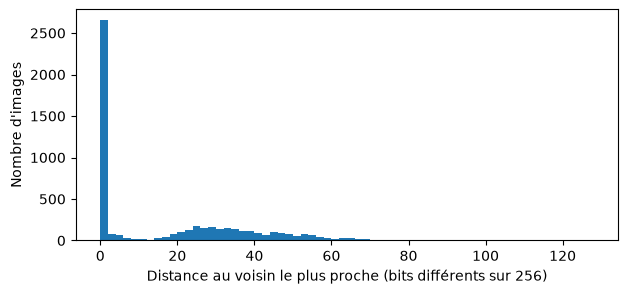

,paires,mad_median,classes_differentes,entre_Train_et_Val
bin,,,,
0,1609,0.00,0,285
1-4,394,0.24,0,38
5-10,546,1.02,0,57
11-20,701,5.08,0,105
21-40,13518,8.27,1993,2609


In [24]:
# CE QUE FAIT CETTE CELLULE (étape 1.7c, mesure des distances)
# 1) Pour chaque image, calcule la distance à son voisin le plus proche, et dit combien d'images
#    ont un voisin à moins de 0, 4, 8, 16, 32 bits.
# 2) Liste toutes les paires à moins de 40 bits, avec l'écart moyen de pixels (mad) et leur position
#    (même classe ou non, même split ou non), puis les range par tranche de distance.
import matplotlib.pyplot as plt
from src.duplicates import nearest_distance, hamming_pairs, describe_pairs

nn = nearest_distance(bits)
for t in (0, 4, 8, 16, 32):
    print(f"Images dont le plus proche voisin est à ≤ {t:>2} bits : {(nn <= t).sum():>5} ({(nn <= t).mean() * 100:.1f} %)")

plt.figure(figsize=(7, 3))
plt.hist(nn, bins=range(0, 130, 2))
plt.xlabel("Distance au voisin le plus proche (bits différents sur 256)")
plt.ylabel("Nombre d'images")
plt.show()

pairs = hamming_pairs(bits, max_dist=40)
pp = describe_pairs(pairs, meta, thumbs)
pp["bin"] = pd.cut(pp.hamming, [-1, 0, 4, 10, 20, 40], labels=["0", "1-4", "5-10", "11-20", "21-40"])
display(pp.groupby("bin", observed=True).agg(
    paires=("hamming", "size"),
    mad_median=("mad", "median"),
    classes_differentes=("same_class", lambda s: int((~s).sum())),
    entre_Train_et_Val=("same_split", lambda s: int((~s).sum())),
))

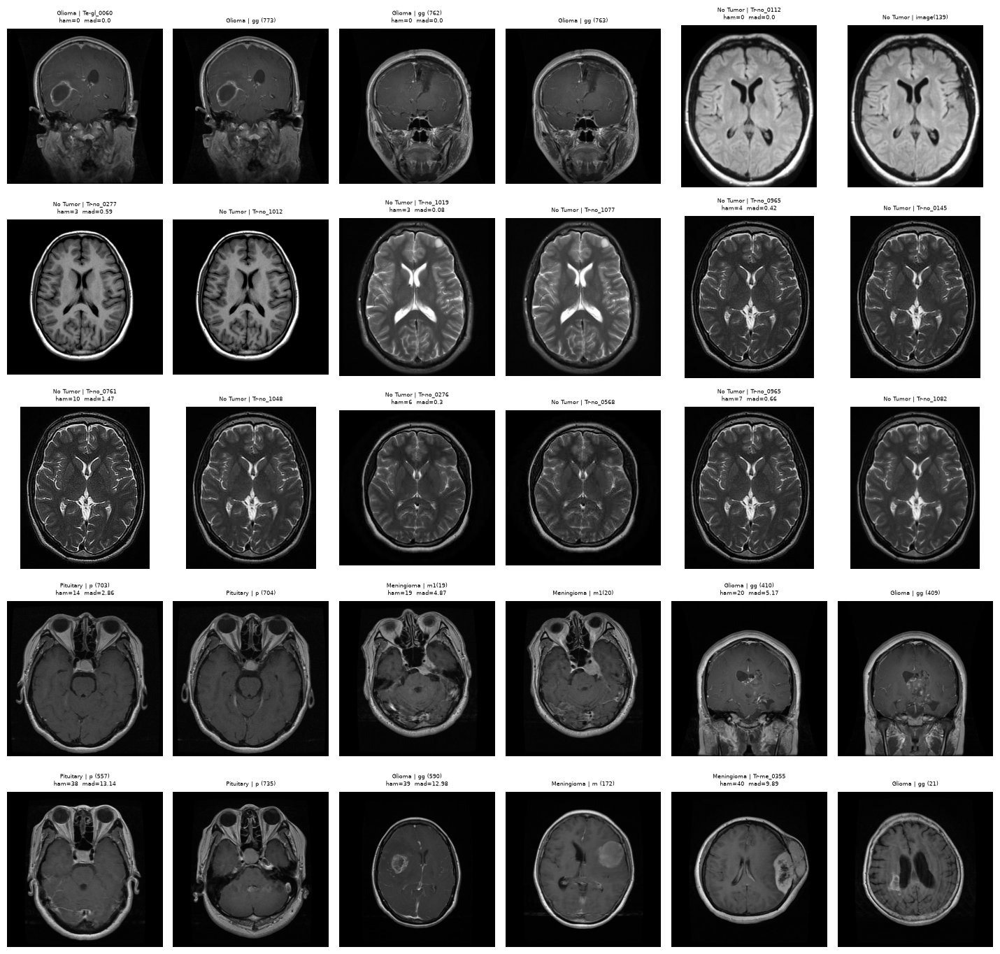

In [25]:
# CE QUE FAIT CETTE CELLULE (étape 1.7c, exemples visuels)
# Tire jusqu'à 3 paires au hasard dans chaque tranche de distance et les affiche côte à côte,
# avec la distance (ham) et l'écart de pixels (mad), pour juger à partir de quelle distance
# deux images ne sont plus "la même image".
from src.duplicates import plot_pairs

parts = [pp[pp.bin == b].sample(min(3, int((pp.bin == b).sum())), random_state=42)
         for b in pp.bin.cat.categories]
sel = pd.concat(parts)
plot_pairs(sel, per_row=3, out_path=ROOT / cfg["paths"]["figures"] / "duplicate_pairs.png")

**Résultats 1.7a à 1.7c : doublons**

**Copies exactes (1.7b)**
- 2 564 fichiers (48,8 %) appartiennent à un groupe de copies exactes : 1 228 groupes, taille maximale 7 → environ 3 900 images vraiment distinctes.
- **Aucun groupe ne mélange plusieurs classes** : pas de conflit d'étiquette entre copies.
- **213 groupes sont à la fois dans Train et Val** : au moins 213 images de Val (sur 512, ≈ 42 %) ont une copie exacte dans Train. La validation d'origine est très contaminée.
- Une même image existe sous des noms de familles différentes (`Te-gl_0060` = `gg (773)`) : le dataset a été assemblé à partir de sources qui se recoupent.

**Quasi-copies (1.7c)**
- Histogramme : un grand pic à distance 0 (2 602 images ont un jumeau exact), un creux entre 10 et 15, puis une bosse vers 20-60 (images sans jumeau).
- Aucune paire de classes différentes jusqu'à la distance 20.
- Galerie : jusqu'à la distance 10 (écart de pixels ≤ 1,5) ce sont les mêmes images (recompression, PNG converti en JPG, petite différence de netteté). Entre 14 et 20 ce sont des coupes voisines (numéros consécutifs, forme de la tumeur différente). À partir de 38, images sans rapport.

**Seuil strict retenu (provisoire) : distance ≤ 10 ET écart de pixels ≤ 2.** Les coupes voisines ne sont pas regroupées.

**Limite à documenter :** sans identifiant de patient dans le dataset, des coupes voisines du même patient peuvent se retrouver dans des splits différents ; les scores peuvent être un peu optimistes.

## 1.7c bis Vérification de la frontière
Comme on n'a vu que 3 exemples par tranche, on regarde de plus près la zone où le seuil est coupé :
- combien de paires à distance ≤ 10 ont un écart de pixels > 2 (le double critère les écarterait) ;
- 6 paires tirées au hasard entre les distances 8 et 14, pour vérifier à l'œil qu'on coupe au bon endroit.

Paires à distance <= 10 : 2549  |  dont écart de pixels > 2 : 242
Paires entre les distances 8 et 14 : 429


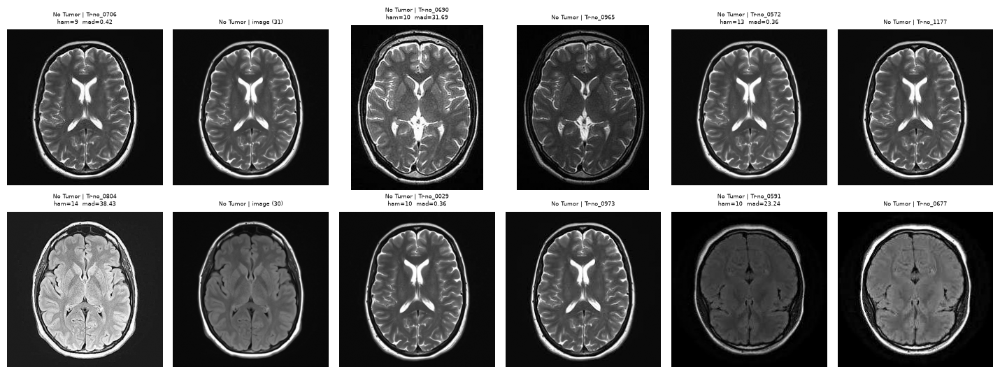

In [26]:
# CE QUE FAIT CETTE CELLULE (étape 1.7c bis, zone frontière)
# 1) Compte les paires proches (distance <= 10) dont l'écart de pixels dépasse 2 :
#    s'il y en a, le double critère les écarte.
# 2) Affiche 6 paires au hasard dont la distance est entre 8 et 14 (la frontière),
#    pour vérifier à l'oeil que le seuil de 10 coupe au bon endroit.
close = pp[pp.hamming <= 10]
print(f"Paires à distance <= 10 : {len(close)}  |  dont écart de pixels > 2 : {(close['mad'] > 2).sum()}")

border = pp[pp.hamming.between(8, 14)]
print(f"Paires entre les distances 8 et 14 : {len(border)}")
plot_pairs(border.sample(min(6, len(border)), random_state=1), per_row=3,
           out_path=ROOT / cfg["paths"]["figures"] / "duplicate_border.png")

## 1.7d Groupes de doublons
On relie entre elles toutes les images **jumelles** (distance ≤ 10 et écart de pixels ≤ 2) dans un même **groupe** (`group_id`). Une image sans jumeau forme un groupe à elle seule.

**Pourquoi :** un groupe ne sera jamais coupé entre plusieurs splits (entraînement, validation, test). Sinon une image pourrait être en test et son jumeau en entraînement, et le score serait trop beau.

**Rien n'est supprimé :** tous les fichiers restent, y compris pour YOLO. Seul le split change.

On regarde aussi combien d'images de `Val` ont un jumeau dans `Train`, pour décider du découpage.

In [27]:
# CE QUE FAIT CETTE CELLULE (étape 1.7d, groupes de doublons)
# 1) Réaffiche les statuts (attendu : ok 5232, label_conflict 15, orphan_image 2, orphan_label 2).
# 2) Garde les paires "jumelles" selon la règle stricte (distance <= HAM_MAX et écart <= MAD_MAX)
#    et relie les images jumelles dans un même groupe (group_id).
# 3) Résume : taille des groupes, conflits de classe, groupes qui touchent Train et Val,
#    et nombre d'images de Val qui ont un jumeau dans Train, par classe.
from src.duplicates import build_groups

HAM_MAX, MAD_MAX = 10, 2.0
twins = pp[(pp.hamming <= HAM_MAX) & (pp["mad"] <= MAD_MAX)]
meta["group_id"] = build_groups(len(meta), twins)

print(inv["status"].value_counts(), "\n")

g = meta.groupby("group_id").agg(
    n=("image_path", "size"),
    n_classes=("class", "nunique"),
    n_splits=("split_origin", "nunique"),
)
print(f"Images : {len(meta)}  |  groupes (images distinctes) : {len(g)}")
print("Taille des groupes (nombre d'images par groupe) :")
display(g["n"].value_counts().sort_index())
print("Groupes qui mélangent plusieurs classes :", int((g.n_classes > 1).sum()))

span = g[g.n_splits > 1].index
val = meta[meta.split_origin == "Val"]
val_twin = val[val.group_id.isin(span)]
print(f"Groupes présents dans Train ET Val : {len(span)}")
print(f"Images de Val qui ont un jumeau dans Train : {len(val_twin)} sur {len(val)} ({len(val_twin) / len(val) * 100:.1f} %)")

display(pd.DataFrame({
    "Val": val.groupby("class").size(),
    "avec jumeau dans Train": val_twin.groupby("class").size(),
}).fillna(0).astype(int))

display(pd.DataFrame({
    "images": meta.groupby("class").size(),
    "groupes (images distinctes)": meta.groupby("class")["group_id"].nunique(),
}))

status
ok                5232
label_conflict      15
orphan_label         2
orphan_image         2
Name: count, dtype: int64 

Images : 5249  |  groupes (images distinctes) : 3707
Taille des groupes (nombre d'images par groupe) :


n
1     2419
2     1180
3       56
4       25
5        9
6        6
7        5
8        2
9        2
15       1
17       1
20       1
Name: count, dtype: int64

Groupes qui mélangent plusieurs classes : 0
Groupes présents dans Train ET Val : 226
Images de Val qui ont un jumeau dans Train : 235 sur 512 (45.9 %)


,Val,avec jumeau dans Train
class,,
Glioma,136,9
Meningioma,140,78
No Tumor,100,71
Pituitary,136,77


,images,groupes (images distinctes)
class,,
Glioma,1289,1190
Meningioma,1589,1088
No Tumor,811,403
Pituitary,1560,1026


**Résultats 1.7c bis et 1.7d (provisoires)**

**Frontière**
- 2 549 paires à distance ≤ 10, dont 242 avec un écart de pixels > 2 ; 429 paires entre les distances 8 et 14.
- Les paires à faible écart (0,36 à 0,42) sont la même image, **même à distance 13** : le seuil de distance 10 est trop strict.
- Les paires à grand écart (23 à 38) ressemblent à la même coupe avec une autre luminosité ou un autre cadrage : ce sont peut-être des **copies modifiées**, pas des images différentes. L'écart de pixels est sensible à la luminosité. À vérifier en 1.7e.

**Groupes (seuils provisoires : distance ≤ 10, écart ≤ 2)**
- 5 249 images → 3 707 groupes ; 2 419 images sont seules. Aucun groupe ne mélange plusieurs classes.
- Groupes de 15, 17 et 20 images : **effet de chaîne possible** (une copie exacte va au plus à 7 fichiers).
- 226 groupes sont dans Train **et** Val : 235 images de Val sur 512 (45,9 %) ont un jumeau dans Train.

| Classe | Images | Groupes (images distinctes) | Val avec jumeau dans Train |
|---|---|---|---|
| Glioma | 1 289 | 1 190 | 9 / 136 |
| Meningioma | 1 589 | 1 088 | 78 / 140 |
| No Tumor | 811 | 403 | 71 / 100 |
| Pituitary | 1 560 | 1 026 | 77 / 136 |

**No Tumor n'a que 403 images distinctes** : le déséquilibre réel entre classes est de 2,95 (1 190 / 403) et non 2,04.

Si on gardait `Val` en déplaçant ses groupes contaminés vers Train, il resterait 277 images dont 29 No Tumor : trop peu. **Option retenue pour le découpage : tout redécouper par groupes, stratifié par classe** (à confirmer après 1.7e).

## 1.7e Vérifier les seuils et les gros groupes avant de les figer
Trois vérifications :
1. **Copies modifiées** : parmi les paires proches (distance ≤ 20), celles qui ont un grand écart de pixels sont-elles la même coupe avec une autre luminosité ? On ajoute `corr`, une ressemblance qui **ignore la luminosité** (1 = même image à la luminosité près).
2. **Jumeaux ratés** : paires à distance 11-20 avec un faible écart de pixels (comme `Tr-no_0572` / `Tr-no_1177` à distance 13).
3. **Effet de chaîne** : pour les groupes de 8 images ou plus, quel est l'écart de pixels maximum entre deux membres ?

**Règle inchangée :** on ne regroupe que ce qui est identique ou très, très proche. Rien n'est supprimé.

In [28]:
# CE QUE FAIT CETTE CELLULE (étape 1.7e, vérification 1 : copies modifiées)
# Ajoute à chaque paire la colonne "corr" (ressemblance qui ignore la luminosité), puis croise,
# pour les paires à distance <= 20, la valeur de "corr" avec le fait que l'écart de pixels soit
# faible (<= 2) ou non. Si beaucoup de paires à grand écart ont un corr très élevé (>= 0.98),
# ce sont des copies de luminosité différente. Aucune donnée n'est modifiée.
from src.duplicates import add_correlation

pp = add_correlation(pp, thumbs)
cand = pp[pp.hamming <= 20].copy()
cand["corr_tranche"] = pd.cut(cand["corr"], [-1, 0.8, 0.9, 0.95, 0.98, 0.99, 1.01], include_lowest=True)
cand["écart faible (mad<=2)"] = cand["mad"] <= 2
print(f"Paires à distance <= 20 : {len(cand)}")
display(pd.crosstab(cand["corr_tranche"], cand["écart faible (mad<=2)"]))

Paires à distance <= 20 : 3250


écart faible (mad<=2),False,True
corr_tranche,,
"(-1.001, 0.8]",1,0
"(0.9, 0.95]",17,0
"(0.95, 0.98]",347,0
"(0.98, 0.99]",305,8
"(0.99, 1.01]",189,2383


Paires à distance <= 20 avec écart de pixels > 2 : 859


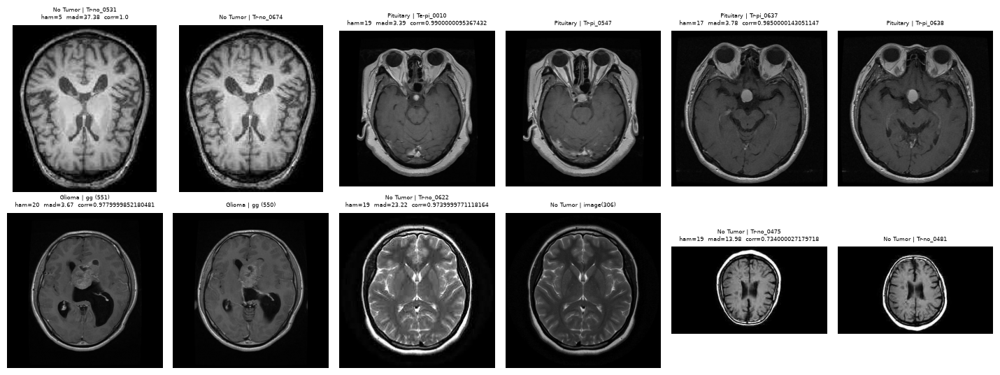

In [29]:
# CE QUE FAIT CETTE CELLULE (étape 1.7e, vérification 1 : galerie)
# Prend les paires proches (distance <= 20) dont l'écart de pixels est grand (> 2), les classe par
# corr décroissant et en affiche 6 réparties du plus haut au plus bas corr. On voit à partir
# de quelle valeur de corr les deux images ne sont plus la même coupe.
import numpy as np

a = pp[(pp.hamming <= 20) & (pp["mad"] > 2)].sort_values("corr", ascending=False)
print(f"Paires à distance <= 20 avec écart de pixels > 2 : {len(a)}")
pick = a.iloc[np.linspace(0, len(a) - 1, 6).astype(int)]
plot_pairs(pick, per_row=3, out_path=ROOT / cfg["paths"]["figures"] / "duplicate_modified.png")

Paires à distance 11-20 avec écart de pixels <= 2 : 84


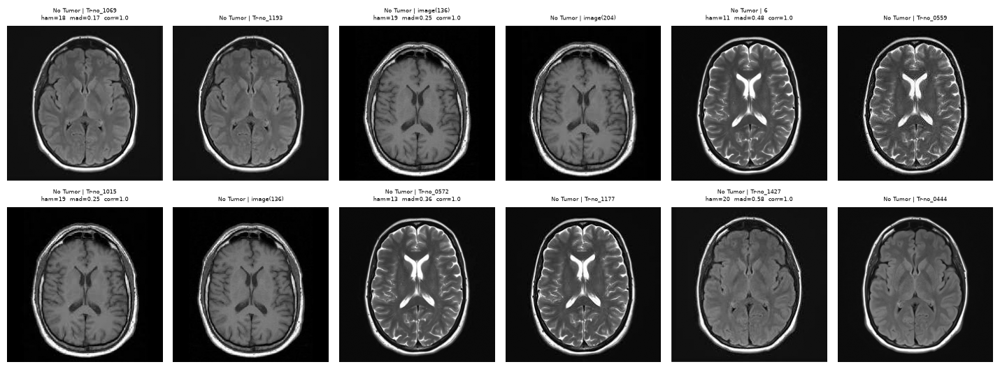

In [30]:
# CE QUE FAIT CETTE CELLULE (étape 1.7e, vérification 2 : jumeaux ratés)
# Prend les paires dont la distance est entre 11 et 20 mais dont l'écart de pixels est faible (<= 2),
# donc des images presque identiques qu'un seuil de distance à 10 ne regrouperait pas.
# Affiche 6 exemples pour confirmer à l'oeil que ce sont des jumeaux.
b = pp[pp.hamming.between(11, 20) & (pp["mad"] <= 2)]
print(f"Paires à distance 11-20 avec écart de pixels <= 2 : {len(b)}")
if len(b):
    plot_pairs(b.sample(min(6, len(b)), random_state=3), per_row=3,
               out_path=ROOT / cfg["paths"]["figures"] / "duplicate_missed.png")

,group_id,n,classe,écart max dans le groupe
0,2115,20,No Tumor,2.03
1,2102,17,No Tumor,1.04
2,2098,15,No Tumor,1.06
3,2103,9,No Tumor,0.30
4,2124,9,No Tumor,0.41
5,2116,8,No Tumor,0.00
6,2226,8,No Tumor,0.38


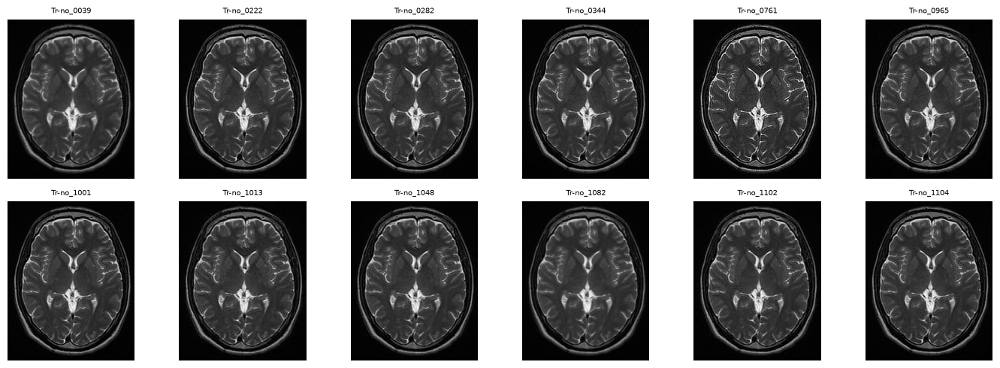

In [31]:
# CE QUE FAIT CETTE CELLULE (étape 1.7e, vérification 3 : effet de chaîne)
# Un groupe est formé en reliant des paires : A~B et B~C mettent A, B et C ensemble, même si A et C
# ne se ressemblent pas. Pour les groupes de 8 images ou plus :
# 1) calcule l'écart de pixels maximum entre deux membres (grand = chaîne suspecte) ;
# 2) affiche les images du plus gros groupe (12 au maximum).
from pathlib import Path
from PIL import Image

sizes = meta.groupby("group_id").size()
big = sizes[sizes >= 8].sort_values(ascending=False)
rows = []
for gid, n in big.items():
    idx = np.flatnonzero(meta.group_id.values == gid)
    t = thumbs[idx].reshape(len(idx), -1).astype(np.int16)
    d = np.abs(t[:, None, :] - t[None, :, :]).mean(axis=2)
    rows.append({"group_id": gid, "n": n, "classe": meta["class"].iloc[idx[0]],
                 "écart max dans le groupe": round(float(d.max()), 2)})
display(pd.DataFrame(rows))

members = meta[meta.group_id == big.index[0]].head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, members.iterrows()):
    ax.imshow(Image.open(ROOT / r.image_path).convert("L"), cmap="gray")
    ax.set_title(Path(r.image_path).stem, fontsize=7)
plt.tight_layout()
plt.show()

**Résultats 1.7e : vérification des seuils**

**1. Copies de luminosité différente.** Parmi les 3 250 paires à distance ≤ 20 : 2 391 ont un faible écart de pixels, 859 un grand écart.
- Sur ces 859 : 189 ont un corr > 0,99 ; 305 entre 0,98 et 0,99 ; 347 entre 0,95 et 0,98 ; 17 entre 0,90 et 0,95 ; 1 en dessous de 0,8.
- Galerie : corr = 1,0 → même image (version plus claire ou plus sombre) ; corr ≈ 0,99 → presque la même image (limite) ; corr 0,985 et 0,978 → coupes voisines (numéros consécutifs) ; corr 0,974 → incertain ; corr 0,73 → images différentes.
- **La frontière se situe entre 0,985 et 0,99.** L'écart de pixels seul rate les copies de luminosité différente.

**2. Jumeaux ratés.** 84 paires à distance 11-20 avec un faible écart de pixels : les 6 exemples sont la même image (corr = 1,0). Le seuil de distance 10 était trop strict → **20**.

**3. Effet de chaîne.** 7 groupes de 8 images ou plus, tous `No Tumor`. L'écart maximal entre deux membres est ≤ 2,03 : pas de chaîne. La même coupe existe jusqu'à 20 fois dans `No Tumor`, ce qui explique ses 403 images distinctes.

**Limite :** une copie très modifiée (ex. `Tr-no_0622` / `image(306)`, corr 0,974) peut ne pas être regroupée. Le risque résiduel sera mesuré après le découpage.

## 1.7f Règle finale et groupes
Deux images sont **jumelles** si :
- leur distance est **≤ 20**, **et**
- leur corr est **≥ 0,99** (même image, plus ou moins claire) **ou** leur écart de pixels est **≤ 2** (pixels quasi égaux).

Les coupes voisines (corr plus bas) ne sont pas regroupées. Les images jumelles reçoivent le même `group_id` : un groupe ne sera jamais coupé entre plusieurs splits. Rien n'est supprimé du disque. Les seuils sont lus dans `configs/config.yaml`.

In [32]:
from src.utils import load_config

cfg = load_config()
print("Sections de la configuration :", list(cfg.keys()))
print("Seuils des doublons :", cfg["duplicates"])

Sections de la configuration : ['seed', 'paths', 'data', 'classifier', 'yolo', 'duplicates', 'preprocessing', 'augmentation', 'finetune', 'experiments', 'airflow']
Seuils des doublons : {'ham_max': 20, 'corr_min': 0.99, 'mad_max': 2.0}


In [33]:
# CE QUE FAIT CETTE CELLULE (étape 1.7f, groupes avec la règle finale)
# 1) Garde les paires jumelles selon la règle finale (seuils lus dans config.yaml)
#    et relie les images jumelles dans un même groupe (group_id).
# 2) Affiche : la taille des groupes, les groupes qui mélangent plusieurs classes,
#    les groupes présents à la fois dans Train et Val, le nombre d'images de Val qui ont un
#    jumeau dans Train, puis le nombre d'images distinctes (groupes) par classe.
from src.duplicates import select_twins, build_groups

d = cfg["duplicates"]
twins = select_twins(pp, d["ham_max"], d["corr_min"], d["mad_max"])
meta["group_id"] = build_groups(len(meta), twins)
print(f"Paires jumelles retenues : {len(twins)}   (attendu : environ 2 580)")

g = meta.groupby("group_id").agg(
    n=("image_path", "size"),
    n_classes=("class", "nunique"),
    n_splits=("split_origin", "nunique"),
)
print(f"Images : {len(meta)}  |  groupes (images distinctes) : {len(g)}  |  plus gros groupe : {g.n.max()}")
print("Taille des groupes (nombre d'images par groupe) :")
display(g["n"].value_counts().sort_index())
print("Groupes qui mélangent plusieurs classes :", int((g.n_classes > 1).sum()))

span = g[g.n_splits > 1].index
val = meta[meta.split_origin == "Val"]
val_twin = val[val.group_id.isin(span)]
print(f"Groupes présents dans Train ET Val : {len(span)}")
print(f"Images de Val qui ont un jumeau dans Train : {len(val_twin)} sur {len(val)} ({len(val_twin) / len(val) * 100:.1f} %)")

display(pd.DataFrame({
    "images": meta.groupby("class").size(),
    "groupes (images distinctes)": meta.groupby("class")["group_id"].nunique(),
    "Val": val.groupby("class").size(),
    "Val avec jumeau dans Train": val_twin.groupby("class").size(),
}).fillna(0).astype(int))

Paires jumelles retenues : 2580   (attendu : environ 2 580)
Images : 5249  |  groupes (images distinctes) : 3642  |  plus gros groupe : 25
Taille des groupes (nombre d'images par groupe) :


n
1     2350
2     1166
3       60
4       28
5       16
6       10
7        4
8        2
9        1
12       1
13       1
15       1
17       1
25       1
Name: count, dtype: int64

Groupes qui mélangent plusieurs classes : 0
Groupes présents dans Train ET Val : 233
Images de Val qui ont un jumeau dans Train : 243 sur 512 (47.5 %)


,images,groupes (images distinctes),Val,Val avec jumeau dans Train
class,,,,
Glioma,1289,1176,136,16
Meningioma,1589,1084,140,78
No Tumor,811,358,100,72
Pituitary,1560,1024,136,77


In [34]:
# CE QUE FAIT CETTE CELLULE (étape 1.7f, contrôle de l'effet de chaîne)
# Pour chaque groupe de 8 images ou plus, calcule la ressemblance (corr) la plus faible entre
# deux membres. Un corr minimum élevé (>= 0.98) = groupe cohérent ; en dessous de 0.97,
# des images qui ne se ressemblent pas ont été reliées par des intermédiaires (chaîne).
from src.duplicates import group_diagnostics

diag = group_diagnostics(meta, thumbs, min_size=8)
display(diag)

,group_id,n,classe,corr minimum
0,2104,25,No Tumor,0.984
1,2091,17,No Tumor,0.999
2,2087,15,No Tumor,0.999
3,2092,13,No Tumor,0.997
4,2113,12,No Tumor,0.996
5,2121,9,No Tumor,1.000
6,2105,8,No Tumor,1.000
7,2210,8,No Tumor,1.000


**Résultats 1.7f : groupes avec la règle finale**

- 2 580 paires jumelles retenues (distance ≤ 20 et corr ≥ 0,99 ou écart de pixels ≤ 2).
- 5 249 images → **3 642 groupes** (images distinctes) : 2 350 images sont seules, 2 899 ont au moins un jumeau. Plus gros groupe : 25 images.
- **Aucun groupe ne mélange plusieurs classes.**
- 233 groupes sont dans Train **et** Val : **243 images de Val sur 512 (47,5 %)** ont un jumeau dans Train.

| Classe | Images | Images distinctes | Val avec jumeau dans Train |
|---|---|---|---|
| Glioma | 1 289 | 1 176 | 16 / 136 |
| Meningioma | 1 589 | 1 084 | 78 / 140 |
| No Tumor | 811 | 358 | 72 / 100 |
| Pituitary | 1 560 | 1 024 | 77 / 136 |

**Déséquilibre réel :** sur les images distinctes, No Tumor ne pèse que 9,8 % (Glioma 32,3 %, Meningioma 29,8 %, Pituitary 28,1 %). Rapport max/min = 3,28 (et non 2,04 en comptant les copies). Méthode de compensation : décision au Jour 3.

## 1.8 Découpage par groupes et manifeste

**Décisions prises**
- **Découpage complet par groupes** (les groupes de jumeaux ne sont jamais séparés) : 70 % train / 15 % validation / 15 % test, classe par classe, calculés sur les **images distinctes**. Le split d'origine (Train/Val) est gardé pour mémoire dans `split_origin`.
- **Validation et test : un seul représentant par groupe**, pour que chaque image distincte compte une fois. Toutes les copies restent dans le manifeste.
- **Choix du représentant** : (1) image utilisable en classification, (2) utilisable en détection, (3) le plus de boîtes, (4) ordre alphabétique du chemin.
- **Entraînement** : toutes les copies restent disponibles ; la décision (toutes, un représentant, au plus 3 par groupe) sera prise avec des résultats aux Jours 2 et 5.
- Rien n'est supprimé du disque.

## 1.8a Les jumeaux ont-ils les mêmes boîtes ?
Pour chaque groupe de jumeaux annotés, on compare les boîtes de chaque image à celles de la première. Verdict par groupe : identiques, position différente (recouvrement < 50 %), classes différentes, ou nombre de boîtes différent.

**Pourquoi :** si les jumeaux ont des boîtes différentes, le choix du représentant change ce que le test de détection mesure. On vérifie aussi les indicateurs d'utilisation (attendus : 5 234 en classification, 4 422 en détection).

In [35]:
# CE QUE FAIT CETTE CELLULE (étape 1.8a, les jumeaux ont-ils les mêmes boîtes ?)
# 1) Ajoute au tableau deux indicateurs : use_for_classification et use_for_detection.
# 2) Pour chaque groupe de jumeaux annotés, compare leurs boîtes et donne un verdict.
# Aucune donnée n'est modifiée sur le disque.
from src.split import add_use_flags, compare_twin_boxes, choose_representatives, split_groups

m = add_use_flags(meta, cons)
print("Utilisables en classification :", int(m.use_for_classification.sum()), "(attendu 5234)")
print("Utilisables en détection      :", int(m.use_for_detection.sum()), "(attendu 4422)")

cmp = compare_twin_boxes(m, boxes)
print(f"\nGroupes avec au moins 2 images annotées : {len(cmp)}")
display(cmp["verdict"].value_counts())
display(pd.crosstab(cmp["class"], cmp["verdict"]))

Utilisables en classification : 5234 (attendu 5234)
Utilisables en détection      : 4422 (attendu 4422)

Groupes avec au moins 2 images annotées : 1286


verdict
identiques                    1183
nombre de boîtes différent      89
position différente             13
classes différentes              1
Name: count, dtype: int64

verdict,classes différentes,identiques,nombre de boîtes différent,position différente
class,,,,
Glioma,1,82,20,3
Meningioma,0,433,43,1
No Tumor,0,191,0,0
Pituitary,0,477,26,9


## 1.8b Choix du représentant de chaque groupe
Une image par groupe est désignée **représentante** (`is_representative`). Ordre de préférence : (1) utilisable en classification, (2) utilisable en détection, (3) le plus de boîtes, (4) ordre alphabétique du chemin.

Cette colonne servira à noter la validation et le test avec une seule image par groupe.

In [36]:
# CE QUE FAIT CETTE CELLULE (étape 1.8b, représentants)
# Désigne un représentant par groupe selon la règle, puis vérifie : un seul par groupe, et
# aucun groupe où un jumeau est utilisable en détection alors que le représentant ne l'est pas.
m = choose_representatives(m)
reps = m[m.is_representative]

print("Représentants :", len(reps), "| groupes avec au moins une image utilisable :",
      m[m.use_for_classification].group_id.nunique())
print("Groupes avec plus d'un représentant :", int((reps.groupby("group_id").size() > 1).sum()), "(attendu 0)")

can_det = m[m.use_for_classification].groupby("group_id")["use_for_detection"].any()
rep_det = reps.set_index("group_id")["use_for_detection"].reindex(can_det.index)
print("Groupes où le représentant est écarté de la détection à tort :", int((can_det & ~rep_det).sum()), "(attendu 0)")

Représentants : 3632 | groupes avec au moins une image utilisable : 3632
Groupes avec plus d'un représentant : 0 (attendu 0)
Groupes où le représentant est écarté de la détection à tort : 0 (attendu 0)


## 1.8c Découpage par groupes
Classe par classe, les groupes sont mélangés avec une graine fixe (`seed` de la config), puis répartis en 15 % test, 15 % validation et le reste en entraînement. Un groupe va entier dans un seul split. Les images écartées (statut `label_conflict`) reçoivent le split `excluded`.

**Contrôles :** aucun groupe coupé ; proportions réelles ; les familles de noms sont-elles réparties de façon semblable dans les trois splits ? (on la contrôle sans l'imposer) ; où sont allées les images de l'ancienne `Val` ?

In [37]:
# CE QUE FAIT CETTE CELLULE (étape 1.8c, découpage)
# Répartit les groupes en train / val / test (70/15/15, classe par classe, graine fixe).
# Affiche deux tableaux : les images distinctes (représentants) puis tous les fichiers (copies comprises).
sp = cfg["data"]["split"]
m = split_groups(m, sp, seed=cfg["seed"])
reps = m[m.is_representative]

print("Images distinctes (représentants), par classe et par split :")
display(pd.crosstab(reps["class"], reps["split"], margins=True)[["train", "val", "test", "All"]])

print("Tous les fichiers (copies comprises), par classe et par split :")
display(pd.crosstab(m["class"], m["split"], margins=True))

Images distinctes (représentants), par classe et par split :


split,train,val,test,All
class,,,,
Glioma,822,176,176,1174
Meningioma,753,162,162,1077
No Tumor,250,54,54,358
Pituitary,717,153,153,1023
All,2542,545,545,3632


Tous les fichiers (copies comprises), par classe et par split :


split,excluded,test,train,val,All
class,,,,,
Glioma,3,187,907,192,1289
Meningioma,11,250,1099,229,1589
No Tumor,0,157,561,93,811
Pituitary,1,236,1096,227,1560
All,15,830,3663,741,5249


In [38]:
# CE QUE FAIT CETTE CELLULE (étape 1.8c, contrôles du découpage)
# 1) Vérifie qu'aucun groupe n'est coupé entre plusieurs splits (attendu 0).
# 2) Affiche les proportions réelles des images distinctes.
# 3) Montre où sont allées les images de l'ancienne Val.
# 4) Compare la répartition des 12 familles de noms les plus fréquentes dans les trois splits.
from src.data import name_pattern

el = m[m.use_for_classification]
print("Groupes coupés entre plusieurs splits :", int((el.groupby("group_id")["split"].nunique() > 1).sum()), "(attendu 0)")
print("\nProportions des images distinctes :")
print((reps["split"].value_counts(normalize=True) * 100).round(1).to_string())

print("\nOù sont allées les images de l'ancien split (lignes) :")
display(pd.crosstab(m["split_origin"], m["split"]))

reps = reps.assign(name_pattern=reps["stem"].map(name_pattern))
top = reps["name_pattern"].value_counts().head(12).index
tab = pd.crosstab(reps.loc[reps.name_pattern.isin(top), "name_pattern"], reps["split"])
print("\nRépartition des familles de noms (% par split, images distinctes) :")
display((tab.div(tab.sum(axis=1), axis=0) * 100).round(1)[["train", "val", "test"]])

Groupes coupés entre plusieurs splits : 0 (attendu 0)

Proportions des images distinctes :
split
train    70.0
val      15.0
test     15.0

Où sont allées les images de l'ancien split (lignes) :


split,excluded,test,train,val
split_origin,,,,
Train,15,748,3303,671
Val,0,82,360,70



Répartition des familles de noms (% par split, images distinctes) :


split,train,val,test
name_pattern,,,
Te-gl_#,66.3,18.9,14.7
Te-pi_#,57.6,27.3,15.2
Tr-gl_#,71.4,14.7,13.8
Tr-me_#,68.9,14.8,16.3
Tr-no_#,69.8,15.6,14.6
Tr-pi_#,70.1,16.0,13.9
gg (#),69.7,14.5,15.8
image(#),70.4,16.0,13.6
m (#),71.6,15.7,12.7


**Contrôle de l'effet de chaîne (cellule 65)** : 8 groupes de 8 images ou plus (25, 17, 15, 13, 12, 9, 8, 8), tous `No Tumor`. Le `corr` minimum entre deux membres est ≥ 0,996 pour sept groupes et 0,984 pour le groupe de 25 (deux membres un peu moins ressemblants, dans la zone limite entre coupes voisines et jumeaux). Pas de chaîne gênante : regrouper un peu trop reste du côté sûr (moins de fuite), au prix de quelques images distinctes en moins.

## 1.8d Regarder des jumeaux aux boîtes différentes
On affiche des paires de jumeaux dont les boîtes diffèrent, pour comprendre d'où vient la différence : 1 groupe « classes différentes », 3 « position différente », 4 « nombre de boîtes différent ».

**Limite :** on montre les deux premières images de chaque groupe (ordre alphabétique) ; si le groupe en contient plus de deux, la différence peut venir d'une autre image.

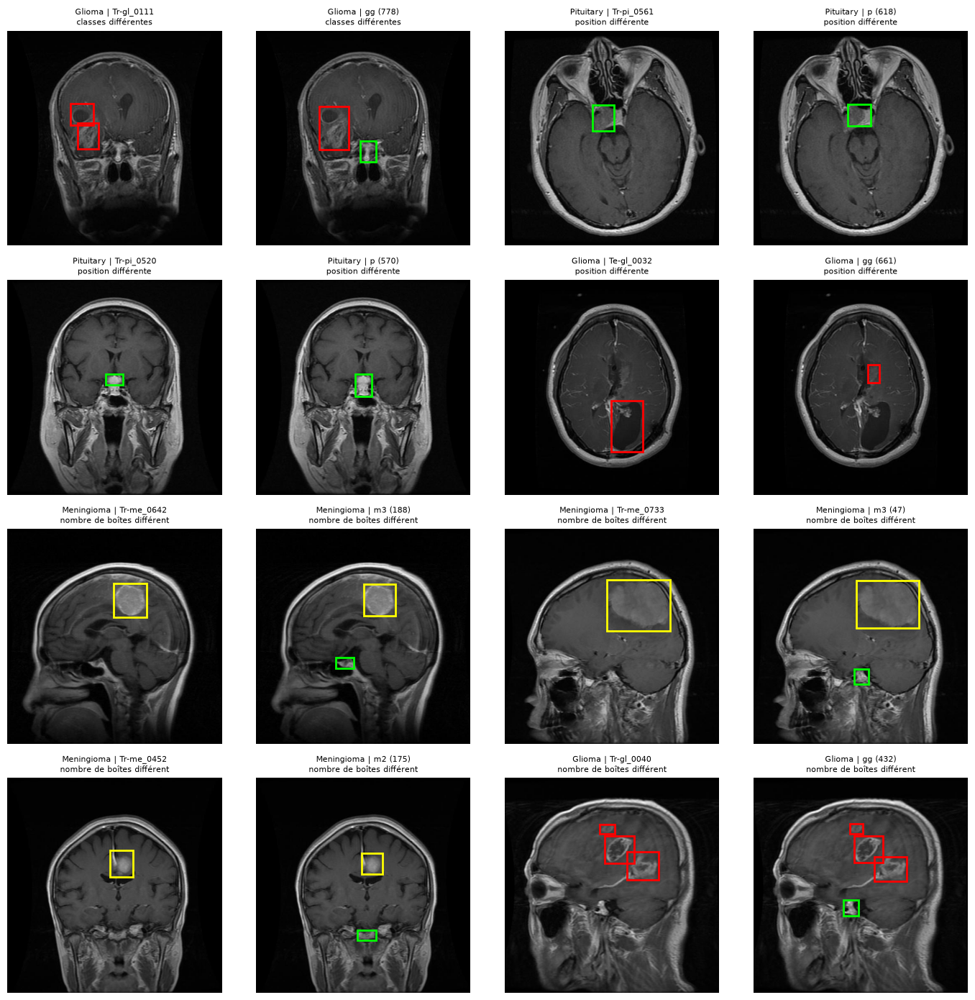

In [39]:
# CE QUE FAIT CETTE CELLULE (étape 1.8d, jumeaux aux boîtes différentes)
# Tire 8 groupes dont les boîtes diffèrent (1 "classes différentes", 3 "position différente",
# 4 "nombre de boîtes différent") et affiche les deux premières images de chaque groupe
# avec leurs rectangles, pour voir d'où vient la différence.
import matplotlib.pyplot as plt
from pathlib import Path
from src.data import draw_image_with_boxes

picks = []
for verdict, k in [("classes différentes", 1), ("position différente", 3), ("nombre de boîtes différent", 4)]:
    sub = cmp[cmp.verdict == verdict]
    picks += sub.sample(min(k, len(sub)), random_state=42)["group_id"].tolist()

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for ax in axes.flat:
    ax.axis("off")
for n, gid in enumerate(picks):
    twin = m[(m.group_id == gid) & (m.status == "ok")].sort_values("image_path").head(2)
    verdict = cmp.loc[cmp.group_id == gid, "verdict"].iloc[0]
    for j, (_, r) in enumerate(twin.iterrows()):
        draw_image_with_boxes(axes.flat[n * 2 + j], r["image_path"], r["label_path"],
                              f"{r['class']} | {Path(r['image_path']).stem}\n{verdict}")
plt.tight_layout()
plt.show()

**Résultats 1.8 : découpage par groupes**

**Indicateurs d'utilisation** : 5 234 images utilisables en classification, 4 422 en détection (comme attendu).

**Boîtes des jumeaux (1.8a)** : sur 1 286 groupes avec au moins 2 images annotées, 1 183 (92,0 %) ont des boîtes identiques, 89 un nombre de boîtes différent, 13 une position différente, 1 des classes différentes.

| Classe | Groupes annotés | Groupes aux boîtes différentes |
|---|---|---|
| Glioma | 106 | 24 (22,6 %) |
| Meningioma | 477 | 44 (9,2 %) |
| Pituitary | 512 | 35 (6,8 %) |
| No Tumor | 191 | 0 |

**Représentants (1.8b)** : 3 632 représentants (un par groupe utilisable), aucun groupe avec deux représentants, aucun représentant écarté de la détection à tort. 10 groupes ne contiennent que des images en conflit.

**Découpage (1.8c)** : 70,0 / 15,0 / 15,0 % des images distinctes, aucun groupe coupé.

| Classe | Train | Val | Test |
|---|---|---|---|
| Glioma | 822 | 176 | 176 |
| Meningioma | 753 | 162 | 162 |
| No Tumor | 250 | 54 | 54 |
| Pituitary | 717 | 153 | 153 |
| Total | 2 542 | 545 | 545 |

Fichiers (copies comprises) : train 3 663, val 741, test 830, écartés 15.

- Les copies des représentants de val et test **restent dans leur split** (pour ne pas fuir vers l'entraînement) mais ne servent pas au calcul des scores.
- Des 512 images de l'ancienne Val : 360 en train, 70 en val, 82 en test.
- Aucune famille de noms ne manque en val ou test ; `Te-pi_#` (petite famille) est à 27 % en val : écart de hasard à surveiller.

**Décision ouverte** : en entraînement, `No Tumor` a 2,2 copies par image distincte (Glioma : 1,1). Garder toutes les copies sur-représente `No Tumor` sans le vouloir. À trancher au Jour 2 (classification) et au Jour 5 (YOLO).

**Limites à documenter**
- `No Tumor` n'a que 54 images distinctes en val et en test : une erreur de plus ou de moins déplace son rappel d'environ 1,9 point.
- Sans identifiant de patient, des coupes voisines peuvent se retrouver dans des splits différents.
- Les copies très modifiées (corr < 0,99) peuvent ne pas être regroupées.

**Résultats 1.8d : jumeaux aux boîtes différentes (8 groupes regardés)**

- **Nombre de boîtes différent (4 groupes sur 4)** : la version riche a une petite boîte Pituitary en plus, sur la zone de l'hypophyse. Les versions pauvres de la famille `Tr-`. À confirmer sur les 89 groupes (1.8e).
- **Classes différentes (1 groupe)** : `Tr-gl_0111` a deux boîtes Glioma ; `gg (778)` a une grande boîte Glioma et une boîte Pituitary.
- **Position différente (3 groupes)** : même lésion encadrée avec une taille et une position un peu différentes (`Tr-pi_0561` / `p (618)`, `Tr-pi_0520` / `p (570)`), ou deux zones différentes (`Te-gl_0032` / `gg (661)`).

**Conséquences**
- La règle « le plus de boîtes » choisit la version avec la boîte Pituitary en plus. Le manifeste garde la colonne `consistency` : au Jour 5, YOLO sera évalué sur tout le test **et** sur les images `all_match` seulement.
- **Indice de source possible** : la boîte en plus semble liée à certaines familles de noms. YOLO pourrait apprendre le style d'une source. À confirmer en 1.8e.
- **Plafond de mesure** : quand deux annotations valides d'une même image se recouvrent peu, aucun modèle ne peut obtenir un score parfait (13 groupes sur 1 286).

In [40]:
# CE QUE FAIT CETTE CELLULE (étape 1.8e, d'où vient la différence de nombre de boîtes ?)
# Pour les groupes dont les jumeaux n'ont pas le même nombre de boîtes, compare la version
# qui en a le plus à celle qui en a le moins, puis affiche :
#   - quelles boîtes sont en plus (type de tumeur),
#   - de quelles familles de noms viennent les deux versions.
# Cela confirme (ou non) ce qu'on a vu sur 4 exemples. Rien n'est modifié.
from src.split import extra_box_summary

ex = extra_box_summary(m, boxes, cmp)
print(f"Groupes étudiés : {len(ex)}")
print("\nBoîtes en plus dans la version la plus riche :")
display(ex["boîtes en plus"].value_counts())
print("Familles de la version riche (8 premières) :")
display(ex["famille riche"].value_counts().head(8))
print("Familles de la version pauvre (8 premières) :")
display(ex["famille pauvre"].value_counts().head(8))

Groupes étudiés : 89

Boîtes en plus dans la version la plus riche :


boîtes en plus
Pituitary x1                71
Glioma x1                    7
Meningioma x1                6
Pituitary x2                 3
Glioma x1, Meningioma x1     1
Glioma x1, Pituitary x1      1
Name: count, dtype: int64

Familles de la version riche (8 premières) :


famille riche
m# (#)     22
Tr-me_#    17
Tr-pi_#    17
gg (#)     12
p (#)       9
Te-gl_#     6
Tr-gl_#     2
m (#)       2
Name: count, dtype: int64

Familles de la version pauvre (8 premières) :


famille pauvre
Tr-me_#    25
p (#)      18
m# (#)     16
Tr-gl_#    10
Tr-pi_#     8
gg (#)      7
Te-gl_#     2
m (#)       2
Name: count, dtype: int64

## 1.9 Le manifeste
Toutes nos décisions sont rassemblées dans **un seul fichier** : `manifests/manifest.csv` (une ligne par image, 5 249 lignes), avec un résumé des chiffres clés dans `manifests/data_report.json`. Les images ne sont ni copiées ni déplacées : le manifeste ne fait que **pointer** vers elles.

Il est versionné dans Git (le dossier `data/` est ignoré), ce qui fige le découpage. Notebook, Airflow et Streamlit liront ce même fichier.

**Colonnes** : chemins de l'image et de l'annotation, classe, `split` (train, val, test, excluded), `is_representative`, `group_id`, `group_size`, `status`, `consistency`, `n_boxes`, `use_for_classification`, `use_for_detection`, `split_origin`, famille de nom, sha256, dimensions, mode, format et poids.

Une fonction de **validation** contrôle le fichier : aucun groupe coupé, un représentant par groupe, fichiers existants, pas de `No Tumor` en détection, etc. Elle sera réutilisée dans Airflow.

In [41]:
# CE QUE FAIT CETTE CELLULE (étape 1.9, construction et validation du manifeste)
# 1) Assemble le manifeste à partir du tableau final (m) et des propriétés des images (props).
# 2) Le valide : un représentant par groupe, aucun groupe coupé, fichiers présents sur le disque, etc.
# Résultat attendu : 5249 lignes, 20 colonnes, "Problèmes détectés : aucun".
from src.manifest import build_manifest, validate_manifest, build_report

manifest = build_manifest(m, props)
problems = validate_manifest(manifest)
print("Lignes :", len(manifest), "| colonnes :", manifest.shape[1])
print("Problèmes détectés :", problems if problems else "aucun")
display(manifest.head(3))

Lignes : 5249 | colonnes : 20
Problèmes détectés : aucun


,image_path,label_path,class,split,is_representative,group_id,group_size,status,consistency,n_boxes,use_for_classification,use_for_detection,split_origin,name_pattern,sha256,width,height,mode,format,size_kb
0,data/raw/Train/Glioma/images/Te-glTr_0000.jpg,data/raw/Train/Glioma/labels/Te-glTr_0000.txt,Glioma,train,False,0,2,ok,all_match,1,True,True,Train,Te-glTr_#,b513a83f68e486f45159b004d356782e78284014532151...,512,512,RGB,JPEG,25.2
1,data/raw/Train/Glioma/images/Te-glTr_0005.jpg,data/raw/Train/Glioma/labels/Te-glTr_0005.txt,Glioma,train,True,1,2,ok,all_match,1,True,True,Train,Te-glTr_#,99823a94a0e5771885b4a351f4226646e05ac28dc26c16...,512,512,RGB,JPEG,17.8
2,data/raw/Train/Glioma/images/Te-glTr_0007.jpg,data/raw/Train/Glioma/labels/Te-glTr_0007.txt,Glioma,val,True,2,2,ok,all_match,1,True,True,Train,Te-glTr_#,0732a1bdd51f692954619b0b9eaaa75e2afde9895d5b78...,512,512,RGB,JPEG,20.1


In [42]:
# CE QUE FAIT CETTE CELLULE
# Relit configs/config.yaml (la variable cfg est une copie en mémoire, elle ne suit pas
# les modifications du fichier) et vérifie que la clé "manifests" est bien présente.
cfg = load_config()
print(cfg["paths"])

{'raw': 'data/raw', 'processed': 'data/processed', 'yolo': 'data/yolo', 'models': 'models', 'metrics': 'reports/metrics', 'figures': 'reports/figures', 'manifests': 'manifests'}


In [43]:
# CE QUE FAIT CETTE CELLULE (étape 1.9, enregistrement)
# Écrit manifests/manifest.csv et manifests/data_report.json (les chiffres clés :
# tailles par split, seuils des doublons, graine, images écartées, annotations orphelines).
from src.manifest import save_manifest

report = build_report(manifest, inv, cfg)
out = save_manifest(manifest, report, cfg["paths"]["manifests"])
print("Écrit dans :", out)
print("Fichiers :", sorted(p.name for p in out.iterdir()))
print({k: report[k] for k in ["n_images", "n_groups", "use_for_classification", "use_for_detection"]})

Écrit dans : /home/hammo/projects/IRM_detection/manifests
Fichiers : ['data_report.json', 'manifest.csv']
{'n_images': 5249, 'n_groups': 3642, 'use_for_classification': 5234, 'use_for_detection': 4422}


In [44]:
# CE QUE FAIT CETTE CELLULE (étape 1.9, relecture)
# Relit le fichier depuis le disque, comme le feront Airflow et Streamlit, le valide de nouveau
# et réaffiche le tableau des images distinctes par classe et par split.
from src.manifest import load_manifest

back = load_manifest(f'{cfg["paths"]["manifests"]}/manifest.csv')
print("Relu :", back.shape, "| même taille que l'original :", back.shape == manifest.shape)
print("Problèmes après relecture :", validate_manifest(back) or "aucun")
r = back[back.is_representative]
display(pd.crosstab(r["class"], r["split"], margins=True))

Relu : (5249, 20) | même taille que l'original : True
Problèmes après relecture : aucun


split,test,train,val,All
class,,,,
Glioma,176,822,176,1174
Meningioma,162,753,162,1077
No Tumor,54,250,54,358
Pituitary,153,717,153,1023
All,545,2542,545,3632


**Résultats 1.8e : d'où vient la différence de nombre de boîtes (89 groupes)**

| Boîtes en plus dans la version la plus riche | Groupes |
|---|---|
| Pituitary x1 | 71 |
| Glioma x1 | 7 |
| Meningioma x1 | 6 |
| Pituitary x2 | 3 |
| Glioma x1 + Meningioma x1 | 1 |
| Glioma x1 + Pituitary x1 | 1 |

- Dans 75 groupes sur 89, la boîte en plus est de type Pituitary. 26 groupes sont dans le dossier Pituitary (une boîte en plus de la même classe) : il reste **au moins 49 groupes sur 63** (Glioma et Meningioma) où il s'agit de la boîte sur la zone de l'hypophyse.
- **Pas de lien net avec une famille de noms** : la version riche vient de toutes les familles, y compris `Tr-me_#` (17), `Tr-pi_#` (17) et `Te-gl_#` (6). L'hypothèse d'un indice de source, formulée après 4 exemples, n'est **pas confirmée**.
- **Effet de la règle « le plus de boîtes »** : elle retient la version avec la boîte en plus pour moins de 2 % des groupes (63 sur 3 632). Le manifeste garde `consistency` pour évaluer YOLO aussi sans ces images (Jour 5).

## 1.8f Les images `mixed` viennent-elles de certaines familles ?
La question de l'indice de source reste posée pour **toutes** les images `mixed` (257), pas seulement les jumeaux. On regarde, pour chaque famille de noms d'au moins 30 images, quelle part est `mixed` ou `none_match`.

In [45]:
# CE QUE FAIT CETTE CELLULE (étape 1.8f, les images "mixed" par famille de noms)
# Pour chaque famille de noms d'au moins 30 images, calcule la part d'images "mixed" (au moins une
# boîte d'un autre type que le dossier) et "none_match". Si quelques familles concentrent presque
# tous les "mixed", la présence de la boîte en trop trahit la source. Rien n'est modifié.
t = pd.crosstab(back["name_pattern"], back["consistency"])
t["total"] = t.sum(axis=1)
t["part mixed (%)"] = (t["mixed"] / t["total"] * 100).round(1)
display(t[t.total >= 30].sort_values("part mixed (%)", ascending=False).head(10))

consistency,all_match,mixed,no_box,none_match,total,part mixed (%)
name_pattern,,,,,,
gg (#),618,107,1,1,727,14.7
Te-gl_#,86,12,0,1,99,12.1
Tr-gl_#,413,43,0,1,457,9.4
m# (#),381,36,0,1,418,8.6
Tr-me_#,721,50,0,3,774,6.5
m (#),187,6,0,7,200,3.0
m#(#),190,2,0,0,192,1.0
Tr-no_#,478,0,0,0,478,0.0
Te-pi_#,39,0,0,0,39,0.0


**Résultats 1.9 : manifeste**
- `manifests/manifest.csv` : 5 249 lignes, 20 colonnes ; `manifests/data_report.json` : chiffres clés.
- Validation : aucun problème avant écriture et après relecture ; tableau relu identique.
- 3 642 groupes ; 5 234 images utilisables en classification ; 4 422 en détection ; 15 images `excluded`.
- Images distinctes (représentants) : train 2 542, val 545, test 545.
- Le fichier est versionné dans Git ; `group_id` est un simple numéro, le manifeste fait foi (on ne le recalcule pas).

# 2. Prétraitement et Data Augmentation

**Objectif :** préparer ce que les modèles vont lire, à partir du manifeste. Aucun fichier du dataset n'est modifié ni copié (sauf le dossier YOLO, fait de liens, à l'étape 2.7).

**Décisions du Jour 2**
- **D1 Copies en entraînement :** un représentant par groupe (réglage `train_dedup`, comparaison avec `all` possible au Jour 4).
- **D2 Mise au carré :** bandes de la couleur du fond (médiane des pixels du bord), pas d'étirement ni de rognage.
- **D3 Mode :** niveaux de gris copiés sur 3 canaux, pour toutes les images.
- **D4 Réglages :** 224×224 pour la classification ; normalisation placée dans le modèle ; lecture à la volée avec cache en mémoire.
- **D5 Augmentations :** couches Keras pour la classification (rotation ±15°, translation ±10 %, zoom ±15 %, contraste ±20 %, luminosité ±15 %, flou léger et variation de résolution contre le raccourci de source) ; pas de retournement gauche-droite dans la version de base ; YOLO utilise ses propres augmentations.
- **D6 Dossier YOLO :** liens vers les images, annotations réécrites en 3 classes (Glioma 0, Meningioma 1, Pituitary 2).

In [46]:
# CE QUE FAIT CETTE CELLULE (GPU) : À PLACER TOUT EN HAUT, AVANT TOUT IMPORT DE TENSORFLOW
# Charge les bibliothèques CUDA 12 du .venv pour que TensorFlow trouve le GPU (les bibliothèques CUDA 13,
# utilisées par PyTorch, sont ignorées). Affiche les GPU vus par TensorFlow. Rien n'est modifié sur le disque.
import ctypes, glob, site

base = site.getsitepackages()[0] + "/nvidia"
noms = ["libnvJitLink.so.12", "libcudart.so.12", "libcublasLt.so.12", "libcublas.so.12", "libcufft.so.11",
        "libcurand.so.10", "libcusparse.so.12", "libcusolver.so.11", "libnvrtc.so.12", "libcupti.so.12",
        "libcudnn.so.9"]
for nom in noms:
    trouves = [p for p in glob.glob(f"{base}/*/lib/{nom}") if "/cu13/" not in p]
    try:
        ctypes.CDLL(trouves[0], mode=ctypes.RTLD_GLOBAL)
    except Exception as e:
        print("échec :", nom, "->", str(e)[:80])

import tensorflow as tf
print("GPU vus par TensorFlow :", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793468451.724874   49058 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793468452.022666   49058 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793468454.133456   49058 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU vus par TensorFlow : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [47]:
# CE QUE FAIT CETTE CELLULE (début du Jour 2, configuration et manifeste)
# Relit la configuration (modifiée pour le Jour 2) et recharge le manifeste depuis le disque.
# Définit les réglages utilisés dans toutes les cellules du Jour 2 : taille d'image, mode des
# bandes, choix pour les copies en entraînement, liste des classes.
# Contrôle que les classes de la config correspondent à celles du manifeste.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, ROOT
from src.manifest import load_manifest
from src.preprocessing import select_images, load_gray, preprocess_image, plot_before_after

cfg = load_config()
manifest = load_manifest(f'{cfg["paths"]["manifests"]}/manifest.csv')

SIZE = cfg["data"]["image_size"]
PAD = cfg["preprocessing"]["pad_mode"]
DEDUP = cfg["preprocessing"]["train_dedup"]
CLASSES = cfg["data"]["classes"]
assert sorted(CLASSES) == sorted(manifest["class"].unique()), "classes de la config différentes du manifeste"

print(f"Manifeste : {manifest.shape} | taille {SIZE} | bandes '{PAD}' | copies en train '{DEDUP}'")
print("Classes :", CLASSES)

Manifeste : (5249, 20) | taille 224 | bandes 'background' | copies en train 'representative'
Classes : ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 2.1 Listes d'images par split
`select_images` lit le manifeste et renvoie, pour un split et une tâche :
- **validation et test :** un représentant par groupe (chaque image distincte compte une fois) ;
- **entraînement :** un représentant par groupe, ou toutes les copies selon `train_dedup` ;
- seulement les images utilisables pour la tâche (`use_for_classification` ou `use_for_detection`).

**Attendu en classification :** 2 542 / 545 / 545 images. En détection, il n'y a pas de `No Tumor`.

In [48]:
# CE QUE FAIT CETTE CELLULE (étape 2.1, listes d'images par split)
# Pour chaque tâche (classification, détection) et chaque split, appelle select_images et
# compte les images par classe. Affiche aussi le nombre de fichiers d'entraînement si on
# gardait toutes les copies (option "all"), pour comparaison.
frames = []
for task in ("classification", "detection"):
    for split in ("train", "val", "test"):
        df = select_images(manifest, split, task, DEDUP)
        s = df["class"].value_counts().reindex(CLASSES, fill_value=0)
        s["total"] = len(df)
        s.name = f"{task} | {split}"
        frames.append(s)
display(pd.DataFrame(frames))

print("Entraînement avec toutes les copies :", len(select_images(manifest, "train", "classification", "all")), "fichiers")

class,Glioma,Meningioma,No Tumor,Pituitary,total
classification | train,822,753,250,717,2542
classification | val,176,162,54,153,545
classification | test,176,162,54,153,545
detection | train,821,753,0,717,2291
detection | val,176,162,0,153,491
detection | test,176,162,0,153,491


Entraînement avec toutes les copies : 3663 fichiers


## 2.2 Chargement en niveaux de gris
`load_gray` ouvre une image et renvoie un tableau 2D de valeurs entre 0 et 255.
- Les images RGB et en niveaux de gris sont converties en un seul canal : la différence de mode entre classes disparaît (D3).
- Les PNG transparents (RGBA, ou palette avec transparence) sont d'abord posés sur fond noir, sinon les pixels transparents garderaient des couleurs arbitraires.

On vérifie le chargement sur les 4 faux JPG (modes RGBA et P) et sur 200 images au hasard.

In [49]:
# CE QUE FAIT CETTE CELLULE (étape 2.2, vérification du chargement)
# 1) Charge les 4 faux JPG (PNG en mode RGBA ou P) et affiche forme, type et valeurs.
# 2) Charge 200 images au hasard et vérifie qu'elles sont toutes en 2D.
# 3) Affiche leurs modes d'origine, pour voir la variété qu'on vient d'uniformiser.

special = manifest[manifest["mode"].isin(["RGBA", "P"])]
print("Images en mode RGBA ou P :", len(special), "(attendu 4)")
for _, r in special.iterrows():
    g = load_gray(ROOT / r["image_path"])
    name = r["image_path"].split("/")[-1]
    print(f"{name:<18} mode {r['mode']:<5} -> forme {g.shape}, type {g.dtype}, valeurs {g.min()} à {g.max()}")

sample = manifest[manifest.use_for_classification].sample(200, random_state=42)
print("\n200 images au hasard : toutes en 2D ->", all(load_gray(ROOT / p).ndim == 2 for p in sample.image_path))
print("Modes d'origine de l'échantillon :", sample["mode"].value_counts().to_dict())

Images en mode RGBA ou P : 4 (attendu 4)
Tr-no_1011.jpg     mode RGBA  -> forme (664, 550), type uint8, valeurs 0 à 254
Tr-no_1012.jpg     mode P     -> forme (725, 728), type uint8, valeurs 0 à 255
Tr-no_1019.jpg     mode RGBA  -> forme (400, 393), type uint8, valeurs 7 à 255
Tr-no_1020.jpg     mode RGBA  -> forme (454, 442), type uint8, valeurs 0 à 255

200 images au hasard : toutes en 2D -> True
Modes d'origine de l'échantillon : {'RGB': 171, 'L': 29}


## 2.3 Mise au carré et redimensionnement
Trois opérations, dans cet ordre :
1. **Bandes** de la couleur du fond (médiane des pixels du bord) pour rendre l'image carrée, sans déformer le cerveau. Une image déjà carrée n'est pas modifiée.
2. **Redimensionnement** à 224×224 (interpolation bilinéaire).
3. **Copie sur 3 canaux** : MobileNetV2 attend 3 canaux.

Le résultat reste en entiers de 0 à 255 (`uint8`) : la normalisation sera faite dans le modèle au Jour 3. Une image prétraitée pèse environ 150 Ko, donc le cache en mémoire de l'entraînement fera environ 380 Mo.

**D'abord :** combien d'images reçoivent des bandes, selon la classe ? (part de l'image carrée finale occupée par des bandes = 1 − petit côté / grand côté).

In [50]:
# CE QUE FAIT CETTE CELLULE (étape 2.3, combien d'images reçoivent des bandes ?)
# Pour chaque image utilisable, calcule la part de l'image carrée finale occupée par des bandes
# (0 si l'image est déjà carrée). Résume par classe : nombre d'images avec bandes, part en %,
# et part moyenne de bandes pour celles qui en ont. Aucun fichier n'est ouvert.
use = manifest[manifest.use_for_classification].copy()
use["part_bandes"] = 1 - use[["width", "height"]].min(axis=1) / use[["width", "height"]].max(axis=1)

summary = use.groupby("class")["part_bandes"].agg(
    images_avec_bandes=lambda s: int((s > 0).sum()),
    part_des_images_pct=lambda s: round((s > 0).mean() * 100, 1),
    bandes_moyennes_pct=lambda s: round(s[s > 0].mean() * 100, 1) if (s > 0).any() else 0.0,
)
display(summary)

,images_avec_bandes,part_des_images_pct,bandes_moyennes_pct
class,,,
Glioma,0,0.0,0.0
Meningioma,174,11.0,11.9
No Tumor,513,63.3,13.2
Pituitary,10,0.6,5.9


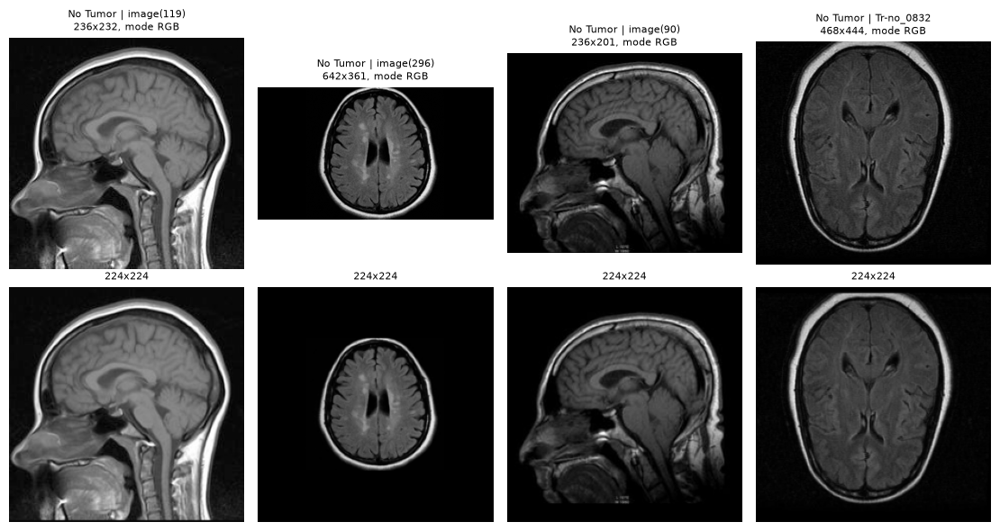

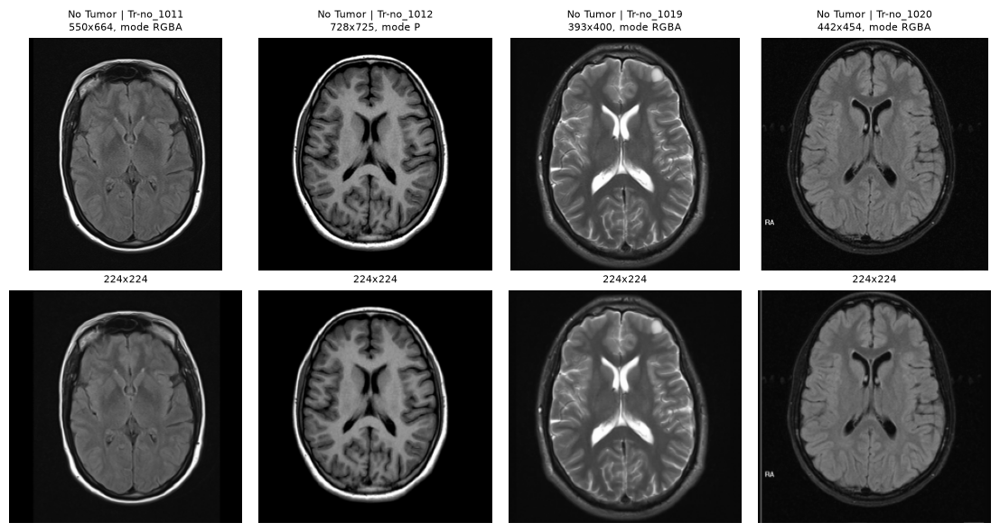

In [51]:
# CE QUE FAIT CETTE CELLULE (étape 2.3, contrôle visuel avant / après)
# Figure 1 : 4 images No Tumor non carrées au hasard ; ligne du haut = image d'origine,
#            ligne du bas = image prétraitée (224x224 avec bandes).
# Figure 2 : les 4 faux JPG (RGBA et P), pour vérifier que la transparence est bien traitée.
nt = manifest[(manifest["class"] == "No Tumor") & (manifest["width"] != manifest["height"])
              & manifest.use_for_classification]
plot_before_after(nt.sample(4, random_state=42), SIZE, PAD, ROOT / cfg["paths"]["figures"] / "preproc_notumor.png")
plot_before_after(special, SIZE, PAD, ROOT / cfg["paths"]["figures"] / "preproc_special.png")

In [52]:
# CE QUE FAIT CETTE CELLULE (étape 2.3, passage sur toutes les images)
# Prétraite les 5 234 images utilisables et vérifie pour chacune : forme (224, 224, 3), type uint8,
# et trois canaux identiques. Affiche le temps total et les erreurs éventuelles.
import time

subset = manifest[manifest.use_for_classification]
errors, t0 = [], time.time()
for p in subset.image_path:
    try:
        x = preprocess_image(p, SIZE, PAD)
        assert x.shape == (SIZE, SIZE, 3) and x.dtype == np.uint8
        assert (x[..., 0] == x[..., 1]).all() and (x[..., 1] == x[..., 2]).all()
    except Exception as e:
        errors.append((p, repr(e)))

print(f"{len(subset)} images prétraitées en {time.time() - t0:.0f} s | erreurs : {len(errors)}")
errors[:5]

5234 images prétraitées en 8 s | erreurs : 0


[]

**Résultats 2.1 à 2.3**

**Listes (2.1)** : classification 2 542 / 545 / 545 ; détection 2 291 / 491 / 491 (3 273 au total, sans `No Tumor`). Glioma passe de 822 à 821 en entraînement : probablement l'image au fichier d'annotation vide. Avec toutes les copies : 3 663 fichiers d'entraînement.

**Chargement (2.2)** : les 4 faux JPG (RGBA, P) se chargent correctement. Sur 200 images au hasard : 171 RGB, 29 niveaux de gris, toutes converties en 2D.

**Bandes (2.3)** : 697 images reçoivent des bandes (Meningioma 174, No Tumor 513, Pituitary 10, Glioma 0). 74 % des images avec bandes sont des `No Tumor`. Part des bandes dans l'image carrée : 12 à 13 % pour Meningioma et No Tumor. Les bandes sont donc une piste de source possible si elles ne se fondent pas dans le fond.

**Passage sur toutes les images utilisables** : 5 234 images en 10 s, 0 erreur.

**Contrôle visuel** : les bandes se fondent dans le fond noir pour les images ordinaires. Défaut sur les PNG transparents (`Tr-no_1011`, `Tr-no_1020`) : bandes plus sombres que le fond. Cause probable : bords transparents posés sur fond noir, donc fond estimé à 0. Correction en 2.3b.

## 2.3b La couleur des bandes est-elle bien choisie ?
Ancienne estimation du fond : médiane des pixels du bord (1 pixel). Elle est trompée quand les bords sont transparents (posés sur fond noir).

**Nouvelle estimation** : 25e percentile d'un liseré de 3 % le long des 4 bords (le fond est la zone la plus sombre).

On compare les deux sur les 697 images qui reçoivent des bandes : combien ont un écart de plus de 8 niveaux de gris (sur 255) ? Pour les PNG transparents, on mesure la part de pixels transparents dans l'image et dans le liseré de 3 % : si la marge transparente est plus large que le liseré, la nouvelle méthode serait encore trompée.

In [53]:
# CE QUE FAIT CETTE CELLULE (étape 2.3b, la couleur des bandes est-elle bien choisie ?)
# 1) Pour les images qui reçoivent des bandes, compare l'ancienne estimation du fond (médiane du
#    bord d'un pixel) à la nouvelle (25e percentile d'un liseré de 3 %), et compte les images où
#    l'écart dépasse 8 puis 20 niveaux de gris, par classe.
# 2) Pour les PNG transparents, mesure la part de pixels transparents dans l'image et dans le liseré.
from PIL import Image
from src.preprocessing import estimate_background, border_median

banded = use[use.part_bandes > 0]
old, new = [], []
for p in banded.image_path:
    g = load_gray(ROOT / p)
    old.append(border_median(g))
    new.append(estimate_background(g))
banded = banded.assign(ancien=old, nouveau=new)
banded["ecart"] = (banded["ancien"] - banded["nouveau"]).abs()

print(f"Images avec bandes : {len(banded)}")
for t in (8, 20):
    print(f"Écart >= {t} niveaux de gris : {int((banded.ecart >= t).sum())} images")
display(banded[banded.ecart >= 8].groupby("class").size().rename("images avec écart >= 8"))
display(banded.sort_values("ecart", ascending=False)[["image_path", "class", "ancien", "nouveau", "ecart"]].head(8))

for _, r in special[special["mode"] == "RGBA"].iterrows():
    alpha = np.asarray(Image.open(ROOT / r["image_path"]).convert("RGBA"))[..., 3]
    k = max(2, int(0.03 * min(alpha.shape)))
    edge = np.concatenate([alpha[:k].ravel(), alpha[-k:].ravel(), alpha[:, :k].ravel(), alpha[:, -k:].ravel()])
    name = r["image_path"].split("/")[-1]
    print(f"{name}: transparent sur {np.mean(alpha < 255) * 100:.1f} % de l'image, {np.mean(edge < 255) * 100:.1f} % du liseré")

Images avec bandes : 697
Écart >= 8 niveaux de gris : 104 images
Écart >= 20 niveaux de gris : 70 images


class
Meningioma    27
No Tumor      73
Pituitary      4
Name: images avec écart >= 8, dtype: int64

,image_path,class,ancien,nouveau,ecart
3366,data/raw/Train/Pituitary/images/Tr-pi_0030.jpg,Pituitary,255,0,255
3954,data/raw/Train/Pituitary/images/p (126).jpg,Pituitary,255,0,255
1488,data/raw/Train/Meningioma/images/Tr-me_0583.jpg,Meningioma,250,9,241
2408,data/raw/Train/Meningioma/images/m3 (133).jpg,Meningioma,250,9,241
3236,data/raw/Train/No Tumor/images/image(289).jpg,No Tumor,251,22,229
2673,data/raw/Train/No Tumor/images/Tr-no_0278.jpg,No Tumor,251,22,229
2704,data/raw/Train/No Tumor/images/Tr-no_0418.jpg,No Tumor,195,0,195
3133,data/raw/Train/No Tumor/images/image(15).jpg,No Tumor,185,3,182


Tr-no_1011.jpg: transparent sur 0.0 % de l'image, 0.0 % du liseré
Tr-no_1019.jpg: transparent sur 0.0 % de l'image, 0.0 % du liseré
Tr-no_1020.jpg: transparent sur 0.0 % de l'image, 0.0 % du liseré


## 2.4 Normalisation
Les modèles préentraînés attendent des valeurs de pixels sur une échelle précise :
- **MobileNetV2** : entre -1 et 1 ;
- **ResNet50** : conversion RGB → BGR puis soustraction de la moyenne ImageNet (valeurs d'environ -124 à +151).

**Décision (D4) : la normalisation est placée dans le modèle**, pas dans notre pipeline. Notre pipeline livre toujours des entiers de 0 à 255. Ainsi Streamlit et Airflow donneront le même résultat qu'à l'entraînement, sans risque d'oublier une étape, et ResNet50 pourra être comparé à MobileNetV2 sans toucher aux données.

**Détail pour le Jour 3 :** le premier calque du modèle convertira les entiers en décimaux (`float32`) avant la normalisation. On vérifie ici que nos images sont au bon format pour les deux modèles.

In [54]:
# CE QUE FAIT CETTE CELLULE (étape 2.4, normalisation)
# Prétraite 16 images au hasard, puis applique les deux normalisations des modèles préentraînés :
#   - MobileNetV2 : valeurs entre -1 et 1 ;
#   - ResNet50 : RGB -> BGR puis soustraction de la moyenne ImageNet.
# Montre que nos images (entiers 0-255) conviennent aux deux modèles.
# C'est la première fois que TensorFlow est chargé dans le notebook : on limite sa mémoire GPU.
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
from tensorflow.keras.applications import mobilenet_v2, resnet50

batch = np.stack([preprocess_image(p, SIZE, PAD) for p in subset.sample(16, random_state=0).image_path])
print("Lot :", batch.shape, batch.dtype, "| valeurs", batch.min(), "à", batch.max())

mb = mobilenet_v2.preprocess_input(batch.astype("float32").copy())
rn = resnet50.preprocess_input(batch.astype("float32").copy())
print(f"MobileNetV2 : {mb.min():.2f} à {mb.max():.2f}  (attendu : environ -1 à 1)")
print(f"ResNet50    : {rn.min():.1f} à {rn.max():.1f}  (attendu : environ -124 à +151)")

Lot : (16, 224, 224, 3) uint8 | valeurs 0 à 254
MobileNetV2 : -1.00 à 0.99  (attendu : environ -1 à 1)
ResNet50    : -123.7 à 150.1  (attendu : environ -124 à +151)


**Résultats 2.3b et 2.4**

**2.3b : couleur des bandes**
- L'ancienne estimation du fond (médiane du bord d'un pixel) se trompait de plus de 8 niveaux de gris sur 104 des 697 images avec bandes (15 %), et de plus de 20 sur 70. Les pires cas donnaient 255 (bandes blanches sur fond noir).
- Par classe : No Tumor 73 sur 513, Meningioma 27 sur 174, Pituitary 4 sur 10. Taux semblables : du bruit, pas un indice de classe.
- **Nouvelle estimation retenue** : 25e percentile d'un liseré de 3 % le long des 4 bords.
- Les 3 PNG RGBA sont entièrement opaques (0,0 % de transparence) : l'hypothèse de bords transparents était fausse. Les fines lignes visibles sur `Tr-no_1011` et `Tr-no_1020` restent à expliquer (2.3c).

**2.4 : normalisation** (16 images au hasard)
- MobileNetV2 : -1,00 à 0,99. ResNet50 : -123,7 à 150,1. Conforme.
- Décision D4 confirmée : le pipeline livre des entiers 0-255, la normalisation est dans le modèle.

## 2.3c Les bandes sont-elles visibles à côté de l'image ?
Pour chaque image qui reçoit des bandes, on mesure la **marche** : l'écart entre la couleur des bandes (fond estimé sur le liseré de 3 %) et le fond proche du bord à l'intérieur de l'image (zone de 8 % à 20 % de la largeur ou de la hauteur, sur les côtés où les bandes sont ajoutées).

Une marche supérieure à 8 niveaux de gris (sur 255) donne des bandes visibles. On compte par classe et on affiche les 4 pires cas.

**Règle de décision :** si peu d'images sont concernées et que leur part est semblable d'une classe à l'autre, on accepte et on documente. Sinon, on prend le fond proche comme couleur des bandes.

Marche >= 8 niveaux de gris : 87 images sur 697
Marche >= 15 niveaux de gris : 47 images sur 697


,images,marche_ge_8,marche_moyenne
class,,,
Meningioma,174,36,6.0
No Tumor,513,44,2.5
Pituitary,10,7,24.1


,image_path,class,fill,fond_proche,marche
2116,data/raw/Train/Meningioma/images/m1(172).jpg,Meningioma,0,62,62
2114,data/raw/Train/Meningioma/images/m1(170).jpg,Meningioma,0,62,62
2072,data/raw/Train/Meningioma/images/m1(126).jpg,Meningioma,14,63,49
1255,data/raw/Train/Meningioma/images/Tr-me_0202.jpg,Meningioma,14,63,49
3954,data/raw/Train/Pituitary/images/p (126).jpg,Pituitary,0,44,44
3366,data/raw/Train/Pituitary/images/Tr-pi_0030.jpg,Pituitary,0,44,44
1309,data/raw/Train/Meningioma/images/Tr-me_0367.jpg,Meningioma,22,63,41
2217,data/raw/Train/Meningioma/images/m1(99).jpg,Meningioma,22,63,41


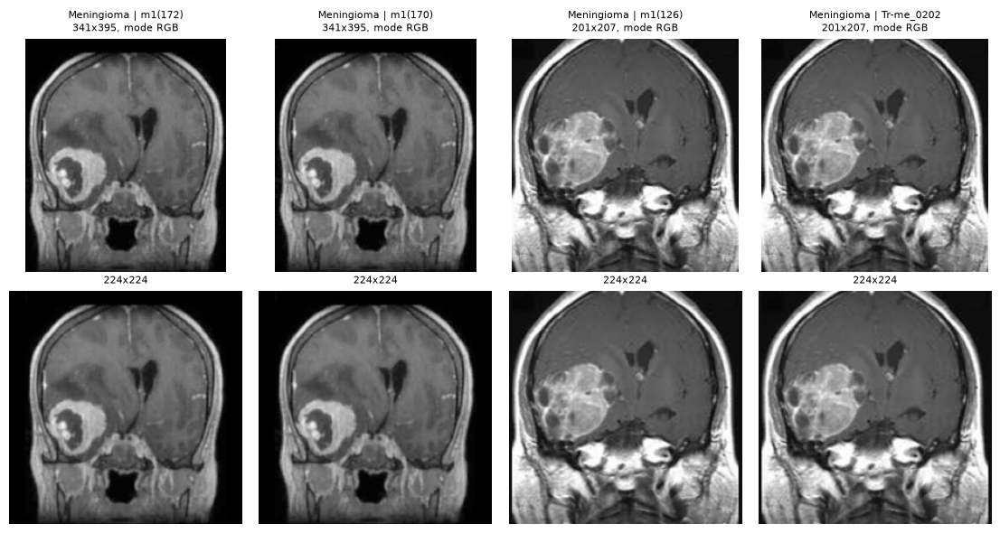

In [55]:
# CE QUE FAIT CETTE CELLULE (étape 2.3c, les bandes sont-elles visibles ?)
# Pour chacune des 697 images qui reçoivent des bandes, calcule la couleur des bandes (fill),
# le fond proche du bord à l'intérieur de l'image (fond_proche) et leur écart (marche).
# Résume par classe, liste les 8 pires cas et affiche avant / après pour les 4 pires.
from src.preprocessing import band_step

res = [band_step(load_gray(ROOT / p)) for p in banded.image_path]
banded[["fill", "fond_proche", "marche"]] = pd.DataFrame(res, index=banded.index)

for t in (8, 15):
    print(f"Marche >= {t} niveaux de gris : {int((banded.marche >= t).sum())} images sur {len(banded)}")
display(banded.groupby("class").agg(
    images=("marche", "size"),
    marche_ge_8=("marche", lambda s: int((s >= 8).sum())),
    marche_moyenne=("marche", lambda s: round(s.mean(), 1)),
))
worst = banded.sort_values("marche", ascending=False)
display(worst[["image_path", "class", "fill", "fond_proche", "marche"]].head(8))
plot_before_after(worst.head(4), SIZE, PAD, ROOT / cfg["paths"]["figures"] / "preproc_worst_bands.png")

In [56]:
# CE QUE FAIT CETTE CELLULE (étape 2.3c, les deux images aux fines lignes)
# Pour Tr-no_1011 et Tr-no_1020, affiche la médiane de chacune des 10 premières et des 10 dernières
# colonnes, la couleur des bandes et le fond proche. Si les colonnes du bord valent 0 puis montent
# à un niveau plus clair, l'image contient un cadre noir sur ses bords.
for name in ["Tr-no_1011", "Tr-no_1020"]:
    rel = manifest.loc[manifest.image_path.str.contains(name), "image_path"].iloc[0]
    g = load_gray(ROOT / rel)
    fill, near, step = band_step(g)
    print(f"{name} ({g.shape[1]}x{g.shape[0]}) : bandes {fill}, fond proche {near}, marche {step}")
    print("  10 premières colonnes :", np.median(g[:, :10], axis=0).astype(int).tolist())
    print("  10 dernières colonnes :", np.median(g[:, -10:], axis=0).astype(int).tolist())

Tr-no_1011 (550x664) : bandes 0, fond proche 13, marche 13
  10 premières colonnes : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  10 dernières colonnes : [13, 13, 14, 2, 0, 0, 0, 0, 0, 0]
Tr-no_1020 (442x454) : bandes 7, fond proche 8, marche 1
  10 premières colonnes : [255, 5, 8, 8, 9, 9, 9, 8, 8, 8]
  10 dernières colonnes : [8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


## Résultats 2.3c : les bandes sont-elles visibles à côté de l'image ?

**Chiffres (fichiers utilisables, copies comprises) :**

| Classe | Images avec bandes | Marche ≥ 8 | Part | Marche moyenne |
|---|---|---|---|---|
| Glioma | 0 | 0 | : | : |
| Meningioma | 174 | 36 | 20,7 % | 6,0 |
| No Tumor | 513 | 44 | 8,6 % | 2,5 |
| Pituitary | 10 | 7 | 70 % (10 images seulement) | 24,1 |
| **Total** | **697** | **87** | **12,5 %** | |

47 images sur 697 (6,7 %) ont une marche ≥ 15. Le passage sur les 5 234 images utilisables prend 14 s, sans erreur.

**Ce qu'on a constaté**
- Les 8 pires cas sont 4 paires de jumeaux : ce sont 4 images distinctes.
- Sur ces images, la tête remplit le cadre. La zone « fond proche » (8 % à 20 % du bord) tombe sur le crâne (gris à 62), pas sur du fond. Le vrai fond noir est dans les coins, et nos bandes (0 ou 14) ont sa couleur. Sur la figure avant/après, aucune coupure nette n'est visible. La marche mesurée est donc en grande partie une **fausse alerte** de la mesure.
- `Tr-no_1011` : l'image d'origine contient un cadre noir sur ses bords (colonnes à 0, puis fond gris à 13). `Tr-no_1020` : l'image d'origine contient une ligne blanche de 1 pixel (colonne à 255) ; nos bandes (7) correspondent au fond (8). Les fines lignes viennent des images d'origine, pas de nos bandes.
- Correction d'une hypothèse : les « bords transparents » étaient faux (0 % de transparence).

**Décision (option A) :** on garde la couleur actuelle des bandes (25ᵉ percentile d'un liseré de 3 % le long des 4 bords). Prendre le « fond proche » aurait peint des bandes grises à côté des coins noirs, donc créé des bandes visibles.

**Limites**
- La marche est une mesure imparfaite : elle ne distingue pas un vrai saut de couleur d'une tête qui touche le bord.
- 74 % des images à bandes sont des No Tumor : les bandes restent une piste de raccourci de source. On le mesurera à l'étape 2.8 (statistiques de pixels avant/après).

## 2.5 Pipeline d'entraînement : images en mémoire, augmentations, `tf.data`

**Objectif :** fournir au modèle des paquets de 32 images prétraitées. Seul le **train** reçoit des augmentations aléatoires ; la validation (et plus tard le test) reste **sans aucun hasard**.

**Décisions :**
- **D7 (A)** : chaque split est prétraité une seule fois dans un tableau en mémoire (entiers 0 à 255).
- **D8 (A)** : les augmentations sont appliquées dans `tf.data` (`src/augmentation.py`), pas dans le modèle.
- **D9** : rotation ±15°, translation ±10 %, zoom ±15 %, contraste ±20 %, luminosité ±15 %, et sur la moitié des images du train un flou léger suivi d'une baisse de résolution (de 100 % à 50 %). Réglage `degrade_prob` dans `config.yaml` (0 = désactivé) : on comparera avec et sans au Jour 4.
- Coins vides après rotation, décalage ou zoom : ils reçoivent la **couleur du fond de l'image** (estimée comme pour les bandes de la mise au carré). Le noir pur créait un cadre visible, et le prolongement du bord créait des traînées quand le tissu touche le bord.
- Le jeu de test n'est **pas chargé** ici : il ne servira qu'au Jour 5.

In [57]:
# CE QUE FAIT CETTE CELLULE (étape 2.5a, chargement des images en mémoire)
# Prétraite les images du train et de la validation (une seule fois) et les garde en mémoire.
# Affiche les tailles, la mémoire utilisée et le nombre d'images par classe. Le test n'est PAS chargé.
# Rien n'est modifié sur le disque.
import time
from src.augmentation import load_split, make_augmenter, build_dataset, plot_augmentation

t0 = time.time()
Xtr, ytr, dtr = load_split(manifest, "train", CLASSES, SIZE, PAD, DEDUP)
Xva, yva, dva = load_split(manifest, "val", CLASSES, SIZE, PAD)
print(f"Chargement en {time.time() - t0:.0f} s")
for nom, X, y in (("train", Xtr, ytr), ("val", Xva, yva)):
    print(f"{nom:5s} : {X.shape}, {X.dtype}, {X.nbytes / 1e6:.0f} Mo")
    print("       images par classe :", dict(zip(CLASSES, np.bincount(y, minlength=len(CLASSES)).tolist())))

Chargement en 5 s
train : (2542, 224, 224, 3), uint8, 383 Mo
       images par classe : {'Glioma': 822, 'Meningioma': 753, 'No Tumor': 250, 'Pituitary': 717}
val   : (545, 224, 224, 3), uint8, 82 Mo
       images par classe : {'Glioma': 176, 'Meningioma': 162, 'No Tumor': 54, 'Pituitary': 153}


In [58]:
# CE QUE FAIT CETTE CELLULE (étape 2.5b, construction et vérification des jeux tf.data)
# Construit le jeu d'entraînement (mélange + augmentations) et celui de validation (sans hasard).
# Vérifie : forme et type d'un paquet, validation identique à l'original et identique d'un passage
# à l'autre, ordre du train différent d'une époque à l'autre, classes conservées, 3 canaux identiques.
aug_cfg = cfg.get("augmentation", {})
BATCH = cfg["classifier"]["batch_size"]
augment = make_augmenter(aug_cfg, SIZE, cfg["seed"])
train_ds = build_dataset(Xtr, ytr, True, BATCH, augment, cfg["seed"])
val_ds = build_dataset(Xva, yva, False, BATCH)

xb, yb = next(iter(train_ds))
print("paquet train :", xb.shape, xb.dtype, "| valeurs", int(xb.numpy().min()), "à", int(xb.numpy().max()),
      "| étiquettes", yb.shape, yb.dtype)
print("3 canaux identiques :", bool((xb[..., 0] == xb[..., 1]).numpy().all() and (xb[..., 1] == xb[..., 2]).numpy().all()))

v1 = np.concatenate([x.numpy() for x, _ in val_ds])
v2 = np.concatenate([x.numpy() for x, _ in val_ds])
print("validation identique à l'original :", np.array_equal(v1, Xva), "| identique entre deux passages :", np.array_equal(v1, v2))

e1 = np.concatenate([y.numpy() for _, y in train_ds])
e2 = np.concatenate([y.numpy() for _, y in train_ds])
print("ordre du train différent d'une époque à l'autre :", not np.array_equal(e1, e2))
print("mêmes effectifs de classes qu'avant :", np.array_equal(np.sort(e1), np.sort(ytr)))

I0000 00:00:1793468471.882005   49058 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5564 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
W0000 00:00:1793468474.509456   49058 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_39}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
I0000 00:00:1793468474.509502   49058 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 1865652117071389716
W0000 00:00:1793468474.509511   49058 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_39}}]]
	 [[sequential_1/random_translation_1/Add_1/_36]] [type.googleapis.com/tensorflow.DerivedStatus='']
I0000 00:00:1793468474.509514   49058 local_rendezvous.cc:432] Local rendezv

paquet train : (32, 224, 224, 3) <dtype: 'uint8'> | valeurs 0 à 240 | étiquettes (32,) <dtype: 'int32'>
3 canaux identiques : True
validation identique à l'original : True | identique entre deux passages : True
ordre du train différent d'une époque à l'autre : True
mêmes effectifs de classes qu'avant : True


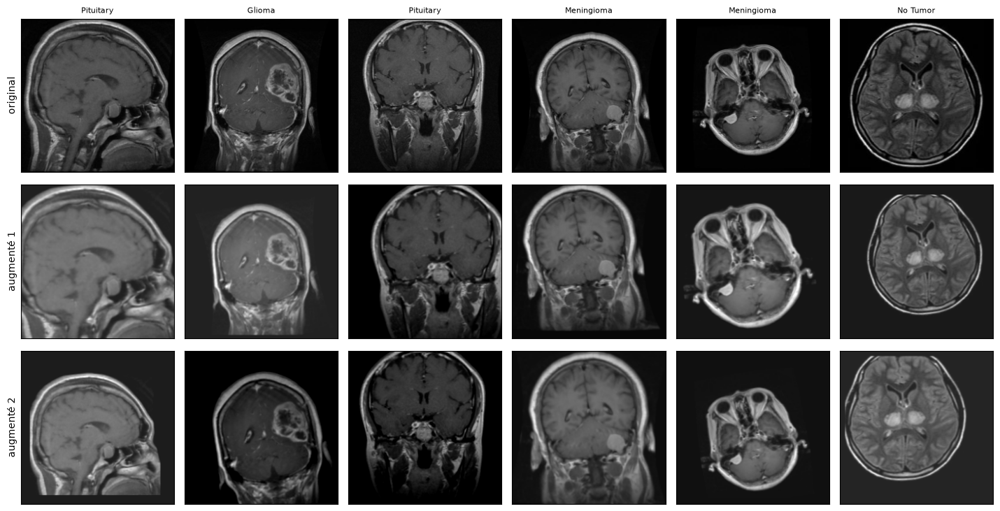

In [59]:
# CE QUE FAIT CETTE CELLULE (étape 2.5c, avant / après augmentation)
# Ligne du haut : 6 images du train prétraitées. Les deux lignes du dessous : deux versions
# augmentées au hasard de chaque image. Sert à vérifier à l'œil que les lésions restent visibles.
plot_augmentation(Xtr, ytr, CLASSES, augment, n=6, n_versions=2,
                  out_path=ROOT / cfg["paths"]["figures"] / "augmentation_train.png")

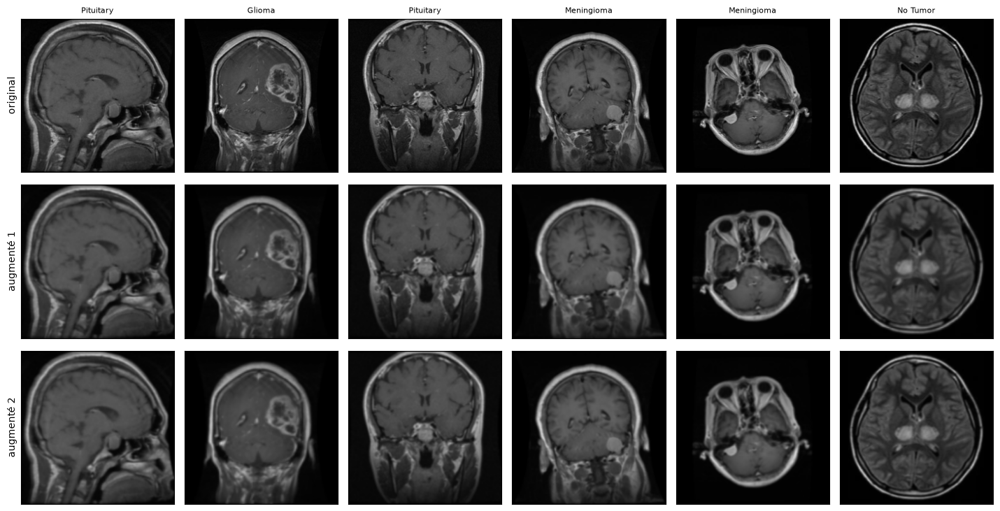

In [60]:
# CE QUE FAIT CETTE CELLULE (étape 2.5d, effet de la dégradation seule, cas extrême)
# Applique SEULEMENT le flou et la baisse de résolution, sur 100 % des images (au lieu de 50 %),
# pour voir si cette dégradation est raisonnable ou trop forte (taille minimale 112 px).
degrade_only = make_augmenter({"degrade_prob": 1.0, "rotation_deg": 0, "translation": 0, "zoom": 0,
                               "contrast": 0, "brightness": 0}, SIZE, cfg["seed"])
plot_augmentation(Xtr, ytr, CLASSES, degrade_only, n=6, n_versions=2,
                  out_path=ROOT / cfg["paths"]["figures"] / "augmentation_degradation.png")

## Résultats 2.5 : pipeline d'entraînement

**Chargement (cellule 109)** : 2 542 images de train (383 Mo) et 545 de validation (82 Mo), prétraitées en 6 s, `uint8`. Effectifs identiques au découpage du Jour 1 :

| Classe | Train | Val |
|---|---|---|
| Glioma | 822 | 176 |
| Meningioma | 753 | 162 |
| No Tumor | 250 | 54 |
| Pituitary | 717 | 153 |

Le jeu de test n'est pas chargé : il ne servira qu'au Jour 5.

**Vérifications (cellule 110)** : un paquet de train a la forme (32, 224, 224, 3), `uint8`, valeurs de 0 à 255 ; les 3 canaux sont identiques ; la validation est identique à l'original et d'un passage à l'autre ; l'ordre du train change à chaque époque ; les effectifs de classes sont conservés.

**Augmentations (cellules 111 et 112)** : rotation ±15°, translation ±10 %, zoom ±15 %, contraste ±20 %, luminosité ±15 %, et pour la moitié des images du train un flou léger suivi d'une baisse de résolution (de 100 % à 50 %). Les lésions restent visibles. La dégradation seule (testée à 100 % des images) efface le grain fin mais garde les contours.

**Ce qu'on a corrigé pendant l'étape**
- Remplissage des coins vides par du noir pur : cadre visible autour des images (constaté sur des images inventées).
- Remplissage en prolongeant le bord : traînées étirées quand le tissu touche le bord (constaté sur de vraies images, cellule 111).
- **Décision D10 (retenue)** : les coins vides reçoivent la couleur du fond de chaque image (même estimation que pour les bandes). Les traînées ont disparu.

**Limites et points à suivre**
- La luminosité ±15 % fait parfois monter le fond de ~0 à ~35 : à revoir au Jour 4 (valeur 0,10) si besoin.
- Les tumeurs Pituitary mesurent environ 22 px à 224 ; la baisse de résolution à 112 px les réduit à environ 11 px. On comparera avec et sans dégradation (`degrade_prob`) au Jour 4.
- Les augmentations sont reproductibles avec la même graine (42).

## 2.6 Adapter les boîtes aux transformations géométriques

**Objectif :** quand on tourne, décale ou zoome une image, les boîtes doivent suivre la lésion. On tire une transformation (angle, décalage, zoom) et on applique **les mêmes valeurs** à l'image et à ses boîtes.

**Décisions :**
- Les 4 coins de chaque boîte sont transformés ; la boîte devient le plus petit rectangle droit qui les contient (elle est donc un peu plus grande que la lésion après une rotation).
- **D11 (A)** : la boîte est recadrée au cadre de l'image ; elle est **écartée si moins de 50 % de sa surface reste visible** (réglage `box_min_visible`).
- Les coins vides de l'image prennent la couleur du fond.
- Les fonctions sont dans `src/augmentation.py`, les tests dans `tests/test_annotations.py`.

2291 images de train utilisables en détection


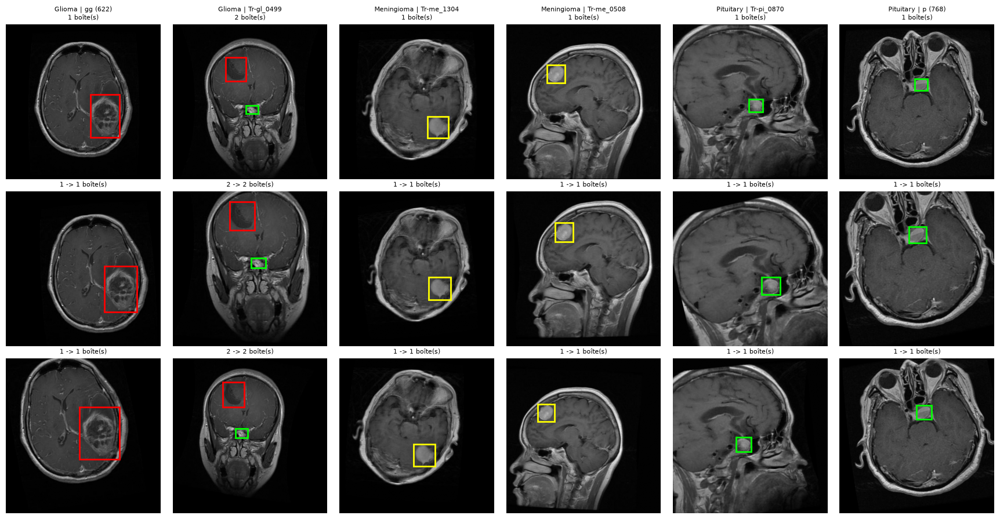

In [61]:
# CE QUE FAIT CETTE CELLULE (étape 2.6a, test visuel : les boîtes suivent-elles la lésion ?)
# Prend 2 images de train par type de boîte (Glioma, Meningioma, Pituitary), les transforme deux fois
# au hasard et dessine l'image d'origine (ligne du haut) puis les deux versions transformées avec leurs
# boîtes déplacées. Le titre donne le nombre de boîtes avant -> après. Rien n'est modifié sur le disque.
from src.augmentation import plot_box_augmentation, box_transform_stats
from src.preprocessing import select_images

det = select_images(manifest, "train", "detection")
sample = det.groupby("class").sample(2, random_state=cfg["seed"])
print(f"{len(det)} images de train utilisables en détection")
plot_box_augmentation(sample, n_versions=2, aug_cfg=cfg.get("augmentation", {}), seed=cfg["seed"],
                      out_path=ROOT / cfg["paths"]["figures"] / "boxes_augmentation.png")

In [62]:
# CE QUE FAIT CETTE CELLULE (étape 2.6b, combien de boîtes sont perdues ou agrandies ?)
# Pour chaque image de train utilisable en détection, tire 20 transformations au hasard et regarde, pour
# chaque type de boîte, la part de boîtes écartées (moins de 50 % visible) et de combien la surface
# grandit (1 = même taille que l'image zoomée). Aucune image n'est ouverte, rien n'est modifié sur le disque.
stats = box_transform_stats(det, n_draws=20, aug_cfg=cfg.get("augmentation", {}), seed=cfg["seed"])
display(stats)

,boites_testees,ecartees_pct,rapport_surface_median,rapport_surface_p95
type,,,,
Glioma,19180,0.0,1.26,1.49
Meningioma,15600,0.0,1.26,1.49
Pituitary,18720,0.0,1.27,1.50


In [63]:
# CE QUE FAIT CETTE CELLULE (étape 2.6c, tests automatiques des boîtes)
# Lance les 47 tests de tests/test_annotations.py (transformation neutre, translation exacte, lésion
# toujours dans la boîte, boîte sortie du cadre, couleur du fond, reproductibilité).
!python -m pytest tests/test_annotations.py -q

...............................................                          [100%]
47 passed in 3.63s


## Résultats 2.6 : boîtes et transformations géométriques

**Test visuel (cellule 115)** : sur 6 images de train (2 Glioma, 2 Meningioma, 2 Pituitary), les boîtes suivent la lésion après rotation, décalage et zoom. Les images à 2 boîtes (tumorale et zone de l'hypophyse) gardent leurs deux boîtes. 2 291 images de train sont utilisables en détection.

**Statistiques (cellule 116)** : 53 500 boîtes testées (2 675 boîtes × 20 tirages).

| Type de boîte | Boîtes testées | Écartées | Surface médiane | Surface p95 |
|---|---|---|---|---|
| Glioma | 19 180 | 0,0 % | ×1,26 | ×1,49 |
| Meningioma | 15 600 | 0,0 % | ×1,26 | ×1,49 |
| Pituitary | 18 720 | 0,0 % | ×1,27 | ×1,50 |

**Tests (cellule 117)** : 47 tests passés (transformation neutre, translation exacte, lésion toujours dans la boîte, boîte sortie du cadre écartée, couleur du fond, reproductibilité).

**Décision D11 (A)** : boîte recadrée, écartée si moins de 50 % reste visible. Avec les réglages de base, aucune boîte n'est écartée.

**Limites**
- Une boîte droite autour d'une lésion tournée est plus grande que la lésion : +26 % de surface en médiane, +50 % au maximum (rotation de 15°). C'est inévitable avec des boîtes droites.
- Ces fonctions servent à l'énoncé et aux tests. L'entraînement YOLO utilisera ses propres augmentations (décision D5), qui adaptent aussi les boîtes.
- La qualité des boîtes dépend des annotations d'origine (environ 8 % des groupes de jumeaux ont des boîtes différentes selon la version).

## 2.7 Dossier YOLO

**Objectif :** préparer `data/yolo/` avec les images et les étiquettes dans le format attendu par YOLO, à partir du manifeste (jamais des dossiers d'origine).

**Décisions :**
- **D6** : détection = images avec `use_for_detection`, un représentant par groupe (train, val et test). No Tumor est exclu.
- **D12 (A)** : les images sont **copiées** (80 Mo environ) : dossier autonome, sans lien fragile dans Docker. `data/yolo` est entièrement généré ; `data/raw` n'est jamais touché.
- **D13 (A)** : noms de fichiers d'origine gardés (espaces et parenthèses compris). Si Ultralytics les refuse au Jour 5, on passera à des noms nettoyés (le dossier est régénérable).
- Étiquettes réécrites avec 3 classes : Glioma 0, Meningioma 1, **Pituitary 2** (ancien 3).
- `data.yaml` sans chemin absolu ; `index.csv` garde la correspondance avec les images d'origine.
- Le test est préparé mais **n'est pas utilisé** avant le Jour 5.

In [64]:
# CE QUE FAIT CETTE CELLULE (étape 2.7a, création du dossier YOLO)
# Efface puis refait data/yolo à partir du manifeste : copie les images de train, val et test utilisables en
# détection, réécrit les étiquettes avec 3 classes (Glioma 0, Meningioma 1, Pituitary 2), écrit data.yaml
# et index.csv. Affiche les effectifs. data/raw n'est pas modifié.
import pandas as pd
from src.yolo import build_yolo_dataset, check_yolo_dataset, plot_yolo_samples
from src.preprocessing import select_images

yolo_dir = cfg["paths"]["yolo"]
idx, rep = build_yolo_dataset(manifest, yolo_dir)
print("images par split :", rep["images"])
print("\nboîtes par split et par type :")
display(pd.DataFrame(rep["boites"]).T)
print("boîtes écartées (identifiant d'origine -> nombre) :", rep["boites_ecartees_par_identifiant_origine"] or "aucune")
print("images écartées :", rep["images_ecartees"] or "aucune")

images par split : {'train': 2291, 'val': 491, 'test': 491}

boîtes par split et par type :


,Glioma,Meningioma,Pituitary
train,959,780,936
val,205,166,205
test,206,162,205


boîtes écartées (identifiant d'origine -> nombre) : aucune
images écartées : aucune


In [65]:
# CE QUE FAIT CETTE CELLULE (étape 2.7b, vérification du dossier YOLO)
# Contrôle le dossier : une étiquette par image, identifiants 0 à 2, coordonnées valides, étiquettes
# identiques aux étiquettes d'origine une fois les identifiants convertis. Compare les effectifs au manifeste,
# affiche data.yaml et le poids du dossier. Rien n'est modifié.
problems = check_yolo_dataset(idx, yolo_dir)
print("problèmes :", problems if problems else "aucun")
attendu = {s: len(select_images(manifest, s, "detection")) for s in ("train", "val", "test")}
print("attendu (manifeste) :", attendu, "| dans le dossier :", rep["images"])
print("poids du dossier : %.0f Mo" % (sum(p.stat().st_size for p in (ROOT / yolo_dir).rglob("*") if p.is_file()) / 1e6))
print("\n--- data.yaml ---")
print((ROOT / yolo_dir / "data.yaml").read_text())

problèmes : aucun
attendu (manifeste) : {'train': 2291, 'val': 491, 'test': 491} | dans le dossier : {'train': 2291, 'val': 491, 'test': 491}
poids du dossier : 84 Mo

--- data.yaml ---
train: images/train
val: images/val
test: images/test
nc: 3
names:
  0: Glioma
  1: Meningioma
  2: Pituitary



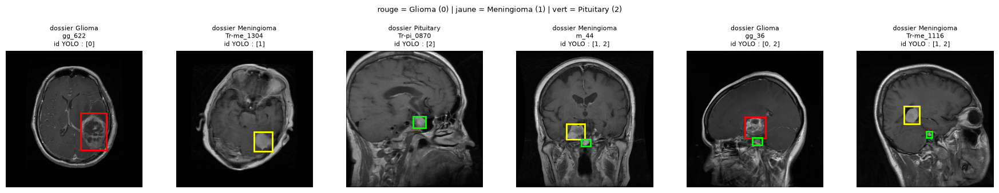

In [66]:
# CE QUE FAIT CETTE CELLULE (étape 2.7c, contrôle visuel des identifiants)
# Dessine 6 images du dossier YOLO avec leurs boîtes lues dans les nouvelles étiquettes (rouge = Glioma,
# jaune = Meningioma, vert = Pituitary) : les couleurs doivent être les mêmes que dans la figure 2.6.
plot_yolo_samples(idx, seed=cfg["seed"], out_path=ROOT / cfg["paths"]["figures"] / "yolo_samples.png")

## Résultats 2.7 : dossier YOLO

**Création (cellule 120)** : `data/yolo/{images,labels}/{train,val,test}` généré depuis le manifeste. Images copiées avec leur nom d'origine (D12 A, D13 A). Aucune boîte ni image écartée.

| Split | Images | Glioma (0) | Meningioma (1) | Pituitary (2) |
|---|---|---|---|---|
| train | 2 291 | 959 | 780 | 936 |
| val | 491 | 205 | 166 | 205 |
| test | 491 | 206 | 162 | 205 |

Les boîtes du train correspondent exactement aux nombres prévus à l'étape 2.6. Les boîtes de type Pituitary sont plus nombreuses que les images du dossier Pituitary : une partie est dans des dossiers Glioma ou Meningioma (voir Jour 1).

**Vérifications (cellule 121)** : aucun problème ; effectifs égaux à ceux du manifeste ; poids 84 Mo ; `data.yaml` : 3 classes (Glioma, Meningioma, Pituitary), chemins relatifs (compatibles Docker).

**Contrôle visuel (cellule 122)** : les boîtes Pituitary (ancien identifiant 3, nouvel identifiant 2) apparaissent en vert, y compris dans les images des dossiers Glioma et Meningioma.

**Limite** : le chargement par Ultralytics (noms avec espaces et parenthèses) n'est pas encore testé ; il le sera au premier entraînement (Jour 5). Si besoin, on passera à des noms nettoyés (dossier régénérable).

## 2.8 Tests automatiques et thermomètre sur les pixels

**Objectif :** (1) vérifier par des tests automatiques que le prétraitement, la lecture des étiquettes et le manifeste respectent les règles du projet ; (2) mesurer si l'on peut deviner la classe à partir de chiffres globaux des pixels (luminosité, contraste, netteté, part de noir, part de clair, niveau du fond), avant puis après prétraitement.

**Décisions :**
- **D14 (A)** : tests du prétraitement, des étiquettes et du manifeste réel (en plus des tests des boîtes de l'étape 2.6).
- **D15 (A)** : arbre de décision de profondeur 4, 5 validations croisées, sur les 3 632 images distinctes (une par groupe), comme au Jour 1.
- Un score supérieur à la classe majoritaire est un **indice**, pas une preuve : une vraie différence d'anatomie peut aussi faire varier ces chiffres.

In [67]:
# CE QUE FAIT CETTE CELLULE (étape 2.8a, tests automatiques)
# Lance tous les tests du dossier tests/ : boîtes (2.6), prétraitement, lecture des étiquettes et manifeste.
# Rien n'est modifié sur le disque.
!python -m pytest tests -q

....................................................................     [100%]
68 passed in 3.94s


In [68]:
# CE QUE FAIT CETTE CELLULE (étape 2.8b, chiffres globaux des pixels avant / après prétraitement)
# Pour chacune des 3 632 images distinctes, calcule 6 chiffres sur l'image d'origine (avant_) et sur l'image
# prétraitée 224x224 (apres_), puis les enregistre dans reports/metrics/pixel_stats.csv. Affiche leur
# moyenne par classe. Aucune image n'est modifiée.
import time
from src.shortcut import compute_pixel_table, thermometer_table, tree_importances

reps = manifest[manifest["is_representative"] & manifest["use_for_classification"]].reset_index(drop=True)
t0 = time.time()
pixels = compute_pixel_table(reps, SIZE, PAD)
print(f"{len(pixels)} images en {time.time() - t0:.0f} s")
out = ROOT / cfg["paths"]["metrics"] / "pixel_stats.csv"
out.parent.mkdir(parents=True, exist_ok=True)
pixels.to_csv(out, index=False)
print("images par classe :", reps["class"].value_counts().to_dict())
display(pixels.drop(columns="image_path").groupby(reps["class"].values).mean().round(2).T)

3632 images en 15 s
images par classe : {'Glioma': 1174, 'Meningioma': 1077, 'Pituitary': 1023, 'No Tumor': 358}


,Glioma,Meningioma,No Tumor,Pituitary
avant_mean,35.15,44.15,61.45,49.29
avant_std,39.72,47.03,56.27,41.38
avant_sharpness,53.32,103.24,977.39,89.98
avant_dark_share,0.52,0.49,0.34,0.35
avant_bright_share,0.00,0.01,0.04,0.00
avant_bg_level,0.25,1.19,6.80,1.63
apres_mean,35.17,43.35,56.37,49.28
apres_std,39.10,46.45,54.86,40.53
apres_sharpness,280.26,296.31,731.67,409.43
apres_dark_share,0.52,0.49,0.38,0.34


In [69]:
# CE QUE FAIT CETTE CELLULE (étape 2.8c, le thermomètre)
# Un petit arbre essaie de deviner la classe : (1) en répondant toujours la classe majoritaire, (2) avec les
# métadonnées du fichier, (3) avec les chiffres des pixels d'origine, (4) avec ceux des pixels prétraités.
# Affiche accuracy, F1 macro et rappel par classe, puis les chiffres les plus utilisés par l'arbre.
table = thermometer_table(reps, pixels, cfg["seed"])
display(table)
table.to_csv(ROOT / cfg["paths"]["metrics"] / "thermometer_pixels.csv")
for prefix, nom in (("avant", "images d'origine"), ("apres", "après prétraitement")):
    print(f"\nChiffres les plus utilisés par l'arbre ({nom}) :")
    print(tree_importances(pixels, reps["class"], prefix, cfg["seed"]).head(3))

,accuracy,macro_f1,rappel Glioma,rappel Meningioma,rappel No Tumor,rappel Pituitary
Toujours la classe majoritaire,0.323,0.122,1.000,0.000,0.000,0.000
"Métadonnées du fichier (taille, poids, mode)",0.585,0.592,0.642,0.178,0.902,0.838
Pixels : images d'origine,0.649,0.658,0.554,0.504,0.751,0.875
Pixels : après prétraitement,0.650,0.650,0.500,0.643,0.603,0.848



Chiffres les plus utilisés par l'arbre (images d'origine) :
netteté                0.366
part de noir (≤ 15)    0.302
contraste              0.193
dtype: float64

Chiffres les plus utilisés par l'arbre (après prétraitement) :
part de noir (≤ 15)      0.325
part de clair (≥ 200)    0.212
contraste                0.176
dtype: float64


## Résultats 2.8 : tests et thermomètre sur les pixels

**Tests (cellule 125)** : 64 tests passés (boîtes, prétraitement, étiquettes, manifeste réel).

**Thermomètre (cellule 127)** : arbre de profondeur 4, 5 validations croisées, 3 632 images distinctes.

| Modèle | Accuracy | F1 macro | Rappel Glioma | Meningioma | No Tumor | Pituitary |
|---|---|---|---|---|---|---|
| Toujours la classe majoritaire | 0,323 | 0,122 | 1,00 | 0 | 0 | 0 |
| Métadonnées du fichier | 0,585 | 0,592 | 0,64 | 0,18 | 0,90 | 0,84 |
| Pixels : images d'origine | 0,649 | 0,658 | 0,55 | 0,50 | 0,75 | 0,88 |
| Pixels : après prétraitement | 0,650 | 0,650 | 0,50 | 0,64 | 0,60 | 0,85 |

**Constats**
- Six chiffres globaux suffisent à doubler le score de la classe majoritaire : la classe se devine en partie sans regarder la tumeur.
- Le prétraitement ne fait pas baisser ce score (0,658 → 0,650, dans le bruit) mais retire l'indice « netteté » (premier chiffre utilisé avant : 0,37). Après, la part de noir (0,33) et la part de clair (0,21) dominent.
- No Tumor reste la classe la plus différente (netteté 732 contre 280 à 409 ; niveau du fond 6,8 contre 0,3 à 1,6).

**Limites**
- Un score au-dessus de la classe majoritaire est un **indice**, pas une preuve : une vraie différence d'anatomie ou de cadrage peut produire ces écarts.
- La part de noir mêle fond réel, bandes ajoutées et cadrage : non séparés ici.
- **Seuil de plausibilité** : un modèle d'images dont le F1 macro n'est pas nettement supérieur à 0,65 n'apprend pas plus que ces chiffres globaux.
- L'effet de la dégradation (flou, baisse de résolution) et de la luminosité n'est pas mesuré ici : à comparer au Jour 4 (avec et sans).

## Jour 3 : classification de base

**Modèle :** MobileNetV2 préentraîné **gelé** + moyenne globale + Dropout 0,3 + Dense 4. Le prétraitement est dans le modèle (entrée : images 0-255).
**Décisions :** D16 (A) poids de classes `balanced` ; D17 EarlyStopping sur la **perte de validation** (patience 5, meilleur modèle restauré) ; dégradation désactivée (`degrade_prob: 0`). Évaluation sur la **validation seulement** (test réservé au Jour 5). Repère : le thermomètre sur les pixels donne F1 macro ≈ 0,65.

In [70]:
# CE QUE FAIT CETTE CELLULE (étape 3.1, config et jeux de données)
# Relit config.yaml (dégradation désactivée), reconstruit les jeux train et validation, affiche les poids de classes.
# (Si le noyau a été redémarré : relancer d'abord les cellules 89 et 109.)
import keras
from src.utils import load_config
from src.classifier import build_classifier, class_weights, train_classifier, evaluate_classifier

cfg = load_config()
keras.utils.set_random_seed(cfg["seed"])
augment = make_augmenter(cfg["augmentation"], SIZE, cfg["seed"])
BATCH = cfg["classifier"]["batch_size"]
train_ds = build_dataset(Xtr, ytr, True, BATCH, augment, cfg["seed"])
val_ds = build_dataset(Xva, yva, False, BATCH)
print("degrade_prob :", cfg["augmentation"]["degrade_prob"])
print("poids de classes :", {c: round(w, 2) for c, w in zip(CLASSES, class_weights(ytr, len(CLASSES)).values())})

degrade_prob : 0
poids de classes : {'Glioma': 0.77, 'Meningioma': 0.84, 'No Tumor': 2.54, 'Pituitary': 0.89}


In [71]:
# CE QUE FAIT CETTE CELLULE (GPU) : À PLACER TOUT EN HAUT, AVANT TOUT IMPORT DE TENSORFLOW
# Charge les bibliothèques CUDA 12 du .venv pour que TensorFlow trouve le GPU (les bibliothèques CUDA 13,
# utilisées par PyTorch, sont ignorées). Affiche les GPU vus par TensorFlow. Rien n'est modifié sur le disque.
import ctypes, glob, site

base = site.getsitepackages()[0] + "/nvidia"
noms = ["libnvJitLink.so.12", "libcudart.so.12", "libcublasLt.so.12", "libcublas.so.12", "libcufft.so.11",
        "libcurand.so.10", "libcusparse.so.12", "libcusolver.so.11", "libnvrtc.so.12", "libcupti.so.12",
        "libcudnn.so.9"]
for nom in noms:
    trouves = [p for p in glob.glob(f"{base}/*/lib/{nom}") if "/cu13/" not in p]
    try:
        ctypes.CDLL(trouves[0], mode=ctypes.RTLD_GLOBAL)
    except Exception as e:
        print("échec :", nom, "->", str(e)[:80])

import tensorflow as tf
print("GPU vus par TensorFlow :", tf.config.list_physical_devices("GPU"))

GPU vus par TensorFlow : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [72]:
# CE QUE FAIT CETTE CELLULE (étape 3.2, construction du modèle)
# Construit le modèle (poids ImageNet, corps gelé) et vérifie le nombre de paramètres et la sortie.
model = build_classifier(len(CLASSES), SIZE, cfg["classifier"]["dropout"], cfg["classifier"]["l2"])
n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"paramètres entraînables : {n_train:,} sur {model.count_params():,}")
xb, _ = next(iter(val_ds))
p = model.predict(xb, verbose=0)
print("sortie :", p.shape, "| somme par image :", p.sum(axis=1)[:3].round(3))

paramètres entraînables : 5,124 sur 2,263,108


I0000 00:00:1793468526.481541   49235 service.cc:153] XLA service 0x24e87b90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793468526.481579   49235 service.cc:161]   StreamExecutor [0]: NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1793468526.504382   49235 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793468527.115291   49235 cuda_dnn.cc:461] Loaded cuDNN version 92400
E0000 00:00:1793468533.331426   49235 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


sortie : (32, 4) | somme par image : [1. 1. 1.]


I0000 00:00:1793468536.948546   49235 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


In [73]:
# CE QUE FAIT CETTE CELLULE (vérification du GPU)
# Montre si TensorFlow (classifieur) et PyTorch (YOLO, Jour 5) voient la carte graphique, puis prouve
# que les calculs partent bien dessus : une grosse multiplication de matrices est chronométrée sur GPU
# puis sur CPU, et on affiche où se trouvent les poids du modèle. Rien n'est modifié.
import time, tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| compilé avec CUDA :", tf.test.is_built_with_cuda())
print("GPU vus par TensorFlow :", gpus)

try:
    import torch
    print("PyTorch", torch.__version__, "| GPU disponible :", torch.cuda.is_available(),
          "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "aucun")
except Exception as e:
    print("PyTorch : non testé (", e, ")")

def chrono(device):
    with tf.device(device):
        a = tf.random.normal((4096, 4096))
        tf.matmul(a, a).numpy()                      # chauffe
        t0 = time.time()
        for _ in range(10):
            tf.matmul(a, a).numpy()
        return time.time() - t0

if gpus:
    g, c = chrono("/GPU:0"), chrono("/CPU:0")
    print(f"10 multiplications 4096x4096 : GPU {g:.2f} s | CPU {c:.2f} s | GPU {c / g:.0f} fois plus rapide")
    print("poids du modèle sur :", model.trainable_weights[0].value.device)
else:
    print("Aucun GPU : l'entraînement se ferait sur le CPU (voir les causes ci-dessous).")

TensorFlow 2.21.0 | compilé avec CUDA : True
GPU vus par TensorFlow : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch 2.14.1+cu130 | GPU disponible : True | NVIDIA RTX 2000 Ada Generation Laptop GPU
10 multiplications 4096x4096 : GPU 0.41 s | CPU 3.15 s | GPU 8 fois plus rapide
poids du modèle sur : /job:localhost/replica:0/task:0/device:GPU:0


In [74]:
# CE QUE FAIT CETTE CELLULE (étape 3.3, entraînement de la tête)
# Entraîne au plus 30 époques (arrêt si la perte de validation ne baisse plus pendant 5 époques) et enregistre
# le meilleur modèle dans models/classifier_base.keras.
history, secs, ckpt = train_classifier(model, train_ds, val_ds, cfg, ytr)
print(f"{len(history['loss'])} époques en {secs / 60:.1f} min | meilleur modèle : {ckpt.name}")

Epoch 1/30


I0000 00:00:1793468548.202223   49234 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21910__.120
I0000 00:00:1793468557.497669   49237 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21910__.120
E0000 00:00:1793468560.412286   49237 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793468570.314468   49235 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


80/80 - 32s - 396ms/step - accuracy: 0.5976 - loss: 0.9470 - val_accuracy: 0.6752 - val_loss: 0.8184 - learning_rate: 0.0010
Epoch 2/30
80/80 - 8s - 96ms/step - accuracy: 0.7506 - loss: 0.6095 - val_accuracy: 0.7578 - val_loss: 0.6120 - learning_rate: 0.0010
Epoch 3/30
80/80 - 7s - 91ms/step - accuracy: 0.7927 - loss: 0.5055 - val_accuracy: 0.7358 - val_loss: 0.6637 - learning_rate: 0.0010
Epoch 4/30
80/80 - 7s - 90ms/step - accuracy: 0.8194 - loss: 0.4365 - val_accuracy: 0.7560 - val_loss: 0.6121 - learning_rate: 0.0010
Epoch 5/30
80/80 - 8s - 99ms/step - accuracy: 0.8336 - loss: 0.4158 - val_accuracy: 0.7651 - val_loss: 0.5567 - learning_rate: 5.0000e-04
Epoch 6/30
80/80 - 8s - 101ms/step - accuracy: 0.8395 - loss: 0.3914 - val_accuracy: 0.7798 - val_loss: 0.5364 - learning_rate: 5.0000e-04
Epoch 7/30
80/80 - 8s - 95ms/step - accuracy: 0.8324 - loss: 0.3982 - val_accuracy: 0.7578 - val_loss: 0.6180 - learning_rate: 5.0000e-04
Epoch 8/30
80/80 - 8s - 96ms/step - accuracy: 0.8430 - los

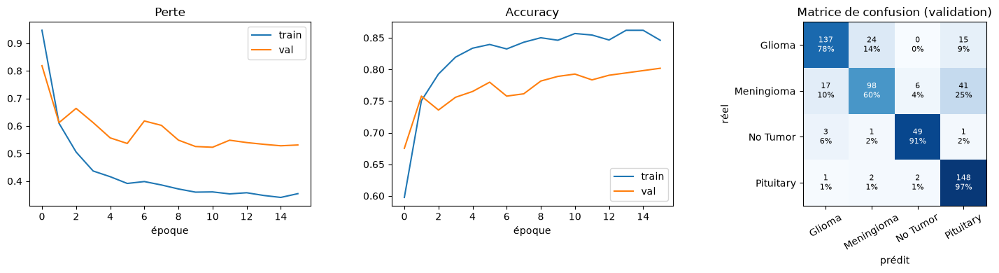

F1 macro : 0.803 | accuracy : 0.793 | meilleure époque : 11
rappel : {'Glioma': 0.78, 'Meningioma': 0.6, 'No Tumor': 0.91, 'Pituitary': 0.97}
au-dessus du seuil 0,65 : True


In [75]:
# CE QUE FAIT CETTE CELLULE (étape 3.4, évaluation sur la validation)
# Calcule F1 macro, accuracy, rappel par classe, matrice de confusion et courbes ; enregistre le JSON et la figure.
res = evaluate_classifier(model, val_ds, yva, CLASSES, cfg, history)
print(f"F1 macro : {res['val_f1_macro']:.3f} | accuracy : {res['val_accuracy']:.3f} | meilleure époque : {res['best_epoch']}")
print("rappel :", {k: round(v, 2) for k, v in res["recall"].items()})
print("au-dessus du seuil 0,65 :", res["above_threshold"])

## Résultats Jour 3 : classifieur de base (MobileNetV2 gelé)

**GPU** : RTX 2000 Ada (TensorFlow, CUDA 12 chargées par la cellule du haut) ; 15 époques en 2,5 min.

**Arrêt** : EarlyStopping sur la perte de validation (patience 5) ; meilleure époque = 10 (`val_loss` 0,4946), poids de l'époque 10 restaurés.

| Mesure (validation, 545 images) | Valeur |
|---|---|
| F1 macro | **0,809** (seuil de plausibilité : 0,65) |
| Accuracy | 0,802 |
| Rappel Glioma / Meningioma / No Tumor / Pituitary | 0,82 / **0,59** / 0,91 / 0,97 |

**Confusions** : Meningioma → Pituitary 23 %, → Glioma 14 %.

**Limites** : une seule graine ; validation de 545 images (courbes bruitées) ; les bons rappels de No Tumor et Pituitary ressemblent à ceux du thermomètre des métadonnées (0,90 et 0,84) : une partie peut venir de la source de l'image. Test non utilisé.

Fichiers : `models/classifier_base.keras`, `reports/metrics/classifier_base.json`, `reports/figures/classifier_base.png`.

## Jour 4 : fine-tuning, comparaison de configurations, Grad-CAM

**Décisions :** D18 dégel des 30 dernières couches (BatchNorm gelées), taux 1e-5 ; D19 trois configurations : A (base gelée), B (fine-tuning), C (fine-tuning + Dropout 0,5 et L2 1e-3) ; D20 un essai par configuration, puis 3 graines pour les deux meilleures ; D21 reportés : ResNet50, `train_dedup`, retournement, 15 images en conflit. Tout sur la **validation** ; test réservé au Jour 5.

Epoch 1/30


I0000 00:00:1793468715.456664   49233 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50173__.120
I0000 00:00:1793468727.310956   49235 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50173__.120


80/80 - 27s - 336ms/step - accuracy: 0.5924 - loss: 0.9380 - val_accuracy: 0.6862 - val_loss: 0.7883 - learning_rate: 0.0010
Epoch 2/30
80/80 - 8s - 102ms/step - accuracy: 0.7699 - loss: 0.5851 - val_accuracy: 0.7615 - val_loss: 0.5982 - learning_rate: 0.0010
Epoch 3/30
80/80 - 7s - 92ms/step - accuracy: 0.8029 - loss: 0.4829 - val_accuracy: 0.7119 - val_loss: 0.7705 - learning_rate: 0.0010
Epoch 4/30
80/80 - 8s - 101ms/step - accuracy: 0.8218 - loss: 0.4433 - val_accuracy: 0.7560 - val_loss: 0.5958 - learning_rate: 0.0010
Epoch 5/30
80/80 - 28s - 348ms/step - accuracy: 0.8151 - loss: 0.4361 - val_accuracy: 0.7780 - val_loss: 0.5698 - learning_rate: 0.0010
Epoch 6/30
80/80 - 31s - 383ms/step - accuracy: 0.8438 - loss: 0.3819 - val_accuracy: 0.7817 - val_loss: 0.5405 - learning_rate: 0.0010
Epoch 7/30
80/80 - 26s - 329ms/step - accuracy: 0.8415 - loss: 0.3809 - val_accuracy: 0.7376 - val_loss: 0.6834 - learning_rate: 0.0010
Epoch 8/30
80/80 - 28s - 349ms/step - accuracy: 0.8466 - loss: 

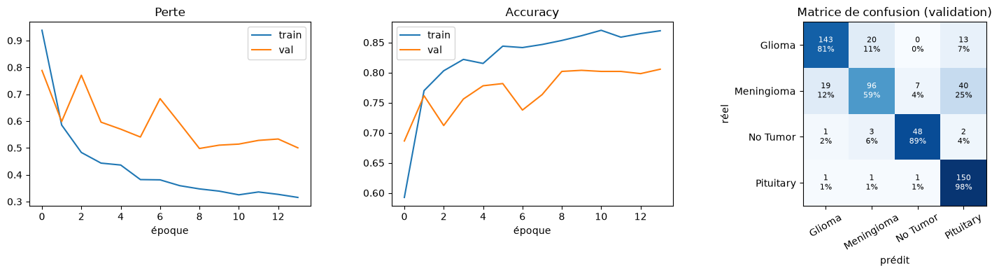

Epoch 1/30


I0000 00:00:1793468970.229585   49233 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_77577__.120
I0000 00:00:1793468978.326602   49234 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_77577__.120


80/80 - 21s - 263ms/step - accuracy: 0.6039 - loss: 0.9319 - val_accuracy: 0.6771 - val_loss: 0.8117 - learning_rate: 0.0010
Epoch 2/30
80/80 - 8s - 101ms/step - accuracy: 0.7640 - loss: 0.5910 - val_accuracy: 0.7505 - val_loss: 0.5989 - learning_rate: 0.0010
Epoch 3/30
80/80 - 7s - 92ms/step - accuracy: 0.7927 - loss: 0.5044 - val_accuracy: 0.7211 - val_loss: 0.7296 - learning_rate: 0.0010
Epoch 4/30
80/80 - 8s - 99ms/step - accuracy: 0.8245 - loss: 0.4330 - val_accuracy: 0.7633 - val_loss: 0.5842 - learning_rate: 0.0010
Epoch 5/30
80/80 - 10s - 124ms/step - accuracy: 0.8218 - loss: 0.4343 - val_accuracy: 0.7780 - val_loss: 0.5502 - learning_rate: 0.0010
Epoch 6/30
80/80 - 8s - 104ms/step - accuracy: 0.8423 - loss: 0.3842 - val_accuracy: 0.7743 - val_loss: 0.5688 - learning_rate: 0.0010
Epoch 7/30
80/80 - 9s - 112ms/step - accuracy: 0.8474 - loss: 0.3858 - val_accuracy: 0.7761 - val_loss: 0.5816 - learning_rate: 0.0010
Epoch 8/30
80/80 - 9s - 110ms/step - accuracy: 0.8521 - loss: 0.35

I0000 00:00:1793469103.475309   49235 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_99136__.120
I0000 00:00:1793469115.176349   49234 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_99136__.120


80/80 - 28s - 353ms/step - accuracy: 0.8501 - loss: 0.3712 - val_accuracy: 0.8220 - val_loss: 0.4543 - learning_rate: 1.0000e-05
Epoch 2/30
80/80 - 8s - 97ms/step - accuracy: 0.8607 - loss: 0.3223 - val_accuracy: 0.7927 - val_loss: 0.5180 - learning_rate: 1.0000e-05
Epoch 3/30
80/80 - 9s - 109ms/step - accuracy: 0.8855 - loss: 0.2744 - val_accuracy: 0.8349 - val_loss: 0.4305 - learning_rate: 1.0000e-05
Epoch 4/30
80/80 - 8s - 106ms/step - accuracy: 0.8871 - loss: 0.2589 - val_accuracy: 0.8294 - val_loss: 0.4396 - learning_rate: 1.0000e-05
Epoch 5/30
80/80 - 9s - 107ms/step - accuracy: 0.8922 - loss: 0.2456 - val_accuracy: 0.8440 - val_loss: 0.4422 - learning_rate: 1.0000e-05
Epoch 6/30
80/80 - 9s - 115ms/step - accuracy: 0.9079 - loss: 0.2246 - val_accuracy: 0.8459 - val_loss: 0.4012 - learning_rate: 5.0000e-06
Epoch 7/30
80/80 - 9s - 108ms/step - accuracy: 0.9079 - loss: 0.2172 - val_accuracy: 0.8440 - val_loss: 0.4121 - learning_rate: 5.0000e-06
Epoch 8/30
80/80 - 9s - 113ms/step - a

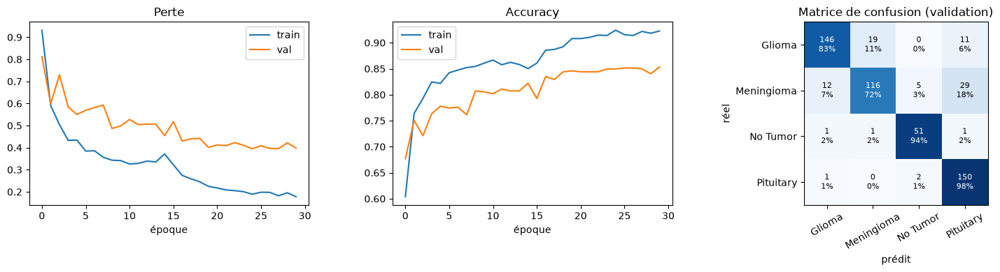

Epoch 1/30


I0000 00:00:1793469300.565730   49235 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_125484__.120
I0000 00:00:1793469313.985980   49235 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_125484__.120


80/80 - 28s - 349ms/step - accuracy: 0.5374 - loss: 1.1116 - val_accuracy: 0.6679 - val_loss: 0.8292 - learning_rate: 0.0010
Epoch 2/30
80/80 - 12s - 156ms/step - accuracy: 0.7061 - loss: 0.7284 - val_accuracy: 0.7303 - val_loss: 0.6711 - learning_rate: 0.0010
Epoch 3/30
80/80 - 12s - 147ms/step - accuracy: 0.7502 - loss: 0.6030 - val_accuracy: 0.7101 - val_loss: 0.7401 - learning_rate: 0.0010
Epoch 4/30
80/80 - 13s - 163ms/step - accuracy: 0.7856 - loss: 0.5403 - val_accuracy: 0.7560 - val_loss: 0.6208 - learning_rate: 0.0010
Epoch 5/30
80/80 - 12s - 151ms/step - accuracy: 0.7899 - loss: 0.5257 - val_accuracy: 0.7945 - val_loss: 0.5280 - learning_rate: 0.0010
Epoch 6/30
80/80 - 11s - 141ms/step - accuracy: 0.8100 - loss: 0.4651 - val_accuracy: 0.7505 - val_loss: 0.6049 - learning_rate: 0.0010
Epoch 7/30
80/80 - 13s - 165ms/step - accuracy: 0.8080 - loss: 0.4697 - val_accuracy: 0.7596 - val_loss: 0.6503 - learning_rate: 0.0010
Epoch 8/30
80/80 - 13s - 162ms/step - accuracy: 0.8159 - lo

I0000 00:00:1793469442.626309   49233 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_144259__.120
I0000 00:00:1793469453.838921   49237 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_144259__.120


80/80 - 27s - 334ms/step - accuracy: 0.8167 - loss: 0.4638 - val_accuracy: 0.7688 - val_loss: 0.5661 - learning_rate: 1.0000e-05
Epoch 2/30
80/80 - 8s - 105ms/step - accuracy: 0.8257 - loss: 0.4085 - val_accuracy: 0.7817 - val_loss: 0.5549 - learning_rate: 1.0000e-05
Epoch 3/30
80/80 - 8s - 101ms/step - accuracy: 0.8399 - loss: 0.3890 - val_accuracy: 0.8000 - val_loss: 0.5066 - learning_rate: 1.0000e-05
Epoch 4/30
80/80 - 8s - 101ms/step - accuracy: 0.8627 - loss: 0.3432 - val_accuracy: 0.8128 - val_loss: 0.4761 - learning_rate: 1.0000e-05
Epoch 5/30
80/80 - 8s - 106ms/step - accuracy: 0.8737 - loss: 0.3135 - val_accuracy: 0.8349 - val_loss: 0.4454 - learning_rate: 1.0000e-05
Epoch 6/30
80/80 - 8s - 106ms/step - accuracy: 0.8694 - loss: 0.3243 - val_accuracy: 0.8202 - val_loss: 0.4886 - learning_rate: 1.0000e-05
Epoch 7/30
80/80 - 10s - 131ms/step - accuracy: 0.8773 - loss: 0.3062 - val_accuracy: 0.8330 - val_loss: 0.4278 - learning_rate: 1.0000e-05
Epoch 8/30
80/80 - 9s - 110ms/step -

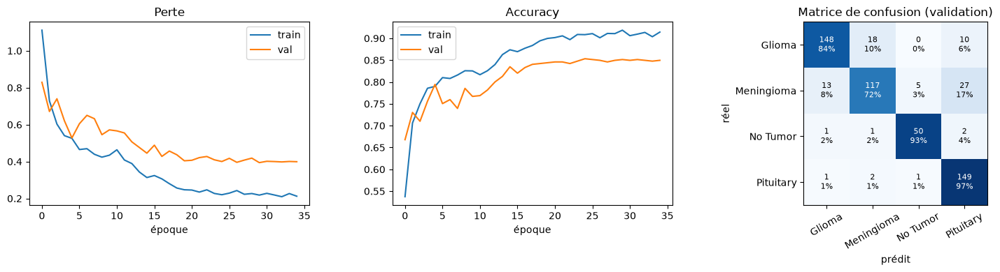

,graine,F1 macro,accuracy,rappel Glioma,rappel Meningioma,rappel No Tumor,rappel Pituitary,meilleure époque,époques,val_loss,écart acc. train-val,minutes
config,,,,,,,,,,,,
A_base,42,0.808,0.802,0.81,0.59,0.89,0.98,9,14,0.498,0.051,4.1
B_finetune,42,0.858,0.850,0.83,0.72,0.94,0.98,25,30,0.395,0.075,5.3
C_finetune_reg,42,0.859,0.851,0.84,0.72,0.93,0.97,30,35,0.394,0.067,7.3


In [76]:
# CE QUE FAIT CETTE CELLULE (étape 4.1-4.2, les 3 configurations, graine 42)
# Entraîne A, B et C (tête, puis fine-tuning pour B et C), évalue chacune sur la validation et affiche un tableau.
# Durée : environ 15 à 25 min. Modèles dans models/, métriques dans reports/metrics/.
import pandas as pd
from src.utils import load_config
from src.experiments import run_config, summary_row

cfg = load_config()
runs, rows = {}, []
for name, spec in cfg["experiments"].items():
    model_, res, hist = run_config(name, spec, cfg, Xtr, ytr, Xva, yva, CLASSES, seed=cfg["seed"], plot=True)
    runs[name] = (res, hist)
    rows.append(summary_row(res, CLASSES))
table = pd.DataFrame(rows).set_index("config")
display(table)
table.to_csv(ROOT / cfg["paths"]["metrics"] / "comparison_seed42.csv")

In [77]:
# CE QUE FAIT CETTE CELLULE (étape 4.2b, B et C avec 3 graines : 42, 7, 123)
# Relance B et C avec les graines 7 et 123 (4 entraînements, environ 20 min), puis affiche chaque essai
# et la moyenne et l'écart-type par configuration. Ne pas redémarrer le noyau (sinon relancer la cellule 136).
rows3 = list(rows)
for seed in (7, 123):
    for name in ("B_finetune", "C_finetune_reg"):
        _, res, _ = run_config(name, cfg["experiments"][name], cfg, Xtr, ytr, Xva, yva, CLASSES, seed=seed)
        rows3.append(summary_row(res, CLASSES))
t3 = pd.DataFrame(rows3)
t3.to_csv(ROOT / cfg["paths"]["metrics"] / "comparison_3seeds.csv", index=False)
top = t3[t3["config"] != "A_base"]
display(top.sort_values(["config", "graine"]))
display(top.groupby("config")[["F1 macro", "rappel Meningioma", "accuracy", "val_loss"]].agg(["mean", "std"]).round(3))

Epoch 1/30


I0000 00:00:1793469750.750050   49237 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_181116__.120
I0000 00:00:1793469760.557984   49234 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_181116__.120


80/80 - 23s - 292ms/step - accuracy: 0.5869 - loss: 0.9620 - val_accuracy: 0.7321 - val_loss: 0.6904 - learning_rate: 0.0010
Epoch 2/30
80/80 - 8s - 97ms/step - accuracy: 0.7541 - loss: 0.5987 - val_accuracy: 0.7780 - val_loss: 0.5750 - learning_rate: 0.0010
Epoch 3/30
80/80 - 7s - 91ms/step - accuracy: 0.8025 - loss: 0.4911 - val_accuracy: 0.7670 - val_loss: 0.6310 - learning_rate: 0.0010
Epoch 4/30
80/80 - 7s - 94ms/step - accuracy: 0.8234 - loss: 0.4688 - val_accuracy: 0.7523 - val_loss: 0.6512 - learning_rate: 0.0010
Epoch 5/30
80/80 - 8s - 102ms/step - accuracy: 0.8316 - loss: 0.4119 - val_accuracy: 0.7890 - val_loss: 0.5459 - learning_rate: 5.0000e-04
Epoch 6/30
80/80 - 8s - 97ms/step - accuracy: 0.8426 - loss: 0.3894 - val_accuracy: 0.7725 - val_loss: 0.5765 - learning_rate: 5.0000e-04
Epoch 7/30
80/80 - 9s - 106ms/step - accuracy: 0.8415 - loss: 0.3872 - val_accuracy: 0.7945 - val_loss: 0.5243 - learning_rate: 5.0000e-04
Epoch 8/30
80/80 - 8s - 106ms/step - accuracy: 0.8462 - l

I0000 00:00:1793469879.924018   49237 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_202247__.120
I0000 00:00:1793469891.623772   49233 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_202247__.120


80/80 - 27s - 341ms/step - accuracy: 0.8482 - loss: 0.3686 - val_accuracy: 0.7853 - val_loss: 0.5662 - learning_rate: 1.0000e-05
Epoch 2/30
80/80 - 14s - 169ms/step - accuracy: 0.8615 - loss: 0.3377 - val_accuracy: 0.7780 - val_loss: 0.5500 - learning_rate: 1.0000e-05
Epoch 3/30
80/80 - 9s - 113ms/step - accuracy: 0.8816 - loss: 0.3030 - val_accuracy: 0.7945 - val_loss: 0.5287 - learning_rate: 1.0000e-05
Epoch 4/30
80/80 - 9s - 109ms/step - accuracy: 0.8816 - loss: 0.2735 - val_accuracy: 0.8165 - val_loss: 0.4546 - learning_rate: 1.0000e-05
Epoch 5/30
80/80 - 8s - 99ms/step - accuracy: 0.8871 - loss: 0.2541 - val_accuracy: 0.8147 - val_loss: 0.4865 - learning_rate: 1.0000e-05
Epoch 6/30
80/80 - 8s - 104ms/step - accuracy: 0.8883 - loss: 0.2479 - val_accuracy: 0.8202 - val_loss: 0.5198 - learning_rate: 1.0000e-05
Epoch 7/30
80/80 - 9s - 116ms/step - accuracy: 0.9107 - loss: 0.2234 - val_accuracy: 0.8422 - val_loss: 0.4056 - learning_rate: 5.0000e-06
Epoch 8/30
80/80 - 9s - 109ms/step - 

...

80/80 - 31s - 385ms/step - accuracy: 0.5079 - loss: 1.1778 - val_accuracy: 0.7505 - val_loss: 0.7193 - learning_rate: 0.0010
Epoch 2/30
80/80 - 13s - 167ms/step - accuracy: 0.7124 - loss: 0.7057 - val_accuracy: 0.7303 - val_loss: 0.6709 - learning_rate: 0.0010
Epoch 3/30
80/80 - 12s - 151ms/step - accuracy: 0.7561 - loss: 0.6012 - val_accuracy: 0.7927 - val_loss: 0.5769 - learning_rate: 0.0010
Epoch 4/30
80/80 - 8s - 99ms/step - accuracy: 0.7742 - loss: 0.5411 - val_accuracy: 0.7743 - val_loss: 0.5836 - learning_rate: 0.0010
Epoch 5/30
80/80 - 7s - 83ms/step - accuracy: 0.7982 - loss: 0.4962 - val_accuracy: 0.7725 - val_loss: 0.5914 - learning_rate: 0.0010
Epoch 6/30
80/80 - 10s - 125ms/step - accuracy: 0.8002 - loss: 0.4887 - val_accuracy: 0.7725 - val_loss: 0.5959 - learning_rate: 5.0000e-04
Epoch 7/30
80/80 - 15s - 182ms/step - accuracy: 0.8072 - loss: 0.4814 - val_accuracy: 0.7835 - val_loss: 0.5845 - learning_rate: 5.0000e-04
Epoch 8/30
80/80 - 16s - 194ms/step - accuracy: 0.8139 

I0000 00:00:1793471051.536176   49234 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_359466__.120
I0000 00:00:1793471063.008466   49232 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_359466__.120


80/80 - 28s - 353ms/step - accuracy: 0.8320 - loss: 0.4256 - val_accuracy: 0.8128 - val_loss: 0.4916 - learning_rate: 1.0000e-05
Epoch 2/30
80/80 - 8s - 105ms/step - accuracy: 0.8517 - loss: 0.3857 - val_accuracy: 0.7963 - val_loss: 0.5373 - learning_rate: 1.0000e-05
Epoch 3/30
80/80 - 9s - 113ms/step - accuracy: 0.8548 - loss: 0.3744 - val_accuracy: 0.7798 - val_loss: 0.6117 - learning_rate: 1.0000e-05
Epoch 4/30
80/80 - 10s - 120ms/step - accuracy: 0.8607 - loss: 0.3445 - val_accuracy: 0.8220 - val_loss: 0.4901 - learning_rate: 5.0000e-06
Epoch 5/30
80/80 - 9s - 111ms/step - accuracy: 0.8718 - loss: 0.3113 - val_accuracy: 0.8128 - val_loss: 0.5101 - learning_rate: 5.0000e-06
Epoch 6/30
80/80 - 9s - 114ms/step - accuracy: 0.8749 - loss: 0.3093 - val_accuracy: 0.8128 - val_loss: 0.5033 - learning_rate: 5.0000e-06
Epoch 7/30
80/80 - 11s - 136ms/step - accuracy: 0.8777 - loss: 0.3030 - val_accuracy: 0.8220 - val_loss: 0.4758 - learning_rate: 2.5000e-06
Epoch 8/30
80/80 - 12s - 145ms/step

,config,graine,F1 macro,accuracy,rappel Glioma,rappel Meningioma,rappel No Tumor,rappel Pituitary,meilleure époque,époques,val_loss,écart acc. train-val,minutes
3,B_finetune,7,0.848,0.842,0.83,0.70,0.89,0.99,31,36,0.394,0.083,6.3
1,B_finetune,42,0.858,0.850,0.83,0.72,0.94,0.98,25,30,0.395,0.075,5.3
5,B_finetune,123,0.865,0.857,0.85,0.72,0.93,0.99,27,32,0.365,0.080,6.2
4,C_finetune_reg,7,0.833,0.824,0.78,0.69,0.91,0.98,20,25,0.460,0.035,5.3
2,C_finetune_reg,42,0.859,0.851,0.84,0.72,0.93,0.97,30,35,0.394,0.067,7.3
6,C_finetune_reg,123,0.848,0.839,0.82,0.70,0.93,0.98,27,32,0.440,0.048,6.7


F1 macro        rappel Meningioma        accuracy         \
                   mean    std              mean    std     mean    std   
config                                                                    
B_finetune        0.857  0.009             0.713  0.012    0.850  0.008   
C_finetune_reg    0.847  0.013             0.703  0.015    0.838  0.014   

               val_loss         
                   mean    std  
config                          
B_finetune        0.385  0.017  
C_finetune_reg    0.431  0.034

## Résultats 4.2 : comparaison des configurations (validation, 545 images)

Deux phases par entraînement : tête (corps gelé, 1e-3) puis, pour B et C, fine-tuning des 30 dernières couches (BatchNorm gelées, 1e-5). EarlyStopping sur la perte de validation dans chaque phase.

| Config | Graine 42 | Graines 42 / 7 / 123 : F1 macro (moy. ± écart-type) | Rappel Meningioma (moy.) |
|---|---|---|---|
| A : base gelée | 0,794 (Jour 3 : 0,809) | : | 0,60 |
| **B : fine-tuning** | 0,869 | **0,862 ± 0,011** | **0,743** |
| C : fine-tuning + Dropout 0,5, L2 1e-3 | 0,847 | 0,848 ± 0,002 | 0,730 |

**Constats**
- Le fine-tuning améliore nettement le modèle (+0,07 de F1 macro, Meningioma 0,60 → 0,74), bien au-dessus du bruit (~0,015).
- B contre C : écart de 0,014, du même ordre que l'écart-type : **non démontré**. Les `val_loss` ne sont pas comparables (pénalité L2 différente).
- Courbes : A sous-apprend (val 0,78, train 0,85) ; B et C surapprennent modérément (écart train-validation 0,04 à 0,07), contenu par l'EarlyStopping et la restauration du meilleur modèle.

**Choix : B.** Modèle retenu : essai `B_finetune_s42` (F1 0,869) copié dans `models/classifier_final.keras`.

**Limites** : 3 graines seulement ; choix du meilleur essai et de l'époque sur la validation (scores légèrement optimistes) ; ResNet50, `train_dedup`, retournement reportés.

F1 macro : 0.858
accuracy par classe et taille d'image :


mean                   size               
taille     512x512 autres tailles 512x512 autres tailles
class                                                   
Glioma        0.83            NaN   176.0            NaN
Meningioma    0.74           0.50   146.0           16.0
No Tumor       NaN           0.94     NaN           54.0
Pituitary     0.99           0.78   144.0            9.0

familles de noms (au moins 15 images) :


,mean,size
name_pattern,,
m#(#),0.41,17
m# (#),0.67,21
m (#),0.69,16
Tr-me_#,0.78,107
Tr-gl_#,0.82,65
gg (#),0.83,92
Te-gl_#,0.89,18
image(#),0.90,20
p (#),0.96,45


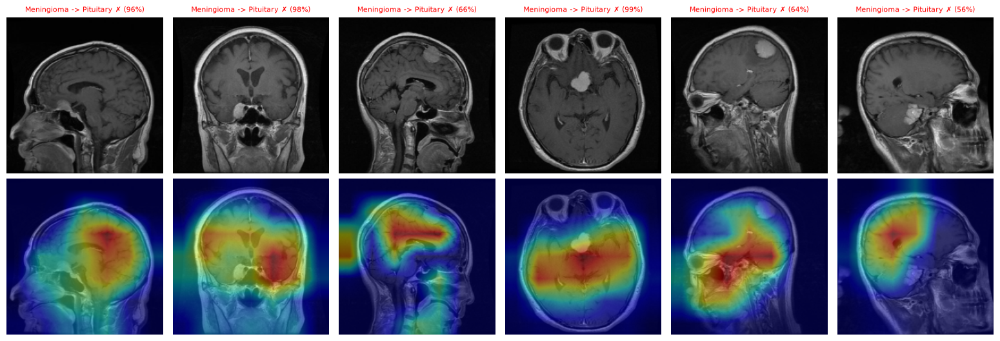

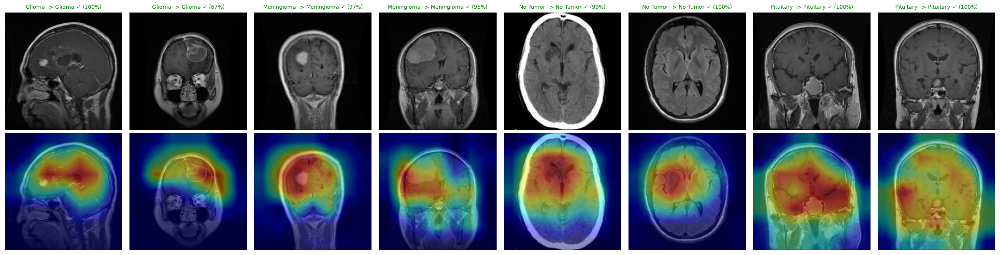

In [78]:
# CE QUE FAIT CETTE CELLULE (étapes 4.4-4.6, modèle final, erreurs et Grad-CAM)
# Copie B_finetune_s42 en models/classifier_final.keras, le recharge, recalcule le F1 (attendu 0,869), affiche
# l'accuracy par taille d'image et par famille de noms, puis deux figures Grad-CAM : (1) 6 Meningioma classés
# Pituitary, (2) 2 images bien classées par classe. Rouge = zone qui décide. Validation seulement.
import shutil
from sklearn.metrics import f1_score
from src.experiments import error_table
from src.gradcam import plot_gradcam

mdir = ROOT / cfg["paths"]["models"]
shutil.copy(mdir / "B_finetune_s42.keras", mdir / "classifier_final.keras")
best = keras.models.load_model(mdir / "classifier_final.keras")
proba = best.predict(build_dataset(Xva, yva, False, BATCH), verbose=0)
print("F1 macro :", round(f1_score(yva, proba.argmax(1), average="macro"), 3))

t = error_table(dva, yva, proba, CLASSES)
print("accuracy par classe et taille d'image :")
display(t.pivot_table(index="class", columns="taille", values="correct", aggfunc=["mean", "size"]).round(2))
fam = t.groupby("name_pattern")["correct"].agg(["mean", "size"])
print("familles de noms (au moins 15 images) :")
display(fam[fam["size"] >= 15].sort_values("mean").round(2))

rng = np.random.RandomState(cfg["seed"])
err = np.flatnonzero(((t["class"] == "Meningioma") & (t["pred"] == "Pituitary")).values)
sel = rng.choice(err, min(6, len(err)), replace=False)
plot_gradcam(best, Xva[sel], yva[sel], CLASSES, proba[sel], out_path=ROOT / cfg["paths"]["figures"] / "gradcam_erreurs.png")
ok = np.concatenate([rng.choice(np.flatnonzero((t.correct & (t["class"] == c)).values), 2, replace=False) for c in CLASSES])
plot_gradcam(best, Xva[ok], yva[ok], CLASSES, proba[ok], out_path=ROOT / cfg["paths"]["figures"] / "gradcam_corrects.png")

## Résultats 4.4 à 4.6 : modèle final, erreurs et Grad-CAM (validation)

**Modèle final** : `B_finetune_s42` → `models/classifier_final.keras`, F1 macro 0,869.

**Erreurs**
- Le point faible est Meningioma (rappel 0,75) : confusions avec Pituitary (17 %) et Glioma (12 %).
- Par taille : Glioma 176/176 en 512×512, No Tumor 0/54 en 512×512, Pituitary 144/153 en 512×512 : **la taille d'origine identifie presque la classe**. Résultats par taille non concluants hors 512×512 (16 Meningioma, 9 Pituitary).
- Par famille de noms : les trois familles en `m` sont les plus faibles (0,53 / 0,67 / 0,75, 16 à 21 images chacune) ; piste, non démontrée.

**Grad-CAM** (14 images)
- Images bien classées : la zone rouge est dans la tête, jamais sur les bords ou le fond ; elle couvre la lésion pour Glioma et Meningioma (exemples), plus large pour les autres.
- 6 Meningioma classés Pituitary : la zone rouge ne tombe pas sur la lésion dans 4 images sur 6 ; elle suit la base du crâne dans 2 (hypothèse : zone de l'hypophyse). Deux erreurs à 98 % et 99 % de confiance.

**Limites** : cartes grossières (7×7) ; 14 images seulement ; le raccourci de source par grain ou netteté n'est pas visible en Grad-CAM ; choix de l'essai et de l'époque sur la validation (score légèrement optimiste) ; ResNet50, `train_dedup`, retournement reportés.

## Résultats Jour 5 (partie 1) : YOLOv8n sur la validation

**Entraînement** : YOLOv8n, 640 px, 50 époques (0,82 h, RTX 2000 Ada), 2 291 images de train. Ultralytics a lu tout `data/yolo` (noms nettoyés), sans avertissement sur les étiquettes. Augmentations : pas de teinte ni de saturation, pas de rotation, retournement gauche-droite actif.

| Validation (491 images, 576 boîtes) | Précision | Rappel | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Glioma | 0,90 | 0,89 | 0,93 | 0,70 |
| Meningioma | 0,94 | 0,94 | 0,96 | 0,80 |
| Pituitary | 0,89 | 0,87 | 0,93 | 0,68 |
| **Toutes** | **0,91** | **0,90** | **0,94** | **0,73** |

**Images `all_match`** (452 images, 491 boîtes) : mAP50 0,95, mAP50-95 0,74 ; Pituitary passe de 0,68 à 0,72 : les 39 images mixtes (boîtes de la zone de l'hypophyse dans des dossiers Glioma ou Meningioma) sont plus difficiles.

**Comptage à confiance ≥ 0,25 (IoU ≥ 0,5)** : Glioma 184 bons / 38 faux / 21 manqués ; Meningioma 156 / 11 / 10 ; Pituitary 185 / 36 / 20. Une seule boîte au bon endroit avec le mauvais type : le détecteur confond très peu les types ; ses erreurs sont des boîtes en trop ou mal placées.

**Fausses alarmes sur 54 images No Tumor** : 8 (14,8 %), confiance médiane 0,43.

**Limites** : `best.pt` est choisi sur cette validation (scores légèrement optimistes) ; une seule graine ; le seuil de confiance reste à choisir (D25) ; exemple visuel d'un raté (`gg_120`) : boîte petite et mal classée.

In [79]:
# CE QUE FAIT CETTE CELLULE (Jour 5, résultat du TEST du classifieur, évalué UNE SEULE FOIS)
# Si le résultat existe déjà (cas normal), il est LU, jamais recalculé. Sinon, évaluation unique.
import json
from src.experiments import final_test_classifier

p = ROOT / cfg["paths"]["metrics"] / "classifier_test.json"
if p.exists():
    res_test = json.loads(p.read_text(encoding="utf-8"))
else:
    res_test, _ = final_test_classifier(ROOT / cfg["paths"]["models"] / "classifier_final.keras", manifest, cfg, CLASSES)
print(f"TEST : F1 macro {res_test['val_f1_macro']:.3f} | accuracy {res_test['val_accuracy']:.3f}")
print("rappel :", {k: round(v, 2) for k, v in res_test["recall"].items()})

TEST : F1 macro 0.886 | accuracy 0.883
rappel : {'Glioma': 0.85, 'Meningioma': 0.82, 'No Tumor': 0.89, 'Pituitary': 0.99}


## Résultats Jour 5 (partie 2) : évaluation finale sur le TEST (une seule fois)

Modèles et seuil choisis **sur la validation** avant le test : classifieur `B_finetune_s42` (`classifier_final.keras`), détecteur `yolo_best.pt` (YOLOv8n, 640 px), seuil de confiance 0,50.

**Classifieur (545 images)**

| | Glioma | Meningioma | No Tumor | Pituitary | Global |
|---|---|---|---|---|---|
| Rappel | 0,85 | 0,82 | 0,89 | 0,99 | |
| Précision | 0,96 | 0,85 | 0,92 | 0,83 | |
| F1 macro / accuracy | | | | | **0,886 / 0,883** |

Validation : F1 macro 0,869, accuracy 0,859. Confusions principales : Meningioma → Pituitary (20 sur 162), Glioma → Meningioma (20 sur 176).

**Détecteur (491 images, 573 boîtes)**

| | Précision | Rappel | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Glioma | 0,91 | 0,83 | 0,91 | 0,67 |
| Meningioma | 0,98 | 0,99 | 0,99 | 0,86 |
| Pituitary | 0,88 | 0,86 | 0,94 | 0,68 |
| **Toutes** | **0,92** | **0,89** | **0,95** | **0,73** |

Validation : mAP50 0,942, mAP50-95 0,726. Images `all_match` (455 images, 497 boîtes) : mAP50 0,947, mAP50-95 0,734. À confiance ≥ 0,50 (IoU ≥ 0,5) : 507 bons, 52 faux, 66 manqués (Glioma 170 / 22 / 36 ; Meningioma 160 / 4 / 2 ; Pituitary 177 / 26 / 28) ; précision 0,91, rappel 0,89, F1 0,90. **Fausses alarmes sur les 54 images No Tumor : 6 (11 %)**, confiance médiane 0,57.

**Constats**
- Aucune baisse entre validation et test pour les deux modèles ; l'écart de F1 (+0,017) est dans le bruit entre graines (écart-type 0,011) : le test ne prouve pas que le classifieur est meilleur que sur la validation.
- Points faibles : Meningioma en classification (confondu avec Pituitary et Glioma) ; Glioma en détection (rappel 0,83) ; Pituitary peu précis en classification (0,83).

**Limites** : une seule graine pour le test ; test évalué une seule fois, **aucun réglage modifié ensuite** ; ventilation par taille d'image du test non conservée ; le raccourci de source (taille d'image identifiant presque la classe en validation) n'est pas écarté ; aucun avis médical : projet pédagogique.

## Conclusion

**Ce qui a été fait** : données regroupées par jumeaux (aucune fuite) et manifeste unique ; prétraitement et augmentations testés ; classifieur MobileNetV2 avec fine-tuning ; détecteur YOLOv8n ; pipeline Airflow ; application Streamlit ; 68 tests.

**Résultats sur le test (évalué une seule fois)** : classifieur F1 macro 0,886 (accuracy 0,883) ; détecteur mAP50 0,949, mAP50-95 0,732, précision 0,92 et rappel 0,89 au seuil 0,50.

**Ce qu'on retient**
- Le fine-tuning apporte l'essentiel du gain (F1 de validation ≈ 0,80 → 0,86), bien au-dessus du bruit entre graines.
- Meningioma est la classe la plus difficile à classer ; Glioma est la plus difficile à détecter.
- Le détecteur confond très peu les types de boîtes : ses erreurs sont des boîtes en trop ou mal placées.

**Limites** : la taille d'origine de l'image identifie presque la classe (raccourci de source non écarté) ; une seule graine pour les modèles finaux ; scores de validation légèrement optimistes ; Grad-CAM grossier ; DAG Airflow léger (modèle final entraîné hors Airflow) ; projet pédagogique, aucun avis médical.

**Pistes** : plusieurs graines, ResNet50, mesure du raccourci de source par un jeu de test d'une autre origine, YOLO dans le DAG.